# N6 · Observaciones múltiples con la regla de rechazo

Los experimentos de observaciones múltiples de N4, repetidos con la regla de rechazo por innovación de N3. La innovación es $d = y_o - \overline{H(x_f)}$, donde $\overline{H(x_f)}$ es la media de $H$ sobre los 59 miembros del prior, cada uno censurado en 0 dBZ antes de promediar; no es $H$ de la media del prior. Se **rechaza** la observación si $0 \le d \le 10$ dBZ, con los dos bordes incluidos, y se asimila todo lo demás. La regla se evalúa una sola vez, sobre el prior, así que TEnKF-T1 a T5 y AOEI asimilan el mismo conjunto. Es la regla `d[0,10]` de N3, sobre el mismo `dep_b`.

Las corridas con la regla son las doce `WS_{A,B,C}_multiobs_{18..21}00_LOC2.0_QC0t10_REF`: iguales a las REF de N4 salvo `qc.dep_band: [0, 10]`, con el mismo código, los mismos 12 miembros verdad, los 6 esquemas y las 4 horas. Sin la regla son las REF de N4, que no se volvieron a correr.

Todo se evalúa sobre los **dominios de N4**, construidos con las observaciones de la línea base, así que con y sin la regla se comparan las mismas celdas. Las definiciones son las de N4: el valor central sale de las sumas de los 12 miembros verdad y las cuatro horas, y la banda es ±1 desviación estándar entre los 12.

La sección 0 es el postprocesado, de las corridas a los intermedios en `data/derived/N6/`. Las celdas de análisis calculan los números; las de figura solo dibujan.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import nbcommon as nb

REBUILD = False           # True: rehace los intermedios de la sección 0 desde las corridas
QUICK = False             # True: prueba barata (A, 20 UTC, un miembro verdad) en data/derived/N6/quick
SHOW = "es"

nb.set_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)

In [2]:
# Etiquetas propias de este notebook; el vocabulario común está en nb.VOCAB.
LABELS = {
    "es": {
        "none": "sin regla", "rule": r"con regla, $0 \leq d \leq 10$ dBZ",
        "retenidas": "observación retenida", "rechazadas": "observación rechazada",
        "clear_reached": "aire claro alcanzado",
        "adv": "ventaja sobre TEnKF-T1", "storm": "tormenta",
        "núcleo": "núcleo", "eco": "eco", "borde": "borde", "aire claro lejano": "aire claro lejano",
        "prior con eco": "prior con eco", "prior sin eco": "prior sin eco",
        "p_t1": "celdas donde el esquema\nmejora a TEnKF-T1", "p_rule": "celdas donde\nla regla mejora",
        "nact": "miembros del prior con señal", "nbr": "parte rechazada del vecindario",
        "sin vecinos": "sin vecinos", "share_obs": "fracción de las observaciones",
        "dw_lin": r"$|\Delta w|$ lineal [m s$^{-1}$]", "tramo": "innovación propia",
        "fe5": r"eco falso ($\geq 5$ dBZ) / prior", "fe20": r"eco falso ($\geq 20$ dBZ) / prior",
        "mass_out": "masa de hidrometeoros fuera\ndel eco / prior", "false_echo": "celdas con eco falso",
        "prior_mean": "media del prior", "rule_short": "con regla",
        "colmax": r"máximo en la columna de la media de $H(\mathbf{x})$ [dBZ]",
        "on_per_obs": "miembros encendidos\npor observación", "single_counts": "observaciones",
        "pooled": "los tres datasets",
        "yo": r"$y_o$", "d_obs": r"$d = y_o - \overline{H(\mathbf{x}^f)}$", "d_dbz": r"$d$ [dBZ]",
        "hx_xbar": r"$H(\bar{\mathbf{x}}^f)$", "hx_max": r"máximo de $H$ en los 59 miembros",
        "prior_mean_h": r"media de $H(\mathbf{x}^f)$", "post_t1": r"media de $H(\mathbf{x}^a)$ [dBZ]",
        "height": "altura [km]", "lat": "latitud", "truth5": "verdad, 5 dBZ",
        "obs_edge": "borde de las celdas observadas", "colmax_yo": r"máx. en la columna de $y_o$",
        "colmax_nact": r"máx. en la columna de $N_{Z>0}$",
        "colmax_xbar": r"máx. en la columna de $H(\bar{\mathbf{x}}^f)$",
        "colmean_d": r"media de $d$ en la columna", "cells": "celdas",
    },
    "en": {
        "none": "without the rule", "rule": r"with the rule, $0 \leq d \leq 10$ dBZ",
        "retenidas": "retained observation", "rechazadas": "rejected observation",
        "clear_reached": "reached clear air",
        "adv": "advantage over TEnKF-T1", "storm": "storm",
        "núcleo": "core", "eco": "echo", "borde": "edge", "aire claro lejano": "far clear air",
        "prior con eco": "prior with echo", "prior sin eco": "prior without echo",
        "p_t1": "cells where the scheme\nbeats TEnKF-T1", "p_rule": "cells improved\nby the rule",
        "nact": "prior members with signal", "nbr": "rejected share of the neighbourhood",
        "sin vecinos": "no neighbours", "share_obs": "share of observations",
        "dw_lin": r"linear $|\Delta w|$ [m s$^{-1}$]", "tramo": "own innovation",
        "fe5": r"false echo ($\geq 5$ dBZ) / prior", "fe20": r"false echo ($\geq 20$ dBZ) / prior",
        "mass_out": "hydrometeor mass outside\nthe echo / prior", "false_echo": "false-echo cells",
        "prior_mean": "prior mean", "rule_short": "with the rule",
        "colmax": r"column maximum of the mean of $H(\mathbf{x})$ [dBZ]",
        "on_per_obs": "members switched on\nper observation", "single_counts": "observations",
        "pooled": "all three datasets",
        "yo": r"$y_o$", "d_obs": r"$d = y_o - \overline{H(\mathbf{x}^f)}$", "d_dbz": r"$d$ [dBZ]",
        "hx_xbar": r"$H(\bar{\mathbf{x}}^f)$", "hx_max": r"maximum of $H$ over the 59 members",
        "prior_mean_h": r"mean of $H(\mathbf{x}^f)$", "post_t1": r"mean of $H(\mathbf{x}^a)$ [dBZ]",
        "height": "height [km]", "lat": "latitude", "truth5": "truth, 5 dBZ",
        "obs_edge": "edge of the observed cells", "colmax_yo": r"column max. of $y_o$",
        "colmax_nact": r"column max. of $N_{Z>0}$",
        "colmax_xbar": r"column max. of $H(\bar{\mathbf{x}}^f)$",
        "colmean_d": r"column mean of $d$", "cells": "cells",
    },
}
assert set(LABELS["es"]) == set(LABELS["en"])

## 0 · Postprocesado

Lee las doce corridas con la regla, las doce REF de N4 y los subsets, y escribe los intermedios en `data/derived/N6/`: `N6_runs`, `N6_masks`, `N6_ref_skill`, `N6_scalars` y `N6_checks`; las secciones 0.2 y 0.3 agregan `N6_classes` y `N6_prior_obs`, para las secciones 8 a 10, las 0.4 y 0.5 agregan `N6_false_echo`, `N6_single_obs` y `N6_single_check`, para las secciones 11 y 12, la 0.6 agrega `N6_obs_bajas` y el caso del mapa (`N6_caso_A_20_tm00.npz`), y la 0.7 agrega `N6_eco_falso_tramos`, `N6_eco_falso_brecha` y `N6_eco_falso_tramos_check`, para la sección 11. De `data/derived/N4/` solo lee, nunca escribe. Usa `N4_runs`, `N4_nan_cells`, `N4_masks`, `N4_ref_skill` y `N4_scalars` para los controles, y `N4_state_prior`, `N4_state_crps` y `N4_state_spread` para el prior del estado en las celdas alcanzadas, que la regla no cambia.

Hay dos pasadas, como en N4.

1. **Por dataset y hora.** Lee el subset por tajadas, para el censo de NaN y los hidrometeoros negativos, y arma por miembro verdad las máscaras de la línea base y las de las observaciones retenidas. La regla se reconstruye desde el `ref` de la línea base, en float32 como en el runner. Tiene que retener exactamente las observaciones que retuvo el runner, en el mismo orden.
2. **Por dataset y miembro verdad.** Abre los campos de las dos versiones en las cuatro horas y calcula las sumas de la reflectividad por dominio, con las mismas columnas que `N4_ref_skill`. La fila agrupada (`hour = all`) suma las cuatro horas. No trae la mediana, que no se obtiene de sumas.

Dominios de la reflectividad, todos dentro de las alcanzadas de la línea base y sin sus celdas excluidas (las NaN del subset y su vecindario, como en N4):

| dominio | celdas |
|---|---|
| `alcanzadas`, `tormenta`, `observadas` | los de N4, idénticos |
| `retenidas` | observadas cuya observación pasa la regla |
| `rechazadas` | observadas cuya observación la regla rechaza |
| `alcance retenidas` | alcanzadas por alguna retenida: lo que la corrida con regla actualiza |
| `solo rechazadas` | alcanzadas solo por rechazadas: lo que la regla deja en el prior |

`retenidas` + `rechazadas` = `observadas` y `alcance retenidas` + `solo rechazadas` = `alcanzadas`.

**El estado**, por cancelación como en N4 §6–7. Los escalares `global` y `storm` del runner cubren el dominio entero y las columnas de tormenta enteras, que no dependen de qué observaciones se asimilaron. La corrida con regla solo cambia celdas al alcance de las retenidas, que están dentro del alcance de la línea base. Entonces $\sum_\mathrm{alc} e_a^2 = \sum_\mathrm{alc} e_f^2 - (\sum_\mathrm{dom} e_f^2 - \sum_\mathrm{dom} e_a^2)$ vale para las dos versiones sobre las celdas alcanzadas de N4, y lo mismo con la varianza y el CRPS. El prior y el denominador son los de N4 en las dos versiones. El método se controla en la reflectividad, donde también existen los campos.

`verify` exige:

- las corridas tienen la banda y todo lo demás igual a N4;
- el censo de NaN, el prior del `ref` (verdad, media del prior, $H$ de la verdad, media de $H$) y los escalares del prior son los de N4;
- la regla deja las observaciones del runner;
- las celdas que alcanzan las retenidas reproducen los `n_touched` del runner;
- fuera de ese alcance el posterior de $Z$ es el prior, bit a bit;
- la cancelación del MSE, la varianza y el CRPS de $Z$ sobre los dominios de la línea base coincide con los campos;
- sin regla, cada fila sobre los dominios de N4 es la de `N4_ref_skill`.

`verify` corre siempre sobre los intermedios en disco, también cuando no se reconstruyen: es barato y detecta un `data/derived/N4/` cambiado después.

En paralelo en Linux (`fork`, seldon) y en serie en macOS, como N4. La segunda pasada lee el doble de archivos que la de N4.

In [3]:
import pathlib
import zipfile
from multiprocessing import get_context

from scipy.spatial import cKDTree

from da.metrics import SKILL_TOL_REF
from naming import qc_code

# ═══════════════════════════════════════════════════════════════════════════
# Configuración
# ═══════════════════════════════════════════════════════════════════════════

OUT4 = pathlib.Path(nb.DERIVED) / "N4"          # solo lectura
OUT = pathlib.Path(nb.DERIVED) / "N6"

DATASETS = ("A", "B", "C")
HOURS    = ("18", "19", "20", "21")
LOC      = 2.0
SCHEMES  = tuple(("TEnKF", n) for n in range(1, 6)) + (("AOEI", 1),)
HYDRO    = ("qg", "qr", "qs")

# La regla: rechaza si BAND[0] ≤ d ≤ BAND[1]. Los nombres son los de N3 (N3_sums_rule).
BAND = (0.0, 10.0)
NONE, RULE = "none", "d[0,10]"
REGLAS = (NONE, RULE)
assert qc_code(BAND) == "QC0t10"

# La banda de empate y el corte de soporte compacto, los de N4.
TOL = nb.TOL["obs"]
assert TOL == SKILL_TOL_REF, "la banda de empate no es la del runner"
MAXD2 = (2.0 * np.sqrt(10.0 / 3.0)) ** 2

DOMAINS = ("alcanzadas", "tormenta", "observadas")
PARTS = ("retenidas", "rechazadas", "alcance retenidas", "solo rechazadas")
DOMAINS6 = DOMAINS + PARTS

# Tolerancias. Las de N4 donde el control es el mismo.
RUNNER_SKILL_ATOL = 1e-4          # dBZ por celda: la skill sumada del runner (float32) contra los campos
MSE_FORMULA_RTOL = 1e-9           # cancelación del MSE de Z (observado ~5e-15)
SPREAD_RTOL = 1e-6                # cancelación de la varianza de Z (observado ~4e-15)
CRPS_RTOL = 1e-6                  # cancelación del CRPS de Z (observado ~1e-9)
PRIOR_SCALAR_RTOL = 1e-9          # escalares del prior, con y sin regla (observado 0)
N4_RTOL = 1e-12                   # sin regla contra N4_ref_skill: las mismas sumas

SLAB_CELLS = 100_000              # celdas por tajada del subset (~190 MB)

# En paralelo solo con fork (Linux): con spawn (macOS) los workers no encuentran las
# funciones del notebook. Memoria por worker: máscaras, los hidrometeoros negativos por
# miembro (C: ~0,4 GB) más una tajada; skill, los campos de una corrida (C: ~2 GB).
PARALLEL = sys.platform.startswith("linux")
N_WORKERS_MASKS = 4
N_WORKERS_SKILL = 6


def pmap(func, jobs, n_workers):
    if not PARALLEL or n_workers <= 1 or len(jobs) <= 1:
        return [func(j) for j in jobs]
    with get_context("fork").Pool(min(n_workers, len(jobs))) as p:
        return p.map(func, jobs)


FILES = ("N6_runs.csv", "N6_masks.csv", "N6_ref_skill.csv", "N6_scalars.csv", "N6_checks.csv")
N4_NEEDED = ("N4_runs.csv", "N4_nan_cells.csv", "N4_masks.csv", "N4_ref_skill.csv", "N4_scalars.csv",
             "N4_state_prior.csv", "N4_state_crps.csv", "N4_state_spread.csv")
_falta = [f for f in N4_NEEDED if not (OUT4 / f).exists()]
assert not _falta, f"faltan intermedios de N4 en {OUT4}: {_falta}. Correr N4 primero."


def lab(method, ntemp):
    return "AOEI" if method == "AOEI" else f"TEnKF-T{int(ntemp)}"


def tag_of(ds, hh, regla=NONE):
    base = f"WS_{ds}_multiobs_{hh}00_LOC{LOC}_REF"
    return base if regla == NONE else base.replace("_REF", f"_{qc_code(BAND)}_REF")


def truth_members():
    """Los miembros verdad, de las configs de las 24 corridas; tienen que coincidir."""
    tms = {tuple(nb.run_config(tag_of(ds, hh, rg))["sweep"]["truth_members"])
           for ds in DATASETS for hh in HOURS for rg in REGLAS}
    assert len(tms) == 1, f"las corridas no usan los mismos miembros verdad: {tms}"
    return tms.pop()


TMS_ALL = truth_members()
TMS = TMS_ALL
if QUICK:
    DATASETS, HOURS, TMS = ("A",), ("20",), TMS_ALL[:1]
    OUT = OUT / "quick"
    REBUILD = True


def scheme_file(ds, hh, regla, method, ntemp, tm):
    tag = tag_of(ds, hh, regla)
    f = sorted(nb.run_dir(tag).glob(f"{tag}_multi_obs_{method}_Nt{ntemp:02d}_*_Ne059_tm{tm:02d}.npz"))
    assert len(f) == 1, f"{tag} {method}-T{ntemp} tm{tm:02d}: {len(f)} archivos"
    return f[0]


def ref_file(ds, hh, regla, tm):
    tag = tag_of(ds, hh, regla)
    return nb.run_dir(tag) / f"{tag}_multi_obs_ref_Ne059_tm{tm:02d}.npz"


def within(pos, L, pts):
    """Celdas (nx, ny, nz) a d² ≤ MAXD2 de alguno de los puntos (n, 3) en km (N4)."""
    if len(pts) == 0:
        return np.zeros(pos.shape[:3], bool)
    dist, _ = cKDTree(pts / L).query(pos.reshape(-1, 3) / L, k=1,
                                    distance_upper_bound=np.sqrt(MAXD2) * 1.01)
    return (dist ** 2 <= MAXD2).reshape(pos.shape[:3])


def subset_slabs(path, n_cells):
    """state_ensemble del subset por tajadas de filas de x: (i0, (k, ny, nz, 60, 8)) (N4)."""
    with zipfile.ZipFile(path) as zf, zf.open("state_ensemble.npy") as f:
        version = np.lib.format.read_magic(f)
        shape, fortran, dtype = (np.lib.format.read_array_header_1_0(f) if version == (1, 0)
                                 else np.lib.format.read_array_header_2_0(f))
        assert not fortran, "state_ensemble en orden Fortran"
        row = int(np.prod(shape[1:])) * dtype.itemsize
        rows = max(1, n_cells // int(np.prod(shape[1:3])))
        for i0 in range(0, shape[0], rows):
            k = min(rows, shape[0] - i0)
            buf = f.read(k * row)
            assert len(buf) == k * row, "subset truncado"
            yield i0, np.frombuffer(buf, dtype).reshape((k,) + tuple(shape[1:]))


def scalars_of(z):
    return {k: z[k].item() for k in z.files if z[k].ndim == 0 and z[k].dtype.kind in "biuf"}


def dom_sum_var(sc, side, dom, v):
    """Σ var de un dominio desde el escalar del runner: n·spread²·Ne/(Ne+1) (N4)."""
    ne = sc["Ne"]
    return sc[f"n_spread_{side}_{dom}_{v}"] * sc[f"spread_{side}_{dom}_{v}"] ** 2 * ne / (ne + 1.0)


def in_scope(df):
    """Las filas que cubre este notebook; con QUICK, sin las filas agrupadas de N4."""
    keep = df.dataset.isin(DATASETS)
    if "hour" in df:
        keep &= df.hour.isin(HOURS) | ((df.hour == "all") & (not QUICK))
    if "tm" in df:
        keep &= df.tm.isin(TMS)
    return df[keep]


def read4(name):
    """Un intermedio de N4, solo lectura."""
    return in_scope(pd.read_csv(OUT4 / name, dtype={"hour": str}, float_precision="round_trip"))


def rel(p):
    """Una ruta para imprimir, relativa al repositorio cuando está adentro."""
    try:
        return f"{nb.REPO.name}/{pathlib.Path(p).relative_to(nb.REPO)}"
    except ValueError:
        return str(p)

In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# Pasada 1: máscaras, por dataset y hora
# ═══════════════════════════════════════════════════════════════════════════

# El prior que la corrida con regla tiene que compartir con la línea base, en el ref.
PRIOR_KEYS = ("truth", "xf_mean", "truth_hx_field", "hxf_mean_field")


def domain_masks6(valid, storm, obs, obs_ret, reach_ret):
    return {"alcanzadas": valid,
            "tormenta": valid & storm,
            "observadas": valid & obs,
            "retenidas": valid & obs_ret,
            "rechazadas": valid & obs & ~obs_ret,
            "alcance retenidas": valid & reach_ret,
            "solo rechazadas": valid & ~reach_ret}


def masks_one(job):
    ds, hh = job
    base, qc = tag_of(ds, hh, NONE), tag_of(ds, hh, RULE)
    L = float(nb.run_config(base)["sweep"]["loc_x"])
    sw = nb.run_config(qc)["sweep"]
    assert L == LOC == sw["loc_x"] == sw["loc_y"] == sw["loc_z"], "localización distinta o no isotrópica"
    path = nb.subset_path(hh, ds)
    with np.load(path) as f:
        assert str(f["dataset_id"]) == ds
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    shape = pos.shape[:3]
    # Censo de NaN e hidrometeoros negativos por miembro, por tajadas del subset.
    bad = np.zeros(shape, bool)
    negq = None
    for i0, sl in subset_slabs(path, SLAB_CELLS):
        s = slice(i0, i0 + sl.shape[0])
        bad[s] = ~np.isfinite(sl).all(axis=(3, 4))
        if negq is None:
            negq = np.zeros(shape + (sl.shape[3],), bool)
        negq[s] = (sl[..., [nb.VI[q] for q in HYDRO]] < 0).any(axis=4)
    # el censo de NaN tiene que ser el de N4
    nan4 = read4("N4_nan_cells.csv")
    nan4 = nan4[(nan4.dataset == ds) & (nan4.hour == hh)]
    bad4 = np.zeros(shape, bool)
    bad4[nan4.i, nan4.j, nan4.k] = True
    same_nan = bool(np.array_equal(bad, bad4))

    rows, packed = [], {}
    for tm in TMS:
        with np.load(ref_file(ds, hh, NONE, tm)) as r:
            assert int(r["truth_member"]) == tm and str(r["dataset_id"]) == ds
            assert not bool(r["qc_dep_band_active"]), f"{base}: la línea base tiene banda"
            ix, iy, iz, yo = r["ix"], r["iy"], r["iz"], r["yo"]
            prior_b = {k: r[k] for k in PRIOR_KEYS}
        # La regla, en float32 menos float32 como en run_experiment._setup, para que los
        # bordes caigan donde caen en el runner.
        d = (yo - prior_b["hxf_mean_field"][ix, iy, iz]).astype(np.float32)
        rej = (d >= BAND[0]) & (d <= BAND[1])
        keep = ~rej
        with np.load(ref_file(ds, hh, RULE, tm)) as r:
            assert int(r["truth_member"]) == tm and str(r["dataset_id"]) == ds
            assert bool(r["qc_dep_band_active"]) and \
                np.array_equal(r["qc_dep_band"], np.asarray(BAND, np.float32)), f"{qc}: otra banda"
            same_ref = all(np.array_equal(r[k], prior_b[k], equal_nan=True) for k in PRIOR_KEYS)
            # _setup conserva el orden de las observaciones: las retenidas, en el mismo orden
            same_obs = all(np.array_equal(r[k], v[keep])
                           for k, v in (("ix", ix), ("iy", iy), ("iz", iz), ("yo", yo)))
            n_rej_runner = int(r["n_obs_rejected_by_band"])
        P = pos[ix, iy, iz]
        reach = within(pos, L, P)
        reach_ret = within(pos, L, P[keep])
        on_bad = bad[ix, iy, iz]
        excl = bad | within(pos, L, P[on_bad])
        dm = nb.domain_masks(prior_b["truth_hx_field"], obs_ijk=(ix, iy, iz),
                             storm_thresh=nb.STORM_THRESH_DBZ)
        obs_ret = np.zeros(shape, bool)
        obs_ret[ix[keep], iy[keep], iz[keep]] = True
        others = [m for m in range(negq.shape[3]) if m != tm]
        negq_out_ret = int((negq[..., others].any(axis=3) & ~reach_ret).sum())
        dmask = domain_masks6(reach & ~excl, dm["storm"], dm["obs"], obs_ret, reach_ret)
        row = dict(dataset=ds, hour=hh, tm=tm, n_obs=len(ix), n_retenidas_obs=int(keep.sum()),
                   n_rechazadas_obs=int(rej.sum()), n_rechazadas_runner=n_rej_runner,
                   n_d_zero=int((d == 0).sum()), n_d_ten=int((d == BAND[1]).sum()),
                   same_nan=same_nan, same_ref=same_ref, same_obs=same_obs,
                   n_cells=int(np.prod(shape)), n_nan_cells=int(bad.sum()),
                   n_obs_on_nan=int(on_bad.sum()), n_obs_cells=int(dm["obs"].sum()),
                   n_obs_ret_cells=int(obs_ret.sum()), n_negq_outside_ret=negq_out_ret,
                   reach_ret_in_reach=bool((reach_ret <= reach).all()),
                   n_reach=int(reach.sum()), n_reach_ret=int(reach_ret.sum()),
                   n_reach_ret_storm=int((reach_ret & dm["storm"]).sum()),
                   n_reach_ret_obs=int((reach_ret & obs_ret).sum()))
        row.update({f"n_{dn}": int(m.sum()) for dn, m in dmask.items()})
        # lo que el runner con regla dice que alcanzó, en los seis esquemas
        touched = []
        for m, nt in SCHEMES:
            with np.load(scheme_file(ds, hh, RULE, m, nt, tm)) as z:
                touched.append({k: int(z[f"n_touched_{k}"]) for k in ("global", "storm", "obs")})
        for k in ("global", "storm", "obs"):
            row[f"qc_touched_min_{k}"] = min(t[k] for t in touched)
            row[f"qc_touched_max_{k}"] = max(t[k] for t in touched)
        rows.append(row)
        packed[tm] = {k: np.packbits(v.ravel()) for k, v in
                      (("reach", reach), ("reach_ret", reach_ret), ("excl", excl),
                       ("storm", dm["storm"]), ("obs", dm["obs"]), ("obs_ret", obs_ret))}
    print(f"  máscaras {ds} {hh}", flush=True)
    return ds, hh, shape, rows, packed

In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# Pasada 2: skill de la reflectividad, por dataset y miembro verdad
# ═══════════════════════════════════════════════════════════════════════════

SUM_COLS = ("sum_err2_f", "sum_err2_a", "sum_crps_f", "sum_crps_a", "sum_var_f", "sum_var_a")
COUNT_COLS = ("n", "n_improved", "n_degraded", "n_tie")
FIELDS = ("err_hxf_field", "residual_field", "crps_f_ref_field", "crps_a_ref_field",
          "spread_f_ref_field", "spread_a_ref_field")
SKILL_KEY = ["dataset", "tm", "regla", "method", "ntemp", "domain"]


def cell_stats(s, ef, ea, cf, ca, sf, sa):
    """Estadísticos de un conjunto de celdas, los de N4. s = |err prior| − |err posterior|."""
    n = s.size
    ch = s[np.abs(s) > TOL]
    return dict(n=n, n_improved=int((s > TOL).sum()), n_degraded=int((s < -TOL).sum()),
                n_tie=int((np.abs(s) <= TOL).sum()),
                mean=float(s.mean()) if n else np.nan,
                median=float(np.median(s)) if n else np.nan,
                median_changed=float(np.median(ch)) if ch.size else np.nan,
                sum_err2_f=float((ef ** 2).sum()), sum_err2_a=float((ea ** 2).sum()),
                sum_crps_f=float(cf.sum()), sum_crps_a=float(ca.sum()),
                sum_var_f=float((sf ** 2).sum()), sum_var_a=float((sa ** 2).sum()))


def pool_hours(hr):
    """La fila agrupada de las cuatro horas, desde las sumas. Sin mediana: no sale de sumas."""
    g = hr.assign(_s=hr["mean"].fillna(0.0) * hr["n"]).groupby(SKILL_KEY, sort=False)
    a = g[list(COUNT_COLS) + list(SUM_COLS) + ["_s"]].sum().reset_index()
    a["mean"] = np.where(a.n > 0, a._s / a.n.where(a.n > 0, 1), np.nan)
    return a.drop(columns="_s").assign(hour="all", median=np.nan, median_changed=np.nan)


def n_differ(a, b, msk):
    """Celdas de msk donde a y b difieren (dos NaN cuentan como iguales)."""
    same = (a == b) | (np.isnan(a) & np.isnan(b))
    return int((~same & msk).sum())


def skill_one(job):
    ds, tm, shapes, packed = job
    rows, scal, chk = [], [], []
    for hh in HOURS:
        P = {k: np.unpackbits(v, count=int(np.prod(shapes[hh]))).reshape(shapes[hh]).astype(bool)
             for k, v in packed[(ds, hh, tm)].items()}
        dmask = domain_masks6(P["reach"] & ~P["excl"], P["storm"], P["obs"], P["obs_ret"], P["reach_ret"])
        # los dominios geométricos de la línea base, sin exclusiones, para la cancelación
        raw = {"global": P["reach"], "storm": P["reach"] & P["storm"]}
        out_ret = ~P["reach_ret"]
        prior0 = None
        for rg in REGLAS:
            for m, nt in SCHEMES:
                with np.load(scheme_file(ds, hh, rg, m, nt, tm), allow_pickle=True) as z:
                    assert str(z["method"]) == m and int(z["ntemp"]) == nt and int(z["truth_member"]) == tm
                    assert bool(z["qc_dep_band_active"]) == (rg == RULE)
                    F = {k: z[k].astype(np.float64) for k in FIELDS}
                    sc = scalars_of(z)
                ef, ea, cf, ca, sf, sa = (F[k] for k in FIELDS)
                # el prior es el mismo para los seis esquemas y las dos versiones
                pr = (ef, cf, sf)
                if prior0 is None:
                    prior0 = pr
                same_prior = all(np.array_equal(a, b) for a, b in zip(pr, prior0))
                s = np.abs(ef) - np.abs(ea)
                assert np.isfinite(s).all(), f"{ds} {hh} tm{tm} {rg} {m}-T{nt}: skill no finita"
                for dn, msk in dmask.items():
                    a = [x[msk] for x in (s, ef, ea, cf, ca, sf, sa)]
                    rows.append(dict(dataset=ds, tm=tm, hour=hh, regla=rg, method=m, ntemp=nt,
                                     domain=dn, **cell_stats(*a)))
                c = dict(dataset=ds, hour=hh, tm=tm, regla=rg, method=m, ntemp=nt,
                         same_prior=same_prior,
                         # con la regla, fuera del alcance de las retenidas el posterior es el prior
                         n_untouched_diff=(sum(n_differ(x, y, out_ret) for x, y in ((ea, ef), (ca, cf), (sa, sf)))
                                           if rg == RULE else -1))
                # La cancelación sobre los dominios de la línea base: lo que los escalares
                # del runner dan por resta, contra lo que dan los campos en esas celdas.
                for rd, msk in raw.items():
                    q_run = (sc[f"n_rmse_f_{rd}_ref"] * sc[f"rmse_f_{rd}_ref"] ** 2
                             - sc[f"n_rmse_a_{rd}_ref"] * sc[f"rmse_a_{rd}_ref"] ** 2)
                    q_fld = (ef[msk] ** 2 - ea[msk] ** 2).sum()
                    c[f"mse_rel_{rd}"] = abs(q_run - q_fld) / abs(q_fld)
                    dvar = dom_sum_var(sc, "f", rd, "ref") - dom_sum_var(sc, "a", rd, "ref")
                    va_fld = (sa[msk] ** 2).sum()
                    c[f"var_rel_{rd}"] = abs((sf[msk] ** 2).sum() - dvar - va_fld) / va_fld
                    dc_run = (sc[f"n_crps_f_{rd}_ref"] * sc[f"crps_f_{rd}_ref"]
                              - sc[f"n_crps_a_{rd}_ref"] * sc[f"crps_a_{rd}_ref"])
                    dc_fld = (cf[msk] - ca[msk]).sum()
                    c[f"crps_rel_{rd}"] = abs(dc_run - dc_fld) / abs(dc_fld)
                    # la skill sumada, por celda alcanzada de la línea base
                    s_run = sc[f"n_skill_{rd}_ref"] * sc[f"skill_mean_{rd}_ref"]
                    c[f"d_skillsum_{rd}"] = abs(s_run - s[msk].sum()) / max(int(msk.sum()), 1)
                chk.append(c)
                if rg == RULE:            # los de la línea base ya están en N4_scalars.csv
                    scal.append({"dataset": ds, "hour": hh, "tm": tm, "method": m, **sc})
    rows += pool_hours(pd.DataFrame(rows)).to_dict("records")
    print(f"  skill {ds} tm{tm:02d}", flush=True)
    return rows, scal, chk

In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# Construcción y verificación
# ═══════════════════════════════════════════════════════════════════════════

def build():
    OUT.mkdir(parents=True, exist_ok=True)
    runs = []
    for ds in DATASETS:
        for hh in HOURS:
            tag = tag_of(ds, hh, RULE)
            cfg = nb.run_config(tag)
            runs.append(dict(dataset=ds, hour=hh, tag=tag, R=nb.obs_error_var(tag),
                             dbz_min=nb.dbz_min_of(tag), clamp=cfg["assimilation"]["clamp_hydro"],
                             loc=cfg["sweep"]["loc_x"],
                             band_lo=float(cfg["qc"]["dep_band"][0]), band_hi=float(cfg["qc"]["dep_band"][1]),
                             n_files=len(list(nb.run_dir(tag).glob("*.npz"))),
                             storm_thresh=nb.STORM_THRESH_DBZ))
    RUNS = pd.DataFrame(runs)

    jobs = [(ds, hh) for ds in DATASETS for hh in HOURS]
    res = pmap(masks_one, jobs, N_WORKERS_MASKS)
    shapes = {ds: {} for ds in DATASETS}
    packed, mrows = {}, []
    for ds, hh, shape, rows, pk in res:
        shapes[ds][hh] = shape
        mrows += rows
        for tm, v in pk.items():
            packed[(ds, hh, tm)] = v
    MASKS = pd.DataFrame(mrows)

    jobs = [(ds, tm, shapes[ds], {k: v for k, v in packed.items() if k[0] == ds and k[2] == tm})
            for ds in sorted(DATASETS, key=lambda d: d != "C") for tm in TMS]   # C primero: el más lento
    res = pmap(skill_one, jobs, N_WORKERS_SKILL)
    SK = pd.DataFrame(sum([r[0] for r in res], []))
    SCAL = pd.DataFrame(sum([r[1] for r in res], []))
    CHK = pd.DataFrame(sum([r[2] for r in res], []))

    for name, df in (("N6_runs", RUNS), ("N6_masks", MASKS), ("N6_ref_skill", SK),
                     ("N6_scalars", SCAL), ("N6_checks", CHK)):
        df.to_csv(OUT / f"{name}.csv", index=False)


def verify(RUNS, MASKS, SK, SCAL, CHK):
    # Las corridas: completas, con la banda, y con todo lo demás igual a la línea base.
    assert (RUNS.n_files == len(TMS_ALL) * (len(SCHEMES) + 1)).all(), "faltan archivos"
    assert ((RUNS.band_lo == BAND[0]) & (RUNS.band_hi == BAND[1])).all(), "otra banda"
    R4 = read4("N4_runs.csv")
    for c in ("R", "dbz_min", "clamp", "loc", "storm_thresh"):
        assert RUNS[c].nunique() == 1 and (R4[c] == RUNS[c].iloc[0]).all(), f"{c} distinto de N4"

    # El prior y las observaciones, los de la línea base; la regla, la del runner.
    M = MASKS
    assert len(M) == len(DATASETS) * len(HOURS) * len(TMS)
    for c in ("same_nan", "same_ref", "same_obs", "reach_ret_in_reach"):
        assert M[c].all(), f"{c} falla en {int((~M[c]).sum())} casos"
    assert (M.n_rechazadas_obs == M.n_rechazadas_runner).all(), "la regla no rechaza lo que el runner"
    assert (M.n_retenidas_obs + M.n_rechazadas_obs == M.n_obs).all()
    assert (M.n_obs_cells == M.n_obs).all() and (M.n_obs_ret_cells == M.n_retenidas_obs).all(), \
        "dos observaciones en una celda"
    # los dominios de N4, idénticos
    m4 = M.merge(read4("N4_masks.csv"), on=["dataset", "hour", "tm"], suffixes=("", "_n4"), validate="one_to_one")
    assert len(m4) == len(M)
    for c in ("n_obs", "n_nan_cells", "n_obs_on_nan", "n_alcanzadas", "n_tormenta", "n_observadas"):
        assert (m4[c] == m4[f"{c}_n4"]).all(), f"{c} no es el de N4"
    assert (m4.n_reach == m4.n_reach_alcanzadas).all()
    # las particiones suman
    assert (M.n_retenidas + M.n_rechazadas == M.n_observadas).all()
    assert (M["n_alcance retenidas"] + M["n_solo rechazadas"] == M.n_alcanzadas).all()
    # Lo que alcanzó la corrida con regla: la geometría de las retenidas reproduce al
    # runner, exacto en tormenta y en sus observadas; en el global, salvo las celdas con
    # hidrometeoros negativos fuera del alcance (N4).
    for k, geo in (("storm", "n_reach_ret_storm"), ("obs", "n_reach_ret_obs")):
        assert (M[f"qc_touched_min_{k}"] == M[geo]).all() and (M[f"qc_touched_max_{k}"] == M[geo]).all(), \
            f"celdas alcanzadas por las retenidas en {k} no reproducen al runner"
    assert (M.n_reach_ret_obs == M.n_retenidas_obs).all()
    dmin, dmax = M.qc_touched_min_global - M.n_reach_ret, M.qc_touched_max_global - M.n_reach_ret
    assert (dmin >= 0).all() and (dmax <= M.n_negq_outside_ret).all(), \
        "celdas alcanzadas de más en el global que los hidrometeoros negativos no explican"

    # Los campos: prior común, posterior = prior fuera del alcance de las retenidas, y la
    # cancelación de los escalares sobre los dominios de la línea base.
    assert len(CHK) == len(DATASETS) * len(HOURS) * len(TMS) * len(REGLAS) * len(SCHEMES)
    assert CHK.same_prior.all(), "el prior difiere entre esquemas o entre versiones"
    q = CHK[CHK.regla == RULE]
    assert (q.n_untouched_diff == 0).all(), \
        f"posterior distinto del prior fuera del alcance en {int((q.n_untouched_diff > 0).sum())} archivos"
    for rd in ("global", "storm"):
        assert (CHK[f"mse_rel_{rd}"] <= MSE_FORMULA_RTOL).all(), f"cancelación del MSE en {rd}"
        assert (CHK[f"var_rel_{rd}"] <= SPREAD_RTOL).all(), f"cancelación de la varianza en {rd}"
        assert (CHK[f"crps_rel_{rd}"] <= CRPS_RTOL).all(), f"cancelación del CRPS en {rd}"
        assert (CHK[f"d_skillsum_{rd}"] <= RUNNER_SKILL_ATOL).all(), f"suma de la skill en {rd}"

    # Los escalares del prior: los de N4, en los mismos dominios. Y la cancelación pide el
    # mismo conjunto de celdas en el prior y el posterior.
    k = ["dataset", "hour", "tm", "method", "ntemp"]
    x = SCAL.merge(read4("N4_scalars.csv"), on=k, suffixes=("", "_n4"), validate="one_to_one")
    assert len(x) == len(SCAL) == len(DATASETS) * len(HOURS) * len(TMS) * len(SCHEMES), "los escalares no se aparean"
    worst = 0.0
    for v in list(nb.VARS) + ["ref"]:
        for dom in ("global", "storm"):
            for st in ("rmse", "spread", "crps"):
                c = f"{st}_f_{dom}_{v}"
                assert (x[f"n_{c}"] == x[f"n_{c}_n4"]).all(), f"{c}: otro dominio"
                worst = max(worst, float((np.abs(x[c] - x[f"{c}_n4"]) / np.abs(x[f"{c}_n4"])).max()))
                assert (SCAL[f"n_{st}_a_{dom}_{v}"] == SCAL[f"n_{c}"]).all(), f"{c}: n del posterior"
    assert worst <= PRIOR_SCALAR_RTOL, f"el prior de los escalares difiere de N4 en {worst:.1e}"

    # La skill: sin regla, en los dominios de N4, es la de N4.
    s4 = read4("N4_ref_skill.csv")
    key = ["dataset", "tm", "hour", "method", "ntemp", "domain"]
    mine = SK[(SK.regla == NONE) & SK.domain.isin(DOMAINS) & SK.hour.isin(s4.hour.unique())]
    a = mine.merge(s4, on=key, suffixes=("", "_n4"), validate="one_to_one")
    assert len(a) == len(mine) == len(s4), "sin regla, las filas no son las de N4"
    for c in COUNT_COLS:
        assert (a[c] == a[f"{c}_n4"]).all(), f"sin regla, {c} no es el de N4"
    h = a[a.hour != "all"]
    for c in ("mean", "median", "median_changed") + SUM_COLS:
        assert np.allclose(h[c], h[f"{c}_n4"], rtol=N4_RTOL, atol=0, equal_nan=True), f"sin regla, {c} no es el de N4"
    h = a[a.hour == "all"]
    for c in SUM_COLS:
        assert np.allclose(h[c], h[f"{c}_n4"], rtol=N4_RTOL, atol=0), f"sin regla, {c} agrupado no es el de N4"

    # Completo, particiones, y nada cambia donde la regla no llega.
    assert (SK.n_improved + SK.n_degraded + SK.n_tie == SK.n).all()
    w = SK.pivot_table(index=["dataset", "tm", "hour", "regla", "method", "ntemp"], columns="domain",
                       values="n", aggfunc="sum")
    assert (w.retenidas + w.rechazadas == w.observadas).all()
    assert (w["alcance retenidas"] + w["solo rechazadas"] == w.alcanzadas).all()
    sr = SK[(SK.regla == RULE) & (SK.domain == "solo rechazadas")]
    assert (sr.n_improved == 0).all() and (sr.n_degraded == 0).all() and \
        (sr.sum_err2_a == sr.sum_err2_f).all() and (sr.sum_crps_a == sr.sum_crps_f).all(), \
        "la regla cambia celdas que no alcanza"
    g = SK[SK.hour != "all"].groupby(SKILL_KEY).size()
    assert g.eq(len(HOURS)).all()
    assert len(g) == (SK.hour == "all").sum() == len(DATASETS) * len(TMS) * len(REGLAS) * len(SCHEMES) * len(DOMAINS6)
    return worst


missing = [f for f in FILES if not (OUT / f).exists()]
if REBUILD or missing:
    print(f"construyendo ({len(missing)} archivos faltan)" if missing else "REBUILD")
    build()
else:
    print(f"intermedios presentes en {rel(OUT)}")


def load():
    return {f[:-4]: pd.read_csv(OUT / f, dtype={"hour": str}, float_precision="round_trip") for f in FILES}


N6 = load()
RUNS6, MASKS6, SK6, SCAL6, CHK6 = (N6[f"N6_{k}"] for k in ("runs", "masks", "ref_skill", "scalars", "checks"))
_worst = verify(RUNS6, MASKS6, SK6, SCAL6, CHK6)
print(f"verificado: {len(RUNS6)} corridas con regla, {(CHK6.regla == RULE).sum()} archivos de esquema, "
      f"{int(MASKS6.n_rechazadas_obs.sum()):,} de {int(MASKS6.n_obs.sum()):,} observaciones rechazadas")
print(f"  cancelación de Z, máx dif. relativa: MSE {CHK6.filter(like='mse_rel_').max().max():.1e}, "
      f"varianza {CHK6.filter(like='var_rel_').max().max():.1e}, CRPS {CHK6.filter(like='crps_rel_').max().max():.1e}; "
      f"escalares del prior contra N4 {_worst:.1e}")
print(RUNS6.assign(dataset=RUNS6.dataset.map(nb.DS_LABEL)).to_string(index=False))

intermedios presentes en WRF_Single_Cycle_Assimilation/data/derived/N6


verificado: 12 corridas con regla, 864 archivos de esquema, 57,073,286 de 212,682,583 observaciones rechazadas
  cancelación de Z, máx dif. relativa: MSE 2.9e-13, varianza 6.5e-14, CRPS 8.7e-08; escalares del prior contra N4 0.0e+00
   dataset hour                                  tag   R  dbz_min    clamp  loc  band_lo  band_hi  n_files  storm_thresh
4 km–5 min   18 WS_A_multiobs_1800_LOC2.0_QC0t10_REF 5.0      0.0 per_step  2.0      0.0     10.0       84          20.0
4 km–5 min   19 WS_A_multiobs_1900_LOC2.0_QC0t10_REF 5.0      0.0 per_step  2.0      0.0     10.0       84          20.0
4 km–5 min   20 WS_A_multiobs_2000_LOC2.0_QC0t10_REF 5.0      0.0 per_step  2.0      0.0     10.0       84          20.0
4 km–5 min   21 WS_A_multiobs_2100_LOC2.0_QC0t10_REF 5.0      0.0 per_step  2.0      0.0     10.0       84          20.0
  4 km–1 h   18 WS_B_multiobs_1800_LOC2.0_QC0t10_REF 5.0      0.0 per_step  2.0      0.0     10.0       84          20.0
  4 km–1 h   19 WS_B_multiobs_1900_LOC2.0

### 0.2 · Clases de celdas: dónde gana o pierde el temperado

Una pasada más sobre los campos de $Z$, por dataset y hora, para las secciones 8 y 9. Las celdas son las de la sección 0 (las alcanzadas de la línea base, sin las excluidas), agrupadas de tres maneras. Por (miembro verdad, hora, regla, esquema, grupo) se guardan las sumas de las definiciones contra el prior y dos comparaciones celda a celda, con la banda de empate `TOL`:

- contra TEnKF-T1 con la misma regla: en cuántas celdas el esquema deja un error menor o mayor que la LETKF sin temperado (`n_mejor_T1`, `n_peor_T1`);
- con la regla, contra el mismo esquema sin regla: en cuántas celdas la regla baja o sube el error (`n_mejor_sin`, `n_peor_sin`).

| agrupación | celdas | grupos |
|---|---|---|
| `región` | alcanzadas | por la verdad: núcleo ($Z_t > 40$ dBZ, la de N3 §6), eco ($5 \le Z_t \le 40$), borde (sin eco, $Z_t < 5$, dentro del corte de la localización de una celda con eco) y aire claro lejano (el resto); por el prior: con eco si $\overline{H(x_f)} \ge 5$ dBZ |
| `propia × miembros` | observadas | el tramo de la innovación propia ($d < 0$; $[0, 10]$, la que la regla rechaza; $d > 10$) × los miembros del prior con eco en la celda ($N_{Z>0}$, el `n_active_f_field` del runner) |
| `propia × vecinos` | observadas | el tramo × la parte rechazada del vecindario: del peso de las otras observaciones dentro del corte, $\exp(-d^2/2)$ como en la LETKF, la parte que la regla rechaza (la media de los vecinos de N4 §0.5, con la indicadora de rechazo en lugar de la innovación) |

Las observadas son las celdas con observación de la línea base. En la corrida con regla, una celda de tramo $[0, 10]$ no asimila su observación, pero sigue alcanzada por las retenidas vecinas. En las celdas cuya observación se retiene ($d < 0$ o $d > 10$), la regla solo actúa a través de los vecinos rechazados.

`verify_classes` exige que cada agrupación sume las filas de `N6_ref_skill` (`alcanzadas` la primera, `observadas` las otras dos), que el tramo $[0, 10]$ cuente las rechazadas de `N6_masks` y que la media de los vecinos reproduzca un KD-tree en una muestra.

In [7]:
CLASS_FILE = "N6_classes.csv"
ECHO_DBZ = 5.0            # sin eco por debajo (el aire claro de N3_Step_by_step)
CORE_DBZ = 40.0           # núcleo por encima (N3 §6)
REGIONS = ("núcleo", "eco", "borde", "aire claro lejano")
PRIOR_ECHO = ("prior con eco", "prior sin eco")
TRAMOS = ("d < 0", "[0, 10]", "d > 10")
NACT_EDGES = np.array([0, 1, 3, 7, 16, 31, 60])
NACT_LABELS = ("0", "1–2", "3–6", "7–15", "16–30", "31–59")
NBR_EDGES = np.array([0.25, 0.5, 0.75])
NBR_LABELS = ("sin vecinos", "0", "(0, 0,25]", "(0,25, 0,5]", "(0,5, 0,75]", "(0,75, 1]")
GROUPINGS = {"región": [f"{r} | {p}" for r in REGIONS for p in PRIOR_ECHO],
             "propia × miembros": [f"{t} | {n}" for t in TRAMOS for n in NACT_LABELS],
             "propia × vecinos": [f"{t} | {n}" for t in TRAMOS for n in NBR_LABELS]}
CLASS_SUMS = ("n", "se2_f", "se2_a", "scrps_f", "scrps_a", "n_change", "n_imp",
              "n_mejor_T1", "n_peor_T1", "n_mejor_sin", "n_peor_sin")
CLASS_RTOL = 1e-9         # sumas por grupo contra N6_ref_skill (otro orden de suma)
NBR_CHECK_N = 300         # observaciones por corrida contrastadas con un KD-tree (N4)
NBR_CHECK_TOL = 1e-9
N_WORKERS_CLASS = 6


def tramo_idx(d):
    return np.where(d < BAND[0], 0, np.where(d <= BAND[1], 1, 2))


def nact_idx(n):
    return np.searchsorted(NACT_EDGES, n, side="right") - 1


def nbr_idx(s):
    return np.where(np.isnan(s), 0,
                    np.where(s == 0, 1, 2 + np.searchsorted(NBR_EDGES, np.nan_to_num(s), side="left")))


def bad_cells(ds, hh, shape):
    nan = read4("N4_nan_cells.csv")
    nan = nan[(nan.dataset == ds) & (nan.hour == hh)]
    bad = np.zeros(shape, bool)
    bad[nan.i, nan.j, nan.k] = True
    return bad


def base_obs(ds, hh, tm, pos, L, bad):
    """Las observaciones de la línea base, la regla y las celdas válidas de la sección 0."""
    with np.load(ref_file(ds, hh, NONE, tm)) as r:
        ix, iy, iz, yo = r["ix"], r["iy"], r["iz"], r["yo"]
        thx, hxf = r["truth_hx_field"], r["hxf_mean_field"]
    d = (yo - hxf[ix, iy, iz]).astype(np.float32)
    P = pos[ix, iy, iz]
    valid = within(pos, L, P) & ~bad & ~within(pos, L, P[bad[ix, iy, iz]])
    return dict(ix=ix, iy=iy, iz=iz, d=d, rej=(d >= BAND[0]) & (d <= BAND[1]), thx=thx, hxf=hxf,
                valid=valid, ok=valid[ix, iy, iz])


def near(pos, L, pts, cand):
    """Las celdas de cand a d² ≤ MAXD2 de alguno de los puntos: within() solo donde hace falta."""
    out = np.zeros(cand.shape, bool)
    if len(pts) == 0 or not cand.any():
        return out
    dist, _ = cKDTree(pts / L).query(pos[cand] / L, k=1, distance_upper_bound=np.sqrt(MAXD2) * 1.01)
    out[cand] = dist ** 2 <= MAXD2
    return out


def neighbour_mean(pos, L, ix, iy, iz, dep):
    """Media pesada de `dep` en las otras observaciones dentro del corte (N4 §0.5, sin cambios).

    x, y dependen solo de (i, j) y z solo de k, así que la distancia se separa en una
    parte horizontal, una vez por desplazamiento (di, dj), y una vertical por par de
    niveles. El margen horizontal cubre el radio de corte con la celda más chica.
    """
    nx, ny, nz = pos.shape[:3]
    assert np.ptp(pos[..., :2] - pos[:, :, :1, :2]) == 0 and np.ptp(pos[..., 2] - pos[:1, :1, :, 2]) == 0
    xy, zl = pos[:, :, 0, :2], pos[0, 0, :, 2]
    has = np.zeros((nx, ny, nz), bool)
    has[ix, iy, iz] = True
    Dg = np.zeros((nx, ny, nz))
    Dg[ix, iy, iz] = dep
    dxmin = min(np.diff(pos[:, 0, 0, 0]).min(), np.diff(pos[0, :, 0, 1]).min())
    hm = int(np.ceil(np.sqrt(MAXD2) * L / dxmin)) + 1
    num, den = np.zeros(len(ix)), np.zeros(len(ix))
    p0 = xy[ix, iy]
    for di in range(-hm, hm + 1):
        jx = ix + di
        okx = (jx >= 0) & (jx < nx)
        for dj in range(-hm, hm + 1):
            jy = iy + dj
            c = np.flatnonzero(okx & (jy >= 0) & (jy < ny))
            dh2 = (((xy[jx[c], jy[c]] - p0[c]) / L) ** 2).sum(axis=1)
            keep = dh2 <= MAXD2
            if not keep.any():
                continue
            c, dh2 = c[keep], dh2[keep]
            for dk in range(-nz + 1, nz):
                if di == 0 and dj == 0 and dk == 0:
                    continue                                    # la propia celda
                jz = iz[c] + dk
                okz = (jz >= 0) & (jz < nz)
                cc, jzz = c[okz], jz[okz]
                d2 = dh2[okz] + ((zl[jzz] - zl[iz[cc]]) / L) ** 2
                inn = d2 <= MAXD2
                cc, jzz, d2 = cc[inn], jzz[inn], d2[inn]
                h = has[jx[cc], jy[cc], jzz]
                cc, jzz, d2 = cc[h], jzz[h], d2[h]
                w = np.exp(-0.5 * d2)
                num[cc] += w * Dg[jx[cc], jy[cc], jzz]          # cc no se repite en un desplazamiento
                den[cc] += w
    return np.where(den > 0, num / np.where(den > 0, den, 1.0), np.nan)


def neighbour_check(pos, L, ix, iy, iz, dep, d_nb, rng):
    """Fuerza bruta con un KD-tree sobre una muestra de observaciones: máx |diferencia| (N4)."""
    P = pos[ix, iy, iz]
    t = cKDTree(P / L)
    worst = 0.0
    for o in rng.choice(len(ix), size=min(NBR_CHECK_N, len(ix)), replace=False):
        nbrs = np.array([q for q in t.query_ball_point(P[o] / L, np.sqrt(MAXD2) + 1e-9) if q != o])
        d2 = (((P[nbrs] - P[o]) / L) ** 2).sum(axis=1) if nbrs.size else np.zeros(0)
        nbrs, d2 = (nbrs[d2 <= MAXD2], d2[d2 <= MAXD2]) if nbrs.size else (nbrs, d2)
        if nbrs.size == 0:
            assert np.isnan(d_nb[o])
            continue
        w = np.exp(-0.5 * d2)
        worst = max(worst, abs((w * dep[nbrs]).sum() / w.sum() - d_nb[o]))
    return worst


def class_one(job):
    ds, hh = job
    L = float(nb.run_config(tag_of(ds, hh, NONE))["sweep"]["loc_x"])
    with np.load(nb.subset_path(hh, ds)) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    shape = pos.shape[:3]
    bad = bad_cells(ds, hh, shape)
    rows, worst = [], np.nan
    for tm in TMS:
        o = base_obs(ds, hh, tm, pos, L, bad)
        valid = o["valid"]
        thx = o["thx"].astype(np.float64)
        echo = thx >= ECHO_DBZ
        reg = np.where(thx > CORE_DBZ, 0, np.where(echo, 1, np.where(near(pos, L, pos[echo], valid & ~echo), 2, 3)))
        pe = (o["hxf"].astype(np.float64) < ECHO_DBZ).astype(int)               # 0: prior con eco
        vflat = np.flatnonzero(valid.ravel())
        rejf = o["rej"].astype(np.float64)
        share = neighbour_mean(pos, L, o["ix"], o["iy"], o["iz"], rejf)
        if tm == TMS[0]:
            worst = neighbour_check(pos, L, o["ix"], o["iy"], o["iz"], rejf, share, np.random.default_rng(0))
        oi = np.flatnonzero(o["ok"])
        oflat = np.ravel_multi_index((o["ix"][oi], o["iy"][oi], o["iz"][oi]), shape)
        tr = tramo_idx(o["d"][oi])
        groups, prior, ea_t1, ea_none = None, None, {}, {}
        for rg in REGLAS:
            for m, nt in SCHEMES:
                with np.load(scheme_file(ds, hh, rg, m, nt, tm)) as z:
                    if prior is None:
                        prior = (np.abs(z["err_hxf_field"]).astype(np.float64).ravel(),
                                 z["crps_f_ref_field"].astype(np.float64).ravel(),
                                 z["n_active_f_field"].ravel())
                    ea32 = np.abs(z["residual_field"]).ravel()             # float32, exacto
                    ca = z["crps_a_ref_field"].astype(np.float64).ravel()
                ef, cf, nact = prior
                if groups is None:
                    groups = {"región": (vflat, (2 * reg + pe).ravel()[vflat]),
                              "propia × miembros": (oflat, tr * len(NACT_LABELS) + nact_idx(nact[oflat])),
                              "propia × vecinos": (oflat, tr * len(NBR_LABELS) + nbr_idx(share[oi]))}
                if (m, nt) == ("TEnKF", 1):
                    ea_t1[rg] = ea32
                if rg == NONE:
                    ea_none[(m, nt)] = ea32
                ea = ea32.astype(np.float64)
                s = ef - ea
                d_t1 = ea - ea_t1[rg]
                d_sin = ea - ea_none[(m, nt)]                               # 0 sin regla
                per_cell = {"n": None, "se2_f": ef ** 2, "se2_a": ea ** 2, "scrps_f": cf, "scrps_a": ca,
                            "n_change": np.abs(s) > TOL, "n_imp": s > TOL,
                            "n_mejor_T1": d_t1 < -TOL, "n_peor_T1": d_t1 > TOL,
                            "n_mejor_sin": d_sin < -TOL, "n_peor_sin": d_sin > TOL}
                for gname, (sel, gid) in groups.items():
                    K = len(GROUPINGS[gname])
                    sums = {q: np.bincount(gid, weights=None if v is None else v[sel].astype(np.float64), minlength=K)
                            for q, v in per_cell.items()}
                    for k, lbl in enumerate(GROUPINGS[gname]):
                        rows.append(dict(dataset=ds, hour=hh, tm=tm, regla=rg, method=m, ntemp=nt,
                                         agrupacion=gname, clase=lbl,
                                         **{q: (int(round(sums[q][k])) if q.startswith("n") else float(sums[q][k]))
                                            for q in CLASS_SUMS}))
    print(f"  clases {ds} {hh}", flush=True)
    return rows, (ds, hh, worst)


def build_classes():
    jobs = [(ds, hh) for ds in sorted(DATASETS, key=lambda d: d != "C") for hh in HOURS]
    res = pmap(class_one, jobs, N_WORKERS_CLASS)
    CL = pd.DataFrame(sum([r[0] for r in res], []))
    CL.to_csv(OUT / CLASS_FILE, index=False)
    pd.DataFrame([r[1] for r in res], columns=["dataset", "hour", "nbr_check"]).to_csv(
        OUT / "N6_classes_check.csv", index=False)


def verify_classes(CL, NC):
    n_exp = (len(DATASETS) * len(HOURS) * len(TMS) * len(REGLAS) * len(SCHEMES)
             * sum(len(v) for v in GROUPINGS.values()))
    assert len(CL) == n_exp, f"{len(CL)} filas de clases, se esperaban {n_exp}"
    assert len(NC) == len(DATASETS) * len(HOURS) and (NC.nbr_check <= NBR_CHECK_TOL).all(), \
        "la parte rechazada del vecindario no reproduce el KD-tree"
    k = ["dataset", "hour", "tm", "regla", "method", "ntemp"]
    sk = SK6[SK6.hour != "all"]
    for gname, dom in (("región", "alcanzadas"), ("propia × miembros", "observadas"), ("propia × vecinos", "observadas")):
        g = CL[CL.agrupacion == gname].groupby(k)[["n", "se2_f", "se2_a", "scrps_f", "scrps_a", "n_change", "n_imp"]].sum()
        s = sk[sk.domain == dom].set_index(k).reindex(g.index)
        assert len(g) == len(sk[sk.domain == dom]) and (g.n == s.n).all(), f"{gname}: no son las celdas de {dom}"
        assert (g.n_change == s.n_improved + s.n_degraded).all() and (g.n_imp == s.n_improved).all(), \
            f"{gname}: los conteos no son los de {dom}"
        for a, b in (("se2_f", "sum_err2_f"), ("se2_a", "sum_err2_a"), ("scrps_f", "sum_crps_f"), ("scrps_a", "sum_crps_a")):
            assert np.allclose(g[a], s[b], rtol=CLASS_RTOL, atol=0), f"{gname}: {a} no suma {dom}"
    assert (CL.loc[(CL.method == "TEnKF") & (CL.ntemp == 1), ["n_mejor_T1", "n_peor_T1"]] == 0).all().all()
    assert (CL.loc[CL.regla == NONE, ["n_mejor_sin", "n_peor_sin"]] == 0).all().all()
    r = CL[(CL.agrupacion == "propia × miembros") & CL.clase.str.startswith("[0, 10]") & (CL.regla == NONE)
           & (CL.method == "TEnKF") & (CL.ntemp == 1)].groupby(["dataset", "hour", "tm"]).n.sum()
    assert (r == MASKS6.set_index(["dataset", "hour", "tm"]).n_rechazadas.reindex(r.index)).all(), \
        "el tramo [0, 10] no son las rechazadas de N6_masks"


if REBUILD or not (OUT / CLASS_FILE).exists():
    print("construyendo las clases de celdas")
    build_classes()
CL6 = pd.read_csv(OUT / CLASS_FILE, dtype={"hour": str}, float_precision="round_trip")
verify_classes(CL6, pd.read_csv(OUT / "N6_classes_check.csv", dtype={"hour": str}))
print(f"clases verificadas: {len(CL6):,} filas; vecindario contra el KD-tree, máx |Δ| "
      f"{pd.read_csv(OUT / 'N6_classes_check.csv').nbr_check.max():.1e}")

clases verificadas: 76,032 filas; vecindario contra el KD-tree, máx |Δ| 8.9e-16


### 0.3 · El prior en las celdas observadas

Para la sección 10, desde el subset: en cada celda observada válida y para cada miembro verdad, los 59 miembros del prior en la celda. Por (miembro verdad, hora, tramo de la innovación propia, $N_{Z>0}$) se guardan sumas de:

- la correlación entre los miembros de $Z = h(\mathbf{x})$ y $w$, y de $Z$ y $q_g$: su valor absoluto, su valor con signo y cuántas pasan $|r| > 0{,}13$ (≈ $1/\sqrt{59}$, la desviación típica de la correlación de 59 miembros sin relación, N3_Step_by_step 9.10);
- el incremento lineal de $w$ que daría esa observación sola en un paso, $\Delta w = \mathrm{cov}(w, Z)/(\sigma_Z^2 + R)\, d$, y sus factores, $|\Delta w| = |r|\,\sigma_w\,\sigma_Z/(\sigma_Z^2 + R)\,|d|$.

Con $N_{Z>0} = 0$ la varianza de $H$ es cero y la observación no mueve nada, ni en su celda ni en las vecinas: la correlación no está definida. $Z$ se calcula con el operador de NumPy; $N_{Z>0}$ del grupo es el del runner, y `verify_prior_obs` exige que los dos coincidan salvo en una parte despreciable de las observaciones (miembros justo en el piso).

In [8]:
PRIOR_OBS_FILE = "N6_prior_obs.csv"
R_NOISE = 0.13            # ≈ 1/√59 (N3_Step_by_step 9.10)
NACT_TOL = 1e-3           # parte de las observaciones con N_{Z>0} distinto entre NumPy y el runner
PO_SUMS = ("n", "n_r", "s_abs_rw", "s_rw", "n_big_rw", "n_rq", "s_abs_rq", "s_rq", "n_big_rq",
           "s_sd_w", "s_gain_z", "s_abs_d", "s_abs_dw", "n_nact_diff")
N_WORKERS_PRIOR = 4       # cada uno lee un subset por tajadas


def corr_rows(a, b):
    a = a - a.mean(axis=1, keepdims=True)
    b = b - b.mean(axis=1, keepdims=True)
    den = np.sqrt((a * a).sum(axis=1) * (b * b).sum(axis=1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, (a * b).sum(axis=1) / np.where(den > 0, den, 1.0), np.nan)


def prior_obs_one(job):
    ds, hh = job
    base = tag_of(ds, hh, NONE)
    L = float(nb.run_config(base)["sweep"]["loc_x"])
    R, dbz_min = nb.obs_error_var(base), nb.dbz_min_of(base)
    path = nb.subset_path(hh, ds)
    with np.load(path) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    shape = pos.shape[:3]
    bad = bad_cells(ds, hh, shape)
    obs = {}
    for tm in TMS:
        o = base_obs(ds, hh, tm, pos, L, bad)
        oi = np.flatnonzero(o["ok"])
        with np.load(scheme_file(ds, hh, NONE, "TEnKF", 1, tm)) as z:
            nact_run = z["n_active_f_field"][o["ix"][oi], o["iy"][oi], o["iz"][oi]].astype(int)
        n = len(oi)
        obs[tm] = dict(ix=o["ix"][oi], flat=np.ravel_multi_index((o["ix"][oi], o["iy"][oi], o["iz"][oi]), shape),
                       d=o["d"][oi].astype(np.float64), tr=tramo_idx(o["d"][oi]), nact_run=nact_run,
                       **{k: np.full(n, np.nan) for k in ("rw", "rq", "sd_w", "gain_z", "dw")},
                       nact=np.full(n, -1))
    U = np.unique(np.concatenate([o["flat"] for o in obs.values()]))
    per_x = shape[1] * shape[2]
    for i0, sl in subset_slabs(path, SLAB_CELLS):
        i1 = i0 + sl.shape[0]
        lo, hi = np.searchsorted(U, [i0 * per_x, i1 * per_x])
        u = U[lo:hi]
        if u.size == 0:
            continue
        ui, uj, uk = np.unravel_index(u, shape)
        cell = sl[ui - i0, uj, uk]                                   # (n, 60, 8)
        hz = nb.hx(cell, min_dbz=dbz_min)                            # (n, 60)
        wv = cell[..., nb.VI["w"]].astype(np.float64)
        qv = cell[..., nb.VI["qg"]].astype(np.float64)
        for tm, o in obs.items():
            sel = np.flatnonzero((o["ix"] >= i0) & (o["ix"] < i1))
            if sel.size == 0:
                continue
            p = np.searchsorted(u, o["flat"][sel])
            keep = np.arange(hz.shape[1]) != tm
            z, w, q = hz[p][:, keep], wv[p][:, keep], qv[p][:, keep]
            za, wa = z - z.mean(axis=1, keepdims=True), w - w.mean(axis=1, keepdims=True)
            ne = z.shape[1]
            var_z = (za * za).sum(axis=1) / (ne - 1)
            cov = (za * wa).sum(axis=1) / (ne - 1)
            o["nact"][sel] = (z > dbz_min).sum(axis=1)
            o["rw"][sel] = corr_rows(z, w)
            o["rq"][sel] = corr_rows(z, q)
            o["sd_w"][sel] = np.sqrt((wa * wa).sum(axis=1) / (ne - 1))
            o["gain_z"][sel] = np.sqrt(var_z) / (var_z + R)
            o["dw"][sel] = cov / (var_z + R) * o["d"][sel]
    rows = []
    for tm, o in obs.items():
        assert (o["nact"] >= 0).all(), f"{ds} {hh} tm{tm}: celdas observadas sin leer"
        g = o["tr"] * len(NACT_LABELS) + nact_idx(o["nact_run"])
        fr = np.isfinite(o["rw"])
        fq = np.isfinite(o["rq"])
        K = len(TRAMOS) * len(NACT_LABELS)
        b = lambda wts, msk=None: np.bincount(g if msk is None else g[msk],
                                              weights=None if wts is None else (wts if msk is None else wts[msk]),
                                              minlength=K)
        sums = {"n": b(None), "n_r": b(None, fr), "s_abs_rw": b(np.abs(o["rw"]), fr), "s_rw": b(o["rw"], fr),
                "n_big_rw": b(None, fr & (np.abs(np.nan_to_num(o["rw"])) > R_NOISE)),
                "n_rq": b(None, fq), "s_abs_rq": b(np.abs(o["rq"]), fq), "s_rq": b(o["rq"], fq),
                "n_big_rq": b(None, fq & (np.abs(np.nan_to_num(o["rq"])) > R_NOISE)),
                "s_sd_w": b(o["sd_w"], fr), "s_gain_z": b(o["gain_z"], fr), "s_abs_d": b(np.abs(o["d"]), fr),
                "s_abs_dw": b(np.abs(o["dw"]), fr), "n_nact_diff": b((o["nact"] != o["nact_run"]).astype(float))}
        for t, tl in enumerate(TRAMOS):
            for a, al in enumerate(NACT_LABELS):
                k = t * len(NACT_LABELS) + a
                rows.append(dict(dataset=ds, hour=hh, tm=tm, tramo=tl, nact=al,
                                 **{q: (int(round(v[k])) if q.startswith("n") else float(v[k])) for q, v in sums.items()}))
    print(f"  prior {ds} {hh}", flush=True)
    return rows


def verify_prior_obs(PO):
    assert len(PO) == len(DATASETS) * len(HOURS) * len(TMS) * len(TRAMOS) * len(NACT_LABELS)
    k = ["dataset", "hour", "tm"]
    M = MASKS6.set_index(k)
    n = PO.groupby(k).n.sum()
    assert (n == M.n_observadas.reindex(n.index)).all(), "no son las celdas observadas válidas de N6_masks"
    r = PO[PO.tramo == "[0, 10]"].groupby(k).n.sum()
    assert (r == M.n_rechazadas.reindex(r.index)).all(), "el tramo [0, 10] no son las rechazadas"
    assert (PO.n_r <= PO.n).all() and (PO.n_rq <= PO.n).all()
    assert (PO.loc[PO.nact == "0", ["n_r", "n_rq"]] == 0).all().all(), "correlación definida sin miembros con eco"
    frac = PO.n_nact_diff.sum() / PO.n.sum()
    assert frac <= NACT_TOL, f"N_Z>0 de NumPy y del runner difieren en {frac:.1e} de las observaciones"
    return frac


if REBUILD or not (OUT / PRIOR_OBS_FILE).exists():
    print("construyendo el prior en las celdas observadas")
    pd.DataFrame(sum(pmap(prior_obs_one, [(ds, hh) for ds in sorted(DATASETS, key=lambda d: d != "C")
                                          for hh in HOURS], N_WORKERS_PRIOR), [])).to_csv(OUT / PRIOR_OBS_FILE, index=False)
PO6 = pd.read_csv(OUT / PRIOR_OBS_FILE, dtype={"hour": str, "nact": str}, float_precision="round_trip")
print(f"prior en las observadas verificado: {len(PO6):,} filas; N_Z>0 de NumPy distinto del runner en "
      f"{verify_prior_obs(PO6):.1e} de las observaciones")

prior en las observadas verificado: 2,592 filas; N_Z>0 de NumPy distinto del runner en 0.0e+00 de las observaciones


### 0.4 · Eco falso y masa fuera del eco

Para la sección 11, desde los campos de $Z$ y los escalares de masa que el runner ya guarda en cada archivo de esquema, con y sin regla. Por (dataset, hora, miembro verdad, regla, esquema):

- **eco falso**: celdas 3D con la verdad bajo `ECHO_DBZ` (5 dBZ) y la media de $H$ en o sobre 5 dBZ (`false5`) o 20 dBZ (`false20`), en el prior y en el análisis. La media de $H$ es la de los miembros censurados (`hxa_mean_field`), la misma que entra en el error de $Z$;
- **eco perdido**: celdas con la verdad en o sobre 5 dBZ y la media de $H$ bajo 5 dBZ (`missed5`);
- **masa**: los `mass_{f,a,t}_{q}_{in,out}` del runner, la media del ensamble (o la verdad) sumada sobre las celdas dentro (`in`) y fuera (`out`) del contorno de 5 dBZ de la verdad, para $q_r$, $q_s$ y $q_g$.

Todo es de dominio entero: las celdas que el análisis no alcanza son iguales al prior, así que la diferencia entre análisis y prior sale solo del alcance. `verify_false` exige que el prior y la verdad sean los mismos en los doce archivos de cada caso, que el umbral del runner sea `ECHO_DBZ` y que sus celdas con eco sean las de la verdad.


In [9]:
FALSE_FILE = "N6_false_echo.csv"
FALSE_THR = (5.0, 20.0)          # eco falso: verdad < ECHO_DBZ y media de H(x) en o sobre el umbral
MASS_Q = ("qr", "qs", "qg")
MASS_RTOL = 1e-12                # masa del prior y de la verdad, igual en los doce archivos de un caso
N_WORKERS_FALSE = 8


def false_one(job):
    ds, hh = job
    rows = []
    for tm in TMS:
        with np.load(scheme_file(ds, hh, NONE, "TEnKF", 1, tm)) as z:
            tr, hf = np.nan_to_num(z["truth_hx_field"]), np.nan_to_num(z["hxf_mean_field"])
        clear = tr < ECHO_DBZ
        base = dict(dataset=ds, hour=hh, tm=tm, n_clear=int(clear.sum()), n_echo=int((~clear).sum()),
                    prior_missed5=int(np.count_nonzero(~clear & (hf < ECHO_DBZ))),
                    **{f"prior_false{t:g}": int(np.count_nonzero(clear & (hf >= t))) for t in FALSE_THR})
        for rg in REGLAS:
            for m, n in SCHEMES:
                with np.load(scheme_file(ds, hh, rg, m, n, tm)) as z:
                    same = (np.array_equal(np.nan_to_num(z["hxf_mean_field"]), hf)
                            and np.array_equal(np.nan_to_num(z["truth_hx_field"]), tr))
                    ha = np.nan_to_num(z["hxa_mean_field"])
                    r = dict(base, regla=rg, method=m, ntemp=n, same_prior=same,
                             echo_thresh=float(z["echo_thresh_dbz"]), n_echo_runner=int(z["n_cells_echo"]),
                             ana_missed5=int(np.count_nonzero(~clear & (ha < ECHO_DBZ))),
                             **{f"ana_false{t:g}": int(np.count_nonzero(clear & (ha >= t))) for t in FALSE_THR},
                             **{f"m{s}_{q}_{p}": float(z[f"mass_{s}_{q}_{p}"])
                                for s in ("f", "a", "t") for q in MASS_Q for p in ("in", "out")})
                rows.append(r)
    print(f"  eco falso {ds} {hh}", flush=True)
    return rows


def verify_false(FE):
    assert len(FE) == len(DATASETS) * len(HOURS) * len(TMS) * len(REGLAS) * len(SCHEMES)
    assert FE.same_prior.all(), "el prior o la verdad cambian entre archivos de un caso"
    assert (FE.echo_thresh == ECHO_DBZ).all(), "el runner parte la masa con otro umbral"
    assert (FE.n_echo_runner == FE.n_echo).all(), "las celdas con eco de la verdad no son las del runner"
    k = ["dataset", "hour", "tm"]
    for c in [f"m{s}_{q}_{p}" for s in ("f", "t") for q in MASS_Q for p in ("in", "out")]:
        g = FE.groupby(k)[c]
        rel = ((g.transform("max") - g.transform("min")) / g.transform("max").abs().clip(lower=1e-300)).max()
        assert rel <= MASS_RTOL, f"{c}: la masa del prior o de la verdad cambia entre archivos ({rel:.1e})"
    return int(FE.ana_false5.sum())


if REBUILD or not (OUT / FALSE_FILE).exists():
    print("construyendo el eco falso y la masa")
    pd.DataFrame(sum(pmap(false_one, [(ds, hh) for ds in sorted(DATASETS, key=lambda d: d != "C") for hh in HOURS],
                          N_WORKERS_FALSE), [])).to_csv(OUT / FALSE_FILE, index=False)
FE6 = pd.read_csv(OUT / FALSE_FILE, dtype={"hour": str}, float_precision="round_trip")
verify_false(FE6)
print(f"eco falso verificado: {len(FE6):,} filas; prior y verdad iguales en los {len(REGLAS) * len(SCHEMES)} "
      f"archivos de cada caso")


eco falso verificado: 1,728 filas; prior y verdad iguales en los 12 archivos de cada caso


### 0.5 · Observación única: quién mueve a quién

Para la sección 12. Los experimentos de observación única de N3 (los barridos `WS_{A,B,C}_sweep_{18..21}00_LOC0.1_ALLMEM`, una observación por vez y localización de 0,1 km, así que el análisis cambia solo la celda observada), con los 12 miembros verdad de este notebook. Del barrido salen $d$, $N_{Z>0}$ (`n_active_f_point`), $|e|$ y CRPS de $Z$ en la celda, y la media de $H(\mathbf{x}^a)$ de cada esquema. El barrido no guarda los miembros del análisis; para saber **cuáles miembros cambian**, la actualización se rehace aquí con el ensamble del prior del subset:

- la LETKF de una observación en forma cerrada, la de `core.letkf_weights` con una sola observación de peso 1: con $\mathbf{y}'$ las anomalías de $H$ y $s = \mathbf{y}'^\top\mathbf{y}'$, el incremento de la media es $\mathbf{X}'\mathbf{y}'\, d / (r (N_e - 1) + s)$ y la transformación de las anomalías es $\mathbf{I} + \gamma\, \mathbf{y}'\mathbf{y}'^\top / s$, con $\gamma = \sqrt{(N_e-1)/(N_e - 1 + s/r)} - 1$;
- el piso de los hidrometeoros en cero después de cada paso (`clamp_hydro: per_step`) y el cronograma de temperado del runner (`tempering_schedule`, $\alpha_s = 1$), con $H$ recalculado en cada paso;
- TEnKF-T1 a T5. AOEI no se rehace: sus números salen solo del barrido.

Con $N_{Z>0} = 1$ el incremento de la media es exactamente la anomalía del único miembro con eco por un escalar: ese miembro decide hacia dónde se mueve todo el ensamble. Por observación se calcula:

- `s1`: la parte de $\sum_i y_i'^2$ que aporta el miembro más fuerte, y `neff` $= (\sum y'^2)^2 / \sum y'^4$, el número efectivo de miembros que mueven la actualización;
- `non`: los miembros **sin eco en el prior** ($Z = 0$) que quedan con $Z \ge$ `ON_DBZ` (5 dBZ) después del análisis: los que la actualización **enciende**; y `enc`, si enciende al menos uno.

Se guardan sumas por (dataset, hora, miembro verdad, tramo de $d$, tramo de $N_{Z>0}$), con tramos finos que se agrupan en los de la sección 0.2. `verify_single` exige que la media de $H(\mathbf{x}^a)$ rehecha coincida con la del barrido (salvo una parte despreciable de observaciones con miembros justo en el piso, donde el redondeo float32 del runner decide si un miembro queda en 0), que $N_{Z>0}$ de NumPy sea el del barrido, y que las sumas de $Z$ sean las de `N3_sums_base` donde no hay celdas NaN.


In [10]:
import zipfile as _zf
from da.core import tempering_schedule

SINGLE_FILE, SINGLE_CHECK = "N6_single_obs.csv", "N6_single_check.csv"
SWEEP_LOC = 0.1
RECON_NT = (1, 2, 3, 4, 5)
ON_DBZ = 5.0                      # un miembro sin eco se "enciende" si queda en o sobre ON_DBZ
REC_ATOL = 1e-2                   # dBZ: media de H(x_a) rehecha contra el barrido
REC_FRAC_MAX = 1e-3               # parte tolerada de observaciones fuera de REC_ATOL (miembros en el piso)
N3_RTOL = 1e-9
CHUNK = 50_000                    # observaciones por tanda en la actualización (memoria)
N_WORKERS_SINGLE = 6
SW_SCH = tuple((m, n) for m, n in SCHEMES)
SW_LAB = {(m, n): ("AOEI" if m == "AOEI" else f"T{n}") for m, n in SW_SCH}
# Tramos finos de d y de N_{Z>0}; 0 ≤ d ≤ 10 son las columnas DBIN_BAND[0] a DBIN_BAND[1].
DE_FINE = np.array([-np.inf, -10, -5, -2, -1, 0, 1, 2, 3, 4, 6, 8, 10, 15, 20, np.inf])
D_FINE = ("<−10", "[−10, −5)", "[−5, −2)", "[−2, −1)", "[−1, 0)", "[0, 1)", "[1, 2)", "[2, 3)", "[3, 4)",
          "[4, 6)", "[6, 8)", "[8, 10]", "(10, 15)", "[15, 20)", "≥20")
DBIN_BAND = (5, 11)
NE_FINE = np.array([1, 2, 3, 5, 7, 11, 16, 31, 60])          # bordes inferiores
N_FINE = ("1", "2", "3–4", "5–6", "7–10", "11–15", "16–30", "31–59")
N_FINE_TO_COARSE = ("1–2", "1–2", "3–6", "3–6", "7–15", "7–15", "16–30", "31–59")   # los de la sección 0.2
HY_IDX = [nb.VI[q] for q in HYDRO]


def dbin_fine(d):
    d = np.asarray(d, np.float64)
    return np.where(d == BAND[1], DBIN_BAND[1], np.searchsorted(DE_FINE, d, side="right") - 1)


def nbin_fine(n):
    return np.searchsorted(NE_FINE, np.asarray(n), side="right") - 1


def tramo_of_dbin(i):
    return np.where(i < DBIN_BAND[0], 0, np.where(i <= DBIN_BAND[1], 1, 2))


assert np.array_equal(tramo_of_dbin(dbin_fine(np.array([-1e-6, 0.0, 10.0, 10.001]))), tramo_idx(np.array([-1e-6, 0.0, 10.0, 10.001])))


def sweep_tag(ds, hh):
    return f"WS_{ds}_sweep_{hh}00_LOC{SWEEP_LOC}_ALLMEM"


def one_obs_update(x, yo, nt, R):
    """x (n, Ne, V) -> análisis de una observación por fila, con nt pasos y el piso por paso."""
    x = x.copy()
    ne = x.shape[1]
    for a in tempering_schedule(nt, 1.0).astype(np.float64):
        r = R / a
        hz = nb.hx(x, min_dbz=0.0)
        Y = hz - hz.mean(axis=1, keepdims=True)
        d = yo - hz.mean(axis=1)
        s = (Y * Y).sum(axis=1)
        ok = s > 0
        ss = np.where(ok, s, 1.0)
        xm = x.mean(axis=1, keepdims=True)
        Xp = x - xm
        XY = np.einsum("nev,ne->nv", Xp, Y)
        g = np.sqrt((ne - 1) / ((ne - 1) + ss / r)) - 1.0
        xa = (xm + Xp + (g / ss)[:, None, None] * XY[:, None, :] * Y[:, :, None]
              + (d / (r * (ne - 1) + ss))[:, None, None] * XY[:, None, :])
        x = np.where(ok[:, None, None], xa, x)
        x[..., HY_IDX] = np.maximum(x[..., HY_IDX], 0.0)
    return x


def single_one(job):
    ds, hh = job
    tag = sweep_tag(ds, hh)
    cfg = nb.run_config(tag)
    R, dbz_min = nb.obs_error_var(tag), nb.dbz_min_of(tag)
    assert float(cfg["sweep"]["alpha_s"]) == 1.0 and dbz_min == 0.0
    assert (cfg.get("assimilation") or {}).get("clamp_hydro", "per_step") == "per_step"
    sw = {}
    for tm in TMS:
        fs = nb.sweep_files(tag, [tm])
        assert len(fs) == 1, f"{tag} tm{tm:02d}: {len(fs)} archivos"
        with np.load(fs[0]) as z:
            meth, nt = z["method"].astype(str), z["ntemp"].astype(int)
            c = {k: z[k] for k in ("i", "j", "k", "yo", "dep_b", "hxf_mean_obs", "hxa_mean_obs", "n_active_f_point",
                                   "rmse_f_point_obs", "rmse_a_point_obs", "crps_f_point_obs", "crps_a_point_obs")}
        rows = {}
        for m, n in SW_SCH:
            sel = np.flatnonzero((meth == m) & (nt == n))
            rows[(m, n)] = sel[np.lexsort((c["k"][sel], c["j"][sel], c["i"][sel]))]
        r1 = rows[("TEnKF", 1)]
        for sel in rows.values():
            for col in ("i", "j", "k", "yo", "dep_b", "n_active_f_point", "rmse_f_point_obs"):
                assert np.array_equal(c[col][sel], c[col][r1]), f"{tag} tm{tm:02d}: {col} depende del esquema"
        sw[tm] = (c, rows)
    path = nb.subset_path(hh, ds)
    with _zf.ZipFile(path) as zf, zf.open("state_ensemble.npy") as f:
        version = np.lib.format.read_magic(f)
        shape = (np.lib.format.read_array_header_1_0(f) if version == (1, 0)
                 else np.lib.format.read_array_header_2_0(f))[0]
    sh3 = tuple(shape[:3])
    flat = {tm: np.ravel_multi_index(tuple(c[q][rows[("TEnKF", 1)]] for q in ("i", "j", "k")), sh3)
            for tm, (c, rows) in sw.items()}
    U = np.unique(np.concatenate(list(flat.values())))
    cells = np.empty((len(U), shape[3], shape[4]), np.float32)
    per_x = sh3[1] * sh3[2]
    for i0, sl in subset_slabs(path, SLAB_CELLS):
        lo, hi = np.searchsorted(U, [i0 * per_x, (i0 + sl.shape[0]) * per_x])
        if hi > lo:
            ui, uj, uk = np.unravel_index(U[lo:hi], sh3)
            cells[lo:hi] = sl[ui - i0, uj, uk]
    K = len(D_FINE) * len(N_FINE)
    out, chk = [], []
    for tm, (c, rows) in sw.items():
        r1 = rows[("TEnKF", 1)]
        x_all = cells[np.searchsorted(U, flat[tm])][:, np.arange(shape[3]) != tm]
        good = np.isfinite(x_all).all(axis=(1, 2))
        gi = np.flatnonzero(good)
        nact = c["n_active_f_point"][r1].astype(int)
        assert (nact >= 1).all(), f"{tag} tm{tm:02d}: observación sin miembros con eco"
        d = c["dep_b"][r1].astype(np.float64)
        g = (nbin_fine(nact) * len(D_FINE) + dbin_fine(d))[gi]
        acc = {k: np.zeros(K) for k in ("n", "s_absd", "s_s1", "s_neff", "se2_f", "scrps_f")}
        ef = c["rmse_f_point_obs"][r1].astype(np.float64)[gi]
        cf = c["crps_f_point_obs"][r1].astype(np.float64)[gi]
        b = lambda w: np.bincount(g, weights=w, minlength=K)
        acc["n"] += b(None); acc["s_absd"] += b(np.abs(d[gi])); acc["se2_f"] += b(ef ** 2); acc["scrps_f"] += b(cf)
        hxf = c["hxf_mean_obs"][r1].astype(np.float64)[gi]
        for (m, n), rr in rows.items():
            L_ = SW_LAB[(m, n)]
            ea = c["rmse_a_point_obs"][rr].astype(np.float64)[gi]
            acc[f"se2_a_{L_}"] = b(ea ** 2)
            acc[f"scrps_a_{L_}"] = b(c["crps_a_point_obs"][rr].astype(np.float64)[gi])
            acc[f"sdz_{L_}"] = b(c["hxa_mean_obs"][rr].astype(np.float64)[gi] - hxf)
            dif = ef - ea
            acc[f"nchg_{L_}"] = b((np.abs(dif) > TOL).astype(float))
            acc[f"nimp_{L_}"] = b((dif > TOL).astype(float))
        for n in RECON_NT:
            acc[f"nenc_T{n}"] = np.zeros(K); acc[f"snon_T{n}"] = np.zeros(K)
        ck = dict(dataset=ds, hour=hh, tm=tm, n_obs=len(r1), n_nan=int((~good).sum()), n_nact_diff=0,
                  **{f"n_bad_T{n}": 0 for n in RECON_NT}, **{f"max_err_T{n}": 0.0 for n in RECON_NT})
        yo_all = c["yo"][r1].astype(np.float64)
        for s0 in range(0, len(gi), CHUNK):
            idx = gi[s0:s0 + CHUNK]
            gg = g[s0:s0 + CHUNK]
            x = x_all[idx].astype(np.float64)
            hz = nb.hx(x, min_dbz=dbz_min)
            ck["n_nact_diff"] += int(np.sum((hz > dbz_min).sum(axis=1) != nact[idx]))
            Y = hz - hz.mean(axis=1, keepdims=True)
            Y2 = Y * Y
            s2 = Y2.sum(axis=1)
            acc["s_s1"] += np.bincount(gg, Y2.max(axis=1) / s2, minlength=K)
            acc["s_neff"] += np.bincount(gg, s2 ** 2 / (Y2 * Y2).sum(axis=1), minlength=K)
            off = hz <= 0
            for n in RECON_NT:
                za = nb.hx(one_obs_update(x, yo_all[idx], n, R), min_dbz=dbz_min)
                err = np.abs(za.mean(axis=1) - c["hxa_mean_obs"][rows[("TEnKF", n)]][idx])
                ck[f"n_bad_T{n}"] += int(np.sum(err > REC_ATOL))
                ck[f"max_err_T{n}"] = max(ck[f"max_err_T{n}"], float(err.max()))
                non = (off & (za >= ON_DBZ)).sum(axis=1)
                acc[f"nenc_T{n}"] += np.bincount(gg, (non > 0).astype(float), minlength=K)
                acc[f"snon_T{n}"] += np.bincount(gg, non.astype(float), minlength=K)
        chk.append(ck)
        for k in range(K):
            if acc["n"][k] == 0:
                continue
            ni, di = divmod(k, len(D_FINE))
            out.append(dict(dataset=ds, hour=hh, tm=tm, dbin=D_FINE[di], nbin=N_FINE[ni],
                            tramo=TRAMOS[int(tramo_of_dbin(di))], nact=N_FINE_TO_COARSE[ni],
                            **{q: float(v[k]) for q, v in acc.items()}))
    print(f"  observación única {ds} {hh}", flush=True)
    return out, chk


def verify_single(SO, SC):
    assert len(SC) == len(DATASETS) * len(HOURS) * len(TMS)
    assert (SC.n_nact_diff == 0).all(), "N_Z>0 de NumPy distinto del barrido"
    n_ok = SC.n_obs - SC.n_nan
    for n in RECON_NT:
        frac = SC[f"n_bad_T{n}"].sum() / n_ok.sum()
        assert frac <= REC_FRAC_MAX, f"T{n}: la actualización rehecha difiere del barrido en {frac:.1e} de las observaciones"
    k = ["dataset", "hour", "tm"]
    n = SO.groupby(k).n.sum()
    assert (n == n_ok.set_axis(pd.MultiIndex.from_frame(SC[k])).reindex(n.index)).all(), "faltan observaciones"
    # Z contra N3 donde no hay celdas NaN: las mismas sumas por (dataset, hora, miembro verdad, esquema).
    n3 = pd.read_csv(nb.DERIVED / "N3" / "N3_sums_base.csv", dtype={"hour": str}, float_precision="round_trip")
    n3 = n3[(n3["var"] == "obs") & n3.dataset.isin(DATASETS) & n3.hour.isin(HOURS) & n3.tm.isin(TMS)].set_index(k + ["method", "ntemp"])
    clean = SC[SC.n_nan == 0].set_index(k).index
    g = SO.groupby(k)[["n", "se2_f"] + [f"se2_a_{SW_LAB[s]}" for s in SW_SCH]].sum()
    worst = 0.0
    for m, nt in SW_SCH:
        ref = n3.xs((m, nt), level=("method", "ntemp"))
        both = ref.reindex(g.index)
        assert (both.n.to_numpy() == (g.n + SC.set_index(k).n_nan.reindex(g.index)).to_numpy()).all(), \
            f"{m}-T{nt}: N distinto de N3"
        cc = g.index.isin(clean)
        for mine, theirs in ((g.se2_f, both.se2_f), (g[f"se2_a_{SW_LAB[(m, nt)]}"], both.se2_a)):
            rel = (np.abs(mine[cc] - theirs[cc]) / theirs[cc]).max()
            worst = max(worst, float(rel))
    assert worst <= N3_RTOL, f"Σe² de Z distinta de N3_sums_base ({worst:.1e})"
    return worst


if REBUILD or not ((OUT / SINGLE_FILE).exists() and (OUT / SINGLE_CHECK).exists()):
    print("construyendo la observación única (lee los subsets)")
    _r = pmap(single_one, [(ds, hh) for ds in sorted(DATASETS, key=lambda d: d != "C") for hh in HOURS],
              N_WORKERS_SINGLE)
    pd.DataFrame(sum([a for a, _ in _r], [])).to_csv(OUT / SINGLE_FILE, index=False)
    pd.DataFrame(sum([b for _, b in _r], [])).to_csv(OUT / SINGLE_CHECK, index=False)
    del _r
SO6 = pd.read_csv(OUT / SINGLE_FILE, dtype={"hour": str, "nact": str, "nbin": str}, float_precision="round_trip")
SC6 = pd.read_csv(OUT / SINGLE_CHECK, dtype={"hour": str}, float_precision="round_trip")
_w = verify_single(SO6, SC6)
print(f"observación única verificada: {int(SO6.n.sum()):,} observaciones ({int(SC6.n_nan.sum()):,} en celdas NaN, fuera); "
      f"Σe² de Z contra N3 {_w:.1e}; media de H(x_a) rehecha fuera de {REC_ATOL:g} dBZ en "
      + ", ".join(f"T{n} {SC6[f'n_bad_T{n}'].sum() / (SC6.n_obs - SC6.n_nan).sum():.1e}" for n in RECON_NT))


observación única verificada: 2,134,548 observaciones (71 en celdas NaN, fuera); Σe² de Z contra N3 3.8e-14; media de H(x_a) rehecha fuera de 0.01 dBZ en T1 8.9e-06, T2 1.8e-05, T3 5.0e-05, T4 9.6e-05, T5 1.1e-04


### 0.6 · Las observaciones bajas y el caso del mapa

Para la sección 11.

**`N6_obs_bajas`**, de los `ref` de la línea base, por (dataset, hora, miembro verdad) y grupo de la verdad en la celda observada (`yo_clean`): verdad $= 0$ exacto, $0 <$ verdad $< 5$ y verdad $\ge 5$ dBZ. Por grupo:

- el reparto de $y_o$ en cuatro clases: $0$ exacto, $(0, 1)$, $[1, 5)$ y $\ge 5$ dBZ;
- el mismo reparto esperado si $y_o = \max(\text{verdad} + \varepsilon, 0)$ con $\varepsilon \sim N(0, R)$, sumando sobre las observaciones del grupo la probabilidad de cada clase dada su verdad;
- la $d$ de la regla (float32, como en la sección 0) de las observaciones con $0 < y_o < 5$, en cuatro tramos: $d < -2$, $[-2, 0)$, $[0, 10]$ y $d > 10$.

**El caso del mapa** (`MAP_CASE`), con los campos 3D: la verdad, la media de $H$ del prior, $H(\bar{\mathbf{x}}^f)$ (`hx_of_xfmean_field` del `ref`: $H$ de la media de los 59 miembros, censurado en 0 dBZ), el máximo de $H$ entre los 59 miembros (del subset), y el mismo máximo sin censurar (piso `HX_RAW_MIN`) y el máximo de $q_g$, $q_r$ y $q_s$ entre los 59 miembros, $N_{Z>0}$, $y_o$ y $d$ en las celdas observadas, la media de $H$ del posterior de TEnKF-T1, T2 y T5 con y sin regla, y las celdas alcanzadas de la línea base sin las excluidas (las de la sección 0).

`verify_low` exige que `yo_clean` sea la verdad en la celda, que $y_o$ esté censurada en 0, que las clases sumen y que las observaciones sean las de `N6_masks`. `verify_case` exige que $N_{Z>0}$ y el prior sean los mismos en los seis archivos de esquema, que $H(\bar{\mathbf{x}}^f)$ de `nb.hx` y la media de $H$ del subset reproduzcan al runner (`CASE_HX_ATOL`), que los miembros con señal del subset sean los del runner, que $d$ rechace lo que rechazó el runner, que las alcanzadas sean las de `N6_masks` y que el máximo sin censurar, llevado a 0, sea el censurado. Un archivo del caso sin las claves de `CASE_KEYS` se rehace.

In [11]:
from scipy.stats import norm

MAP_CASE = ("A", "20", 0)          # dataset, hora, miembro verdad: el caso del mapa y del corte (sección 11)
MAP_SCH = (1, 2, 5)                # TEnKF-T1, T2 y T5
CASE_FILE = "N6_caso_{}_{}_tm{:02d}.npz".format(*MAP_CASE)
LOW_FILE = "N6_obs_bajas.csv"
CASE_HX_ATOL = 1e-4                # dBZ: H en NumPy contra el Fortran del runner (observado ~2e-6)
HX_RAW_MIN = -60.0                 # dBZ: piso de H "sin censurar" (el de nb.hx cae a −100 dBZ sin hidrometeoros)
CASE_KEYS = ("hxf_max_raw", "q_max")   # claves agregadas al caso; un archivo sin ellas se rehace
YO_CLASSES = ("0", "(0, 1)", "[1, 5)", "≥ 5")
YO_COLS = ("y0", "y01", "y15", "y5")
TRUTH_GROUPS = ("verdad = 0", "0 < verdad < 5", "verdad ≥ 5")
D_LOW = ("d < −2", "[−2, 0)", "[0, 10]", "d > 10")       # d de las observaciones con 0 < y_o < 5
D_COLS = ("dm2", "dm2_0", "dband", "d10")
N_WORKERS_LOW = 6


def yo_class(y):
    """0: y_o = 0 exacto; 1: (0, 1); 2: [1, 5); 3: ≥ 5."""
    return np.where(y <= 0, 0, np.where(y < 1, 1, np.where(y < ECHO_DBZ, 2, 3)))


def yo_class_prob(t, R):
    """P de cada clase de y_o = max(t + ε, 0), ε ~ N(0, R), para cada verdad t: (n, 4)."""
    s = np.sqrt(R)
    c = norm.cdf((np.array([0.0, 1.0, ECHO_DBZ])[None, :] - np.asarray(t, np.float64)[:, None]) / s)
    return np.column_stack([c[:, 0], c[:, 1] - c[:, 0], c[:, 2] - c[:, 1], 1.0 - c[:, 2]])


def low_one(job):
    ds, hh = job
    R = nb.obs_error_var(tag_of(ds, hh, NONE))
    rows = []
    for tm in TMS:
        with np.load(ref_file(ds, hh, NONE, tm)) as r:
            ix, iy, iz, yo, yc = r["ix"], r["iy"], r["iz"], r["yo"], r["yo_clean"]
            thx, hxf = r["truth_hx_field"], r["hxf_mean_field"]
        clean_ok = bool(np.array_equal(yc, thx[ix, iy, iz]))
        d = (yo - hxf[ix, iy, iz]).astype(np.float32)          # la d de la regla (sección 0)
        t = yc.astype(np.float64)
        grp = np.where(t == 0, 0, np.where(t < ECHO_DBZ, 1, 2))
        ycl = yo_class(yo)
        pe = yo_class_prob(t, R)
        low = (yo > 0) & (yo < ECHO_DBZ)
        dcl = np.where(d < -2, 0, np.where(d < BAND[0], 1, np.where(d <= BAND[1], 2, 3)))
        for g, gname in enumerate(TRUTH_GROUPS):
            s = grp == g
            r_ = dict(dataset=ds, hour=hh, tm=tm, R=R, grupo=gname, n=int(s.sum()), clean_ok=clean_ok,
                      yo_min=float(yo.min()))
            r_.update({f"n_{c}": int((ycl[s] == k).sum()) for k, c in enumerate(YO_COLS)})
            r_.update({f"e_{c}": float(pe[s, k].sum()) for k, c in enumerate(YO_COLS)})
            r_.update({f"n_{c}": int((dcl[s & low] == k).sum()) for k, c in enumerate(D_COLS)})
            r_["s_d_low"] = float(d[s & low].astype(np.float64).sum())
            rows.append(r_)
    print(f"  observaciones bajas {ds} {hh}", flush=True)
    return rows


def verify_low(LO):
    assert len(LO) == len(DATASETS) * len(HOURS) * len(TMS) * len(TRUTH_GROUPS)
    assert LO.clean_ok.all(), "yo_clean no es la verdad en la celda observada"
    assert (LO.yo_min >= 0).all() and (LO.yo_min == 0).any(), "y_o no está censurada en 0"
    assert (LO[[f"n_{c}" for c in YO_COLS]].sum(axis=1) == LO.n).all()
    assert np.allclose(LO[[f"e_{c}" for c in YO_COLS]].sum(axis=1), LO.n, rtol=1e-9)
    assert (LO[[f"n_{c}" for c in D_COLS]].sum(axis=1) == LO.n_y01 + LO.n_y15).all()
    n = LO.groupby(["dataset", "hour", "tm"]).n.sum()
    m = MASKS6.set_index(["dataset", "hour", "tm"]).n_obs.reindex(n.index)
    assert (n == m).all(), "las observaciones no son las de N6_masks"


def build_case():
    ds, hh, tm = MAP_CASE
    tag = tag_of(ds, hh, NONE)
    L = float(nb.run_config(tag)["sweep"]["loc_x"])
    with np.load(ref_file(ds, hh, NONE, tm)) as r:
        assert int(r["truth_member"]) == tm and float(r["qc_dbz_min"]) == 0.0
        C = {k: r[k] for k in ("truth_hx_field", "hxf_mean_field", "hx_of_xfmean_field",
                               "yo", "ix", "iy", "iz", "xf_mean")}
    with np.load(ref_file(ds, hh, RULE, tm)) as r:
        n_rej_runner = int(r["n_obs_rejected_by_band"])
    ix, iy, iz = C["ix"], C["iy"], C["iz"]
    d = (C["yo"] - C["hxf_mean_field"][ix, iy, iz]).astype(np.float32)
    path = nb.subset_path(hh, ds)
    with np.load(path) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    shape = pos.shape[:3]
    # H de cada uno de los 59 miembros del prior, por tajadas del subset: el máximo, la media
    # (control contra el runner) y los miembros con señal.
    # También el máximo de H sin censurar (piso HX_RAW_MIN) y el máximo de q_g, q_r y q_s entre los miembros.
    hmax = np.empty(shape, np.float32)
    hraw = np.empty(shape, np.float32)
    qmax = np.empty(shape, np.float32)
    hmean = np.empty(shape, np.float64)
    hpos = np.empty(shape, np.int16)
    for i0, sl in subset_slabs(path, SLAB_CELLS):
        s = slice(i0, i0 + sl.shape[0])
        x = sl[:, :, :, np.arange(sl.shape[3]) != tm]
        h_raw = nb.hx(x, min_dbz=HX_RAW_MIN)
        h = np.maximum(h_raw, 0.0)                     # = nb.hx(x, min_dbz=0)
        hmax[s], hmean[s], hpos[s] = h.max(axis=3), h.mean(axis=3), (h > 0).sum(axis=3)
        hraw[s] = h_raw.max(axis=3)
        qmax[s] = np.nanmax(x[..., [nb.VI[q] for q in HYDRO]], axis=(3, 4))
        del h, h_raw, x
    hxbar_np = nb.hx(C["xf_mean"], min_dbz=0.0)
    out = dict(truth=C["truth_hx_field"], hxf_mean=C["hxf_mean_field"], hx_xbar=C["hx_of_xfmean_field"],
               hxf_max=hmax, hxf_max_raw=hraw, q_max=qmax, yo=C["yo"], ix=ix, iy=iy, iz=iz, d=d, z_km=pos[0, 0, :, 2])
    nacts, same_prior = [], True
    for rg in REGLAS:
        for n in MAP_SCH:
            with np.load(scheme_file(ds, hh, rg, "TEnKF", n, tm)) as z:
                nacts.append(z["n_active_f_field"])
                same_prior &= bool(np.array_equal(z["hxf_mean_field"], C["hxf_mean_field"], equal_nan=True)
                                   and np.array_equal(z["truth_hx_field"], C["truth_hx_field"], equal_nan=True))
                out[f"hxa_{'sin' if rg == NONE else 'con'}_T{n}"] = z["hxa_mean_field"]
    out["nact"] = nacts[0]
    # las celdas alcanzadas de la línea base, sin las excluidas (secciones 0 y 0.2)
    out["valid"] = base_obs(ds, hh, tm, pos, L, bad_cells(ds, hh, shape))["valid"]
    chk = dict(same_nact=all(np.array_equal(a, nacts[0]) for a in nacts[1:]), same_prior=same_prior,
               err_xbar=float(np.abs(hxbar_np - C["hx_of_xfmean_field"]).max()),
               err_mean=float(np.abs(hmean - np.nan_to_num(C["hxf_mean_field"])).max()),
               n_nact_diff=int((hpos != nacts[0]).sum()),
               n_rej=int(((d >= BAND[0]) & (d <= BAND[1])).sum()), n_rej_runner=n_rej_runner)
    np.savez_compressed(OUT / CASE_FILE, **out, **{f"chk_{k}": v for k, v in chk.items()})


def verify_case(z):
    ds, hh, tm = MAP_CASE
    assert z["chk_same_nact"] and z["chk_same_prior"], "N_{Z>0} o el prior cambian entre archivos de esquema"
    assert z["chk_err_xbar"] <= CASE_HX_ATOL, f"H(x̄_f) de NumPy contra el runner: {float(z['chk_err_xbar']):.1e} dBZ"
    assert z["chk_err_mean"] <= CASE_HX_ATOL, f"media de H del subset contra el runner: {float(z['chk_err_mean']):.1e} dBZ"
    assert int(z["chk_n_nact_diff"]) == 0, "los miembros con señal del subset no son los del runner"
    assert int(z["chk_n_rej"]) == int(z["chk_n_rej_runner"]), "d no reproduce las rechazadas del runner"
    m = MASKS6[(MASKS6.dataset == ds) & (MASKS6.hour == hh) & (MASKS6.tm == tm)].iloc[0]
    assert int(z["valid"].sum()) == int(m.n_alcanzadas), "las alcanzadas no son las de N6_masks"
    assert len(z["yo"]) == int(m.n_obs)
    assert (z["hxf_max"] >= np.nan_to_num(z["hxf_mean"]) - CASE_HX_ATOL).all()
    assert (z["nact"][z["ix"], z["iy"], z["iz"]] >= 1).all(), "observación sin miembros con señal"
    assert np.array_equal(np.maximum(z["hxf_max_raw"], 0), z["hxf_max"]), "el máximo sin censurar no es el censurado"
    assert np.isfinite(z["q_max"]).all() and ((z["q_max"] > 0) | (z["nact"] == 0)).all(), \
        "celda con miembros con señal y sin hidrometeoros"


if REBUILD or not (OUT / LOW_FILE).exists():
    print("construyendo el reparto de las observaciones bajas")
    pd.DataFrame(sum(pmap(low_one, [(ds, hh) for ds in sorted(DATASETS, key=lambda d: d != "C") for hh in HOURS],
                          N_WORKERS_LOW), [])).to_csv(OUT / LOW_FILE, index=False)
LOW6 = pd.read_csv(OUT / LOW_FILE, dtype={"hour": str}, float_precision="round_trip")
verify_low(LOW6)
_case_stale = not (OUT / CASE_FILE).exists()
if not _case_stale:
    with np.load(OUT / CASE_FILE) as _z:
        _case_stale = any(k not in _z.files for k in CASE_KEYS)
if (REBUILD or _case_stale) and MAP_CASE[0] in DATASETS and MAP_CASE[1] in HOURS \
        and MAP_CASE[2] in TMS:
    print(f"construyendo el caso {CASE_FILE}")
    build_case()
CASE = dict(np.load(OUT / CASE_FILE))
verify_case(CASE)
print(f"observaciones bajas verificadas: {len(LOW6):,} filas, {int(LOW6.n.sum()):,} observaciones")
print(f"caso {MAP_CASE} verificado: H(x̄_f) contra el runner {float(CASE['chk_err_xbar']):.1e} dBZ, media de H del "
      f"subset {float(CASE['chk_err_mean']):.1e} dBZ, N_Z>0 idéntico, {int(CASE['chk_n_rej']):,} rechazadas como el runner")

observaciones bajas verificadas: 432 filas, 212,682,583 observaciones
caso ('A', '20', 0) verificado: H(x̄_f) contra el runner 1.9e-06 dBZ, media de H del subset 1.8e-05 dBZ, N_Z>0 idéntico, 250,967 rechazadas como el runner


### 0.7 · Eco falso por tramo de $N_{Z>0}$, todos los casos

Para la sección 11. Lo mismo que la tabla del caso del mapa, en los 3 datasets × 4 horas × 12 verdades, para TEnKF-T1, T2, T5 y AOEI, con y sin regla. Por (dataset, hora, verdad, regla, esquema, tramo de $N_{Z>0}$), en las celdas alcanzadas válidas de la línea base (las de la sección 0.2):

- `n_clear`: celdas con la verdad bajo 5 dBZ;
- `n_fe`: celdas con eco falso, verdad bajo 5 dBZ y media de $H(\mathbf{x}^a)$ en o sobre 5 dBZ;
- el eco falso según el prior, con la media de $H(\mathbf{x}^f)$: `n_fe_prior`, eco falso en el prior (≥ 5 dBZ); `n_created`, creado (prior bajo 5 y posterior en o sobre 5); `n_inherited`, heredado (prior y posterior en o sobre 5); `n_removed`, eliminado (prior en o sobre 5 y posterior bajo 5); y `s_dz_inh`, la suma del cambio de la media de $H$ (posterior menos prior) en las heredadas;
- la brecha, máximo de $H$ entre los 59 miembros del prior menos la media de $H(\mathbf{x}^a)$, en las celdas con eco falso: su suma, su mediana exacta en la fila y su histograma con bins de 1 dB (`N6_eco_falso_brecha.npz`, en el orden de las filas de `N6_eco_falso_tramos`), que da la mediana agrupada.

El máximo de $H$ sale del subset, por tajadas, en una pasada por dataset y hora: el mayor $H$ entre los 60 miembros, el segundo y el miembro del mayor; sin la verdad, el máximo es el segundo donde el mayor es la verdad. Los tramos de $N_{Z>0}$ son los de la tabla de la sección 11: 0 y los finos de la sección 0.5.

`verify_fe` exige que $N_{Z>0}$ sea el mismo en todos los archivos de esquema, que el máximo de $H$ dé exactamente los miembros con señal del runner, que el histograma sume el eco falso, que creado + heredado sea el eco falso y heredado + eliminado el del prior en cada fila, que el eco falso del prior no dependa del esquema, que los tramos sumen el eco falso de las alcanzadas válidas y que éste más el de fuera de ellas sea `ana_false5` de `N6_false_echo` (y lo mismo con `prior_false5` para el prior). Un intermedio sin las columnas del prior se rehace. En el caso del mapa, el máximo de $H$ es el de la sección 0.6 bit a bit y las filas de TEnKF-T1 reproducen exactamente los conteos y las medianas de la tabla de la sección 11.

In [12]:
FE_TRAMOS_FILE = "N6_eco_falso_tramos.csv"          # una fila por (dataset, hora, verdad, regla, esquema, tramo)
FE_HIST_FILE = "N6_eco_falso_brecha.npz"            # el histograma de la brecha, en el orden de esas filas
FE_CHECK_FILE = "N6_eco_falso_tramos_check.csv"     # una fila por (dataset, hora, verdad, regla, esquema)
FE_SCH = (("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5), ("AOEI", 1))
NACT_T = ("0",) + N_FINE                            # los tramos de N_Z>0 de la tabla de la sección 11
GAP_EDGES = np.arange(-70.0, 71.0, 1.0)             # brecha = máx H del prior − media de H(x_a) [dBZ], 1 dB
N_WORKERS_FE = 4
# columnas del eco falso según el prior; un intermedio sin ellas se rehace
FE_PRIOR_COLS = ("n_fe_prior", "n_created", "n_inherited", "n_removed", "s_dz_inh")


def nact_tramo(n):
    """0 para N_Z>0 = 0; 1 + el tramo fino de la sección 0.5 para N_Z>0 ≥ 1."""
    n = np.asarray(n)
    return np.where(n == 0, 0, 1 + nbin_fine(np.maximum(n, 1)))


def hmax_top2(path):
    """Por tajadas del subset: el mayor H entre los 60 miembros, el segundo y el miembro del mayor. Sin la
    verdad tm, el máximo es el segundo donde el mayor es tm y el mayor en el resto (con empates da lo mismo)."""
    for i0, sl in subset_slabs(path, SLAB_CELLS):
        h = nb.hx(sl, min_dbz=0.0)                                    # (k, ny, nz, 60)
        part = np.partition(h, -2, axis=3)
        yield slice(i0, i0 + sl.shape[0]), part[..., -1], part[..., -2], np.argmax(h, axis=3)


def fe_one(job):
    ds, hh = job
    tag = tag_of(ds, hh, NONE)
    L = float(nb.run_config(tag)["sweep"]["loc_x"])
    path = nb.subset_path(hh, ds)
    with np.load(path) as f:
        pos = f["pos_km"].astype(np.float32).astype(np.float64)
    shape = pos.shape[:3]
    t1, t2 = np.empty(shape, np.float32), np.empty(shape, np.float32)
    am = np.empty(shape, np.int16)
    for s, a, b, c in hmax_top2(path):
        t1[s], t2[s], am[s] = a, b, c
    bad = bad_cells(ds, hh, shape)
    NT, NB = len(NACT_T), len(GAP_EDGES) - 1
    rows, hists, chk = [], [], []
    for tm in TMS:
        hmax = np.where(am == tm, t2, t1)                             # sin el miembro verdad
        o = base_obs(ds, hh, tm, pos, L, bad)
        valid, thx = o["valid"], o["thx"]
        clear = thx < ECHO_DBZ
        sel = valid & clear
        with np.load(scheme_file(ds, hh, NONE, "TEnKF", 1, tm)) as z:
            nact = z["n_active_f_field"]
            hf = np.nan_to_num(z["hxf_mean_field"]).astype(np.float64)     # la media de H del prior (sección 0.4)
        tr = nact_tramo(nact)
        n_clear = np.bincount(tr[sel], minlength=NT)
        pon = hf >= ECHO_DBZ                                              # eco falso en el prior, donde sel
        n_fe_prior = np.bincount(tr[sel & pon], minlength=NT)
        case_ok = -1                                                 # el caso del mapa: el máximo, el de la sección 0.6
        if (ds, hh, tm) == MAP_CASE:
            case_ok = int(np.array_equal(hmax, CASE["hxf_max"]))
        hm = hmax.astype(np.float64)
        for rg in REGLAS:
            for m, n in FE_SCH:
                with np.load(scheme_file(ds, hh, rg, m, n, tm)) as z:
                    ha = np.nan_to_num(z["hxa_mean_field"]).astype(np.float64)
                    same_nact = bool(np.array_equal(z["n_active_f_field"], nact))
                on = ha >= ECHO_DBZ
                fe = sel & on
                gap = hm[fe] - ha[fe]
                tf = tr[fe]
                gb = np.clip(np.searchsorted(GAP_EDGES, gap, side="right") - 1, 0, NB - 1)
                H = np.bincount(tf * NB + gb, minlength=NT * NB).reshape(NT, NB)
                n_fe = np.bincount(tf, minlength=NT)
                s_gap = np.bincount(tf, weights=gap, minlength=NT)
                # según el prior: creado (prior < 5), heredado (prior ≥ 5) y eliminado (prior ≥ 5, posterior < 5)
                cre, inh, rem = fe & ~pon, fe & pon, sel & pon & ~on
                n_cre = np.bincount(tr[cre], minlength=NT)
                n_inh = np.bincount(tr[inh], minlength=NT)
                n_rem = np.bincount(tr[rem], minlength=NT)
                s_dz = np.bincount(tr[inh], weights=ha[inh] - hf[inh], minlength=NT)
                for b in range(NT):
                    g = gap[tf == b]
                    rows.append(dict(dataset=ds, hour=hh, tm=tm, regla=rg, method=m, ntemp=n, tramo=NACT_T[b],
                                     n_clear=int(n_clear[b]), n_fe=int(n_fe[b]), s_gap=float(s_gap[b]),
                                     med_gap=float(np.median(g)) if g.size else np.nan,
                                     n_fe_prior=int(n_fe_prior[b]), n_created=int(n_cre[b]), n_inherited=int(n_inh[b]),
                                     n_removed=int(n_rem[b]), s_dz_inh=float(s_dz[b])))
                    hists.append(H[b].astype(np.int32))
                chk.append(dict(dataset=ds, hour=hh, tm=tm, regla=rg, method=m, ntemp=n, same_nact=same_nact,
                                n_fe_valid=int(fe.sum()), n_fe_fuera=int((clear & on & ~valid).sum()),
                                n_fe_prior_valid=int((sel & pon).sum()), n_fe_prior_fuera=int((clear & pon & ~valid).sum()),
                                gap_min=float(gap.min()) if gap.size else np.nan,
                                gap_max=float(gap.max()) if gap.size else np.nan,
                                n_truth_nan=int(np.isnan(thx).sum()),
                                n_max_nact_diff=int(((hmax > 0) != (nact > 0)).sum()), case_ok=case_ok))
    print(f"  eco falso por tramo {ds} {hh}", flush=True)
    return rows, np.stack(hists), chk


def verify_fe(FT, FH, FK):
    k = len(DATASETS) * len(HOURS) * len(TMS) * len(REGLAS) * len(FE_SCH)
    assert len(FK) == k and len(FT) == k * len(NACT_T) and FH.shape == (len(FT), len(GAP_EDGES) - 1)
    assert FK.same_nact.all(), "N_Z>0 cambia entre archivos de esquema"
    assert (FK.n_truth_nan == 0).all(), "la verdad tiene NaN"
    assert (FK.n_max_nact_diff == 0).all(), "el máximo de H del subset no da los miembros con señal del runner"
    assert ((FK.gap_min.isna()) | ((FK.gap_min >= GAP_EDGES[0]) & (FK.gap_max < GAP_EDGES[-1]))).all(), \
        "brecha fuera de los bordes del histograma"
    assert (FH.sum(axis=1) == FT.n_fe.to_numpy()).all(), "el histograma no suma el eco falso"
    # el eco falso según el prior
    assert (FT.n_created + FT.n_inherited == FT.n_fe).all(), "creado + heredado no es el eco falso"
    assert (FT.n_inherited + FT.n_removed == FT.n_fe_prior).all(), "heredado + eliminado no es el eco falso del prior"
    assert FT.groupby(["dataset", "hour", "tm", "tramo"]).n_fe_prior.nunique().eq(1).all(), \
        "el eco falso del prior cambia entre esquemas"
    key = ["dataset", "hour", "tm", "regla", "method", "ntemp"]
    s = FT.groupby(key).n_fe.sum()
    assert (s == FK.set_index(key).n_fe_valid.reindex(s.index)).all(), "los tramos no suman el eco falso"
    # el eco falso de la sección 0.4, salvo las celdas fuera de las alcanzadas válidas
    x = FK.merge(FE6[key + ["ana_false5", "prior_false5"]], on=key, how="left", validate="one_to_one")
    assert x.ana_false5.notna().all() and (x.n_fe_valid + x.n_fe_fuera == x.ana_false5).all(), \
        "el eco falso no es el de N6_false_echo"
    assert (x.n_fe_prior_valid + x.n_fe_prior_fuera == x.prior_false5).all(), "el eco falso del prior no es el de N6_false_echo"
    sp = FT.groupby(key).n_fe_prior.sum()
    assert (sp == FK.set_index(key).n_fe_prior_valid.reindex(sp.index)).all(), "los tramos no suman el eco falso del prior"
    # el caso del mapa: el máximo es el de la sección 0.6 y las filas de T1 reproducen la tabla de la sección 11
    ds, hh, tm = MAP_CASE
    if ds in DATASETS and hh in HOURS and tm in TMS:
        assert (FK.case_ok == 1).sum() == len(REGLAS) * len(FE_SCH) and (FK.case_ok != 0).all(), \
            "el máximo de H no es el del caso de la sección 0.6"
        sel = CASE["valid"] & (CASE["truth"] < ECHO_DBZ)
        tr = nact_tramo(CASE["nact"])
        hm = CASE["hxf_max"].astype(np.float64)
        for rg in REGLAS:
            ha = np.nan_to_num(CASE[f"hxa_{'sin' if rg == NONE else 'con'}_T1"]).astype(np.float64)
            r = FT[(FT.dataset == ds) & (FT.hour == hh) & (FT.tm == tm) & (FT.regla == rg) & (FT.method == "TEnKF")
                   & (FT.ntemp == 1)].set_index("tramo").reindex(list(NACT_T))
            pon = np.nan_to_num(CASE["hxf_mean"]).astype(np.float64) >= ECHO_DBZ
            for b, lbl in enumerate(NACT_T):
                assert r.loc[lbl, "n_fe_prior"] == (sel & (tr == b) & pon).sum(), f"{lbl}: el prior no es el del caso"
                fe = sel & (tr == b) & (ha >= ECHO_DBZ)
                assert r.loc[lbl, "n_clear"] == (sel & (tr == b)).sum() and r.loc[lbl, "n_fe"] == fe.sum(), \
                    f"{lbl}: los conteos no son los del caso"
                med = np.median(hm[fe] - ha[fe]) if fe.any() else np.nan
                assert (np.isnan(med) and np.isnan(r.loc[lbl, "med_gap"])) or med == r.loc[lbl, "med_gap"], \
                    f"{lbl}: la mediana de la brecha no es la del caso"


_fe_missing = [f for f in (FE_TRAMOS_FILE, FE_HIST_FILE, FE_CHECK_FILE) if not (OUT / f).exists()]
if not _fe_missing and not set(FE_PRIOR_COLS) <= set(pd.read_csv(OUT / FE_TRAMOS_FILE, nrows=0).columns):
    _fe_missing = [FE_TRAMOS_FILE + " (sin las columnas del prior)"]
if REBUILD or _fe_missing:
    print("construyendo el eco falso por tramo de N_Z>0")
    _res = pmap(fe_one, [(ds, hh) for ds in sorted(DATASETS, key=lambda d: d != "C") for hh in HOURS], N_WORKERS_FE)
    pd.DataFrame(sum([r[0] for r in _res], [])).to_csv(OUT / FE_TRAMOS_FILE, index=False)
    np.savez_compressed(OUT / FE_HIST_FILE, hist=np.concatenate([r[1] for r in _res]), edges=GAP_EDGES)
    pd.DataFrame(sum([r[2] for r in _res], [])).to_csv(OUT / FE_CHECK_FILE, index=False)
    del _res
FT6 = pd.read_csv(OUT / FE_TRAMOS_FILE, dtype={"hour": str, "tramo": str}, float_precision="round_trip")
with np.load(OUT / FE_HIST_FILE) as _z:
    FH6 = _z["hist"]
    assert np.array_equal(_z["edges"], GAP_EDGES), "otros bordes del histograma"
FK6 = pd.read_csv(OUT / FE_CHECK_FILE, dtype={"hour": str}, float_precision="round_trip")
verify_fe(FT6, FH6, FK6)
print(f"eco falso por tramo verificado: {len(FT6):,} filas; {int(FT6.n_fe.sum()):,} celdas con eco falso en las "
      f"alcanzadas válidas, {int(FK6.n_fe_fuera.sum()):,} fuera; el caso del mapa reproduce la tabla de la sección 11")

eco falso por tramo verificado: 10,368 filas; 266,257,035 celdas con eco falso en las alcanzadas válidas, 2,451,617 fuera; el caso del mapa reproduce la tabla de la sección 11


## Las definiciones

Las de N4, con la regla como una clave más: un experimento es un (dataset, hora, miembro verdad, celda del dominio) y un esquema, con o sin regla. El valor central se calcula sobre las sumas de los 12 miembros verdad y las cuatro horas, $\mathrm{RMSE} = \sqrt{\sum \mathrm{SSE} / \sum N}$, y lo mismo con el CRPS. La banda es la desviación estándar del mismo estadístico entre los 12 miembros verdad, cada uno con sus cuatro horas. La fracción que mejora se calcula entre las celdas que cambian, con la banda de empate `TOL`, y solo para $Z$. Con y sin regla, cada dominio tiene las mismas celdas y el mismo prior: las diferencias son solo del posterior.

In [13]:
SUMS = ["n", "se2_f", "se2_a", "scrps_f", "scrps_a", "ssp2_f", "ssp2_a", "n_change", "n_imp"]
STATS = ["F", "P_deg", "SS_RMSE", "SS_CRPS", "RMSE_f", "RMSE_a", "CRPS_f", "CRPS_a"]


def derive(s):
    g = lambda c: s[c] if c in s else np.nan
    with np.errstate(divide="ignore", invalid="ignore"):
        return pd.DataFrame({
            "N": g("n"), "F": g("n_imp") / g("n_change"), "P_deg": 1 - g("n_imp") / g("n_change"),
            "SS_RMSE": 1 - np.sqrt(g("se2_a") / g("se2_f")), "SS_CRPS": 1 - g("scrps_a") / g("scrps_f"),
            "RMSE_f": np.sqrt(g("se2_f") / g("n")), "RMSE_a": np.sqrt(g("se2_a") / g("n")),
            "CRPS_f": g("scrps_f") / g("n"), "CRPS_a": g("scrps_a") / g("n")}, index=s.index)


def central_band(df, keys, n_min_truth=0):
    cols = [c for c in SUMS if c in df]
    pooled = derive(df.groupby(keys)[cols].sum(min_count=1))
    per = df.groupby(keys + ["tm"])[cols].sum(min_count=1)
    pt = derive(per)[per["n"] >= n_min_truth]
    sd = pt.groupby(level=keys)[STATS].std(ddof=1)
    out = pooled.join(sd.add_suffix("_sd")).join(pt.groupby(level=keys).size().rename("n_truths"))
    return out, pt


def pm(c, s, nd=3):
    return "—" if not np.isfinite(c) else f"{c:.{nd}f} ± {s:.{nd}f}"


def zsums(sk):
    """Filas agrupadas de N*_ref_skill con los nombres de las definiciones."""
    return (sk[sk.hour == "all"]
            .rename(columns={"sum_err2_f": "se2_f", "sum_err2_a": "se2_a", "sum_crps_f": "scrps_f",
                             "sum_crps_a": "scrps_a", "sum_var_f": "ssp2_f", "sum_var_a": "ssp2_a"})
            .assign(n_change=lambda d: d.n_improved + d.n_degraded, n_imp=lambda d: d.n_improved))


# Z en los siete dominios, por miembro verdad con sus cuatro horas juntas (las filas "all")
ZS = zsums(SK6)
assert ZS.groupby(["dataset", "regla", "method", "ntemp", "domain"]).tm.nunique().eq(len(TMS)).all()
NT = [n for m, n in SCHEMES if m == "TEnKF"]
X_AOEI, X_SPLIT = 0.0, 0.5
DS_COLORS = {"A": nb.C_NT1, "B": nb.C_NT2, "C": nb.C_NONE}      # los de N3 y N4
DSL = nb.DS_LABEL
DOM_LABEL = {"alcanzadas": "dom_reached", "tormenta": "dom_storm", "observadas": "dom_observed"}
# Sin regla en línea de trazos y marcador vacío; con regla, continua y llena.
REGLA_STYLE = {NONE: dict(ls="--", marker="o", mfc="none", amarker="o"),
               RULE: dict(ls="-", marker="s", mfc=None, amarker="s")}
ROWS = [(d, m, n) for d in DATASETS for m, n in SCHEMES]
METRIC_PANELS = (("F", "frac_imp", 0.5), ("SS_RMSE", "ss_rmse", 0.0), ("SS_CRPS", "ss_crps", 0.0))


def ladder(ax, tab, col, colors=DS_COLORS, key="dataset", label=DSL.get, style=None):
    """Escalera de temperado en x, AOEI aparte a la izquierda; banda ±1 desviación entre verdades (N4)."""
    st = style or {}
    for k, g in tab.reset_index().groupby(key, sort=False):
        c = colors[k]
        t = g[g.method == "TEnKF"].sort_values("ntemp")
        y, e = t[col].to_numpy(), t[f"{col}_sd"].to_numpy()
        ax.fill_between(t.ntemp, y - e, y + e, color=c, alpha=0.13, lw=0)
        ax.plot(t.ntemp, y, st.get("ls", "-"), marker=st.get("marker", "o"), mfc=st.get("mfc", c), ms=3.2,
                color=c, lw=1.2, label=label(k) if label else None)
        a = g[g.method == "AOEI"]
        ax.errorbar([X_AOEI], a[col], yerr=a[f"{col}_sd"], fmt=st.get("amarker", "s"), mfc=st.get("mfc", c),
                    ms=4.2, color=c, capsize=2, elinewidth=0.9, zorder=4)
        if not style:
            ax.axhline(float(a[col].iloc[0]), color=c, lw=0.9, ls="--", alpha=0.6)
    ax.axvline(X_SPLIT, color="0.75", lw=0.8, zorder=1)
    ax.set_xticks([X_AOEI] + NT)
    ax.set_xticklabels(["AOEI"] + [str(n) for n in NT], fontsize=7)


def regla_legend(fig, lang, y=-0.06):
    L = LABELS[lang]
    h = [Line2D([], [], color=DS_COLORS[ds], lw=1.2, label=DSL[ds]) for ds in DATASETS]
    for k, rg in (("none", NONE), ("rule", RULE)):
        st = REGLA_STYLE[rg]
        h.append(Line2D([], [], color="0.3", ls=st["ls"], marker=st["marker"], ms=4,
                        mfc=st["mfc"] or "0.3", label=L[k]))
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, y), ncol=len(h), frameon=False, fontsize=7.5)


def compare(H, cols, rows=None, nd=3):
    """Con y sin regla, lado a lado: agrupado ± desviación entre verdades, y la diferencia."""
    a, b = H.xs(NONE, level="regla"), H.xs(RULE, level="regla")
    idx = pd.MultiIndex.from_tuples(rows or ROWS)
    a, b = a.reindex(idx), b.reindex(idx)
    out = {}
    for c in cols:
        out[f"{c} sin"] = [pm(r_[c], r_[f"{c}_sd"], nd) for _, r_ in a.iterrows()]
        out[f"{c} con"] = [pm(r_[c], r_[f"{c}_sd"], nd) for _, r_ in b.iterrows()]
        out[f"Δ {c}"] = [f"{v:+.{nd}f}" for v in b[c] - a[c]]
    return pd.DataFrame(out, index=[f"{DSL[d]} {lab(m, n)}" for d, m, n in idx])

## 1 · La regla: cuántas observaciones rechaza

Por dataset, la fracción retenida: agrupada (Σ retenidas / Σ observaciones sobre los 12 miembros verdad y las cuatro horas) ± la desviación entre los 12. Como referencia, la retención de la misma regla en los experimentos de observación única de N3 (`N3_sums_rule.csv`), con los mismos 12 miembros verdad y con los 60. Después, cuánto pesa cada partición de las celdas de N4: las observadas se parten en retenidas y rechazadas; las alcanzadas, en las que alcanza alguna retenida (lo que la corrida con regla actualiza) y las que solo alcanzan rechazadas (lo que la regla deja en el prior).

In [14]:
M = MASKS6
per = M.groupby(["dataset", "tm"])[["n_obs", "n_retenidas_obs"]].sum()
tot = M.groupby("dataset")[["n_obs", "n_retenidas_obs"]].sum()
N3R = pd.read_csv(nb.DERIVED / "N3" / "N3_sums_rule.csv", dtype={"hour": str})
N3R = N3R[(N3R["var"] == "obs") & N3R.dataset.isin(DATASETS) & N3R.hour.isin(HOURS)
          & np.array([(m, n) in SCHEMES for m, n in zip(N3R.method, N3R.ntemp)])]
# la retención de N3 no depende del esquema (N3 lo verifica): TEnKF-T1
R3 = N3R[(N3R.method == "TEnKF") & (N3R.ntemp == 1)]


def ret3(df):
    p = df.pivot_table(index="dataset", columns="rule", values="n", aggfunc="sum")
    return p[RULE] / p[NONE]


T1 = pd.DataFrame({"observaciones": tot.n_obs,
                   "retenidas [%]": 100 * tot.n_retenidas_obs / tot.n_obs,
                   "desv. entre verdades": 100 * (per.n_retenidas_obs / per.n_obs).groupby(level="dataset").std(ddof=1),
                   "única, 12 verdades [%]": 100 * ret3(R3[R3.tm.isin(TMS)]),
                   "única, 60 verdades [%]": 100 * ret3(R3)})
print("observaciones retenidas por la regla:")
print(T1.rename(index=DSL).to_string(float_format=lambda v: f"{v:.2f}", formatters={"observaciones": "{:,.0f}".format}))
byh = M.groupby(["dataset", "hour"])[["n_obs", "n_retenidas_obs"]].sum()
print("\nretenidas por hora [%]:")
print((100 * byh.n_retenidas_obs / byh.n_obs).unstack("hour").rename(index=DSL).to_string(float_format=lambda v: f"{v:.2f}"))
print(f"\nd exactamente en un borde de la banda (rechazadas): d = 0 en {int(M.n_d_zero.sum()):,}, "
      f"d = 10 en {int(M.n_d_ten.sum()):,} observaciones")

c = M.groupby("dataset")[["n_observadas", "n_retenidas", "n_rechazadas", "n_alcanzadas",
                          "n_alcance retenidas", "n_solo rechazadas"]].sum()
print("\nparticiones de los dominios de N4 (celdas válidas, 12 verdades y 4 horas) [%]:")
print(pd.DataFrame({"retenidas / observadas": 100 * c.n_retenidas / c.n_observadas,
                    "rechazadas / observadas": 100 * c.n_rechazadas / c.n_observadas,
                    "alcance retenidas / alcanzadas": 100 * c["n_alcance retenidas"] / c.n_alcanzadas,
                    "solo rechazadas / alcanzadas": 100 * c["n_solo rechazadas"] / c.n_alcanzadas})
      .rename(index=DSL).to_string(float_format=lambda v: f"{v:.2f}"))

observaciones retenidas por la regla:
           observaciones  retenidas [%]  desv. entre verdades  única, 12 verdades [%]  única, 60 verdades [%]
dataset                                                                                                      
4 km–5 min    42,724,284          72.00                  0.37                   71.99                   71.89
4 km–1 h      18,671,355          63.79                  0.29                   64.30                   64.00
2 km–5 min   151,286,944          74.65                  0.58                   74.55                   74.51

retenidas por hora [%]:
hour          18    19    20    21
dataset                           
4 km–5 min 71.31 71.58 72.25 72.75
4 km–1 h   62.31 62.67 64.26 65.57
2 km–5 min 73.98 74.65 75.03 74.89

d exactamente en un borde de la banda (rechazadas): d = 0 en 2, d = 10 en 0 observaciones

particiones de los dominios de N4 (celdas válidas, 12 verdades y 4 horas) [%]:
            retenidas / observadas  recha

## 2 · Resultado principal, con y sin la regla

$Z$ en los tres dominios de N4: celdas alcanzadas, tormenta (columnas con máximo de la verdad ≥ 20 dBZ, dentro de las alcanzadas) y observadas, sin las celdas NaN del subset y su vecindario. Sin regla son los números de N4 §2; la celda lo comprueba.

In [15]:
H2, PT2 = central_band(ZS, ["domain", "dataset", "regla", "method", "ntemp"])
assert (H2.n_truths == len(TMS)).all()

# sin regla = N4 §2, desde las filas por hora de N4_ref_skill
_s4 = read4("N4_ref_skill.csv")
_s4 = (_s4[_s4.hour != "all"].groupby(["dataset", "tm", "method", "ntemp", "domain"], as_index=False)
       [list(COUNT_COLS) + list(SUM_COLS)].sum().assign(hour="all"))
_h4 = central_band(zsums(_s4), ["domain", "dataset", "method", "ntemp"])[0]
_h6 = H2.xs(NONE, level="regla").reindex(_h4.index)
_d = (_h6[["F", "SS_RMSE", "SS_CRPS"]] - _h4[["F", "SS_RMSE", "SS_CRPS"]]).abs().max().max()
assert _d <= 1e-12, f"sin regla no es N4 §2: {_d:.1e}"
print(f"sin regla = N4 §2 (máx |Δ| en F, SS_RMSE y SS_CRPS: {_d:.1e})")

for dn in DOMAINS:
    print(f"\n{dn}: Z, agrupado ± desviación entre los 12 miembros verdad")
    print(compare(H2.xs(dn, level="domain"), ("F", "SS_RMSE", "SS_CRPS")).to_string())
neg = (PT2.SS_RMSE < 0).groupby(level=["dataset", "method", "ntemp", "domain", "regla"]).sum()
neg = neg.unstack(["domain", "regla"])[[(dn, rg) for dn in DOMAINS for rg in REGLAS]]
print(f"\nmiembros verdad (de {len(TMS)}) con SS_RMSE < 0:")
print(neg.rename(index=DSL, level="dataset").to_string())

sin regla = N4 §2 (máx |Δ| en F, SS_RMSE y SS_CRPS: 1.3e-15)

alcanzadas: Z, agrupado ± desviación entre los 12 miembros verdad
                             F sin          F con     Δ F     SS_RMSE sin     SS_RMSE con Δ SS_RMSE     SS_CRPS sin     SS_CRPS con Δ SS_CRPS
4 km–5 min TEnKF-T1  0.577 ± 0.004  0.776 ± 0.004  +0.199  -0.288 ± 0.106   0.012 ± 0.064    +0.301  -1.584 ± 0.407  -0.447 ± 0.171    +1.136
4 km–5 min TEnKF-T2  0.862 ± 0.005  0.902 ± 0.005  +0.040   0.415 ± 0.026   0.432 ± 0.025    +0.017   0.321 ± 0.053   0.379 ± 0.045    +0.058
4 km–5 min TEnKF-T3  0.793 ± 0.008  0.917 ± 0.009  +0.125   0.322 ± 0.036   0.421 ± 0.030    +0.099  -0.005 ± 0.091   0.351 ± 0.043    +0.356
4 km–5 min TEnKF-T4  0.847 ± 0.001  0.926 ± 0.003  +0.079   0.511 ± 0.033   0.530 ± 0.027    +0.019   0.337 ± 0.086   0.465 ± 0.053    +0.128
4 km–5 min TEnKF-T5  0.865 ± 0.005  0.946 ± 0.005  +0.081   0.577 ± 0.021   0.590 ± 0.020    +0.013   0.470 ± 0.045   0.582 ± 0.027    +0.113
4 km–5 min AOEI     

figures/es/N6_fig1_resultado.png  figures/en/N6_fig1_result.png


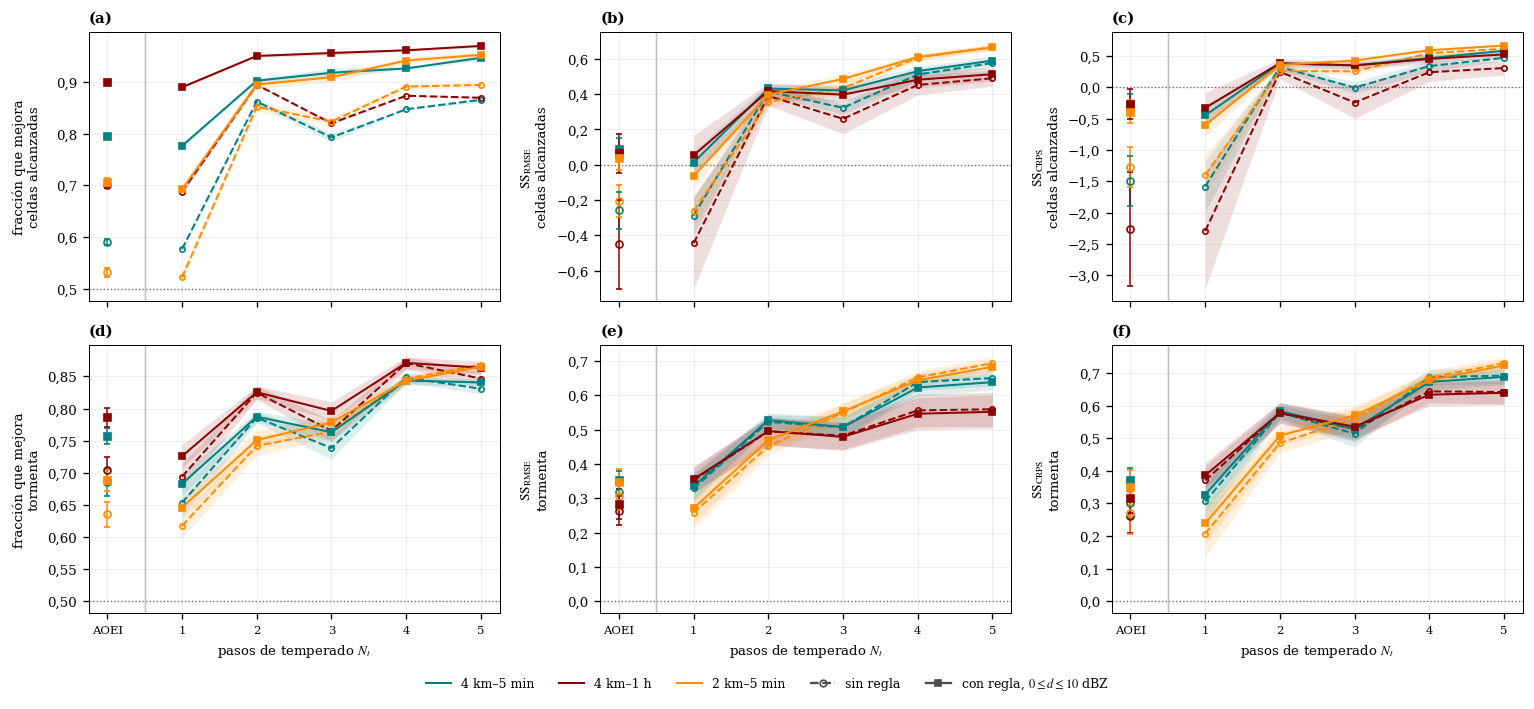

In [16]:
def draw_fig1(lang):
    V = nb.VOCAB[lang]
    rows = ("alcanzadas", "tormenta")
    fig, axes = plt.subplots(len(rows), 3, sharex=True, figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 0.8),
                             constrained_layout=True)
    for r, dn in enumerate(rows):
        for c, (col, vk, guide) in enumerate(METRIC_PANELS):
            ax = axes[r, c]
            ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
            for rg in REGLAS:
                ladder(ax, H2.xs((dn, rg), level=("domain", "regla")), col, label=None, style=REGLA_STYLE[rg])
            ax.set_ylabel(f"{V[vk]}\n{V[DOM_LABEL[dn]]}", fontsize=8)
            if r == len(rows) - 1:
                ax.set_xlabel(V["nt"], fontsize=8)
    fig.align_ylabels(axes)
    for a, l in zip(axes.ravel(), "abcdef"):
        a.set_title(f"({l})", loc="left", fontsize=9, fontweight="bold")
    regla_legend(fig, lang)
    return fig


nb.save(draw_fig1, "N6_fig1_resultado", show=SHOW); plt.show()

## 3 · Retenidas y rechazadas

$Z$ en las particiones de los dominios de N4. Las celdas observadas se parten según su propia observación: retenida o rechazada. En las rechazadas, la corrida con regla todavía puede cambiar la celda a través de las retenidas vecinas. Las alcanzadas se parten según quién las alcanza: alguna retenida, o solo rechazadas. Estas últimas quedan en el prior con la regla, por construcción (lo verifica la sección 0).

La descomposición: la reducción relativa del error cuadrático en las alcanzadas, $(\sum e_f^2 - \sum e_a^2)/\sum e_f^2 = 1 - (1 - \mathrm{SS}_\mathrm{RMSE})^2$, es la suma de las de sus dos partes, cada una con el mismo denominador.

In [17]:
for dn in PARTS:
    print(f"\n{dn}: Z, agrupado ± desviación entre los 12 miembros verdad")
    print(compare(H2.xs(dn, level="domain"), ("F", "SS_RMSE", "SS_CRPS")).to_string())

g = ZS.groupby(["dataset", "regla", "method", "ntemp", "domain"])[["se2_f", "se2_a"]].sum()
dq = (g.se2_f - g.se2_a).unstack("domain")
f0 = g.se2_f.unstack("domain")["alcanzadas"]
DEC = pd.DataFrame({dn: dq[dn] / f0 for dn in ("alcance retenidas", "solo rechazadas", "alcanzadas")})
assert np.allclose(DEC["alcance retenidas"] + DEC["solo rechazadas"], DEC["alcanzadas"], rtol=1e-9, atol=1e-12)
assert (DEC.xs(RULE, level="regla")["solo rechazadas"] == 0).all()
t = DEC.unstack("regla")
t = t[[(dn, rg) for dn in DEC.columns for rg in REGLAS]].reindex(pd.MultiIndex.from_tuples(ROWS))
t.index = [f"{DSL[d]} {lab(m, n)}" for d, m, n in t.index]
print("\nreducción relativa de Σe² en las alcanzadas, por partición (positivo = mejora):")
print(t.to_string(float_format=lambda v: f"{v:+.3f}"))


retenidas: Z, agrupado ± desviación entre los 12 miembros verdad
                             F sin          F con     Δ F     SS_RMSE sin     SS_RMSE con Δ SS_RMSE     SS_CRPS sin     SS_CRPS con Δ SS_CRPS
4 km–5 min TEnKF-T1  0.585 ± 0.007  0.751 ± 0.005  +0.166  -0.153 ± 0.102   0.076 ± 0.070    +0.230  -1.202 ± 0.376  -0.369 ± 0.193    +0.833
4 km–5 min TEnKF-T2  0.891 ± 0.003  0.905 ± 0.002  +0.014   0.463 ± 0.024   0.482 ± 0.024    +0.019   0.427 ± 0.048   0.454 ± 0.047    +0.028
4 km–5 min TEnKF-T3  0.842 ± 0.008  0.926 ± 0.007  +0.084   0.420 ± 0.032   0.503 ± 0.025    +0.084   0.224 ± 0.071   0.465 ± 0.040    +0.241
4 km–5 min TEnKF-T4  0.897 ± 0.002  0.934 ± 0.002  +0.038   0.578 ± 0.031   0.602 ± 0.027    +0.024   0.481 ± 0.074   0.556 ± 0.056    +0.075
4 km–5 min TEnKF-T5  0.923 ± 0.004  0.960 ± 0.003  +0.037   0.648 ± 0.016   0.676 ± 0.015    +0.028   0.614 ± 0.031   0.685 ± 0.023    +0.072
4 km–5 min AOEI      0.595 ± 0.008  0.770 ± 0.006  +0.175  -0.141 ± 0.099   0.110 

figures/es/N6_fig2_particiones.png  figures/en/N6_fig2_partitions.png


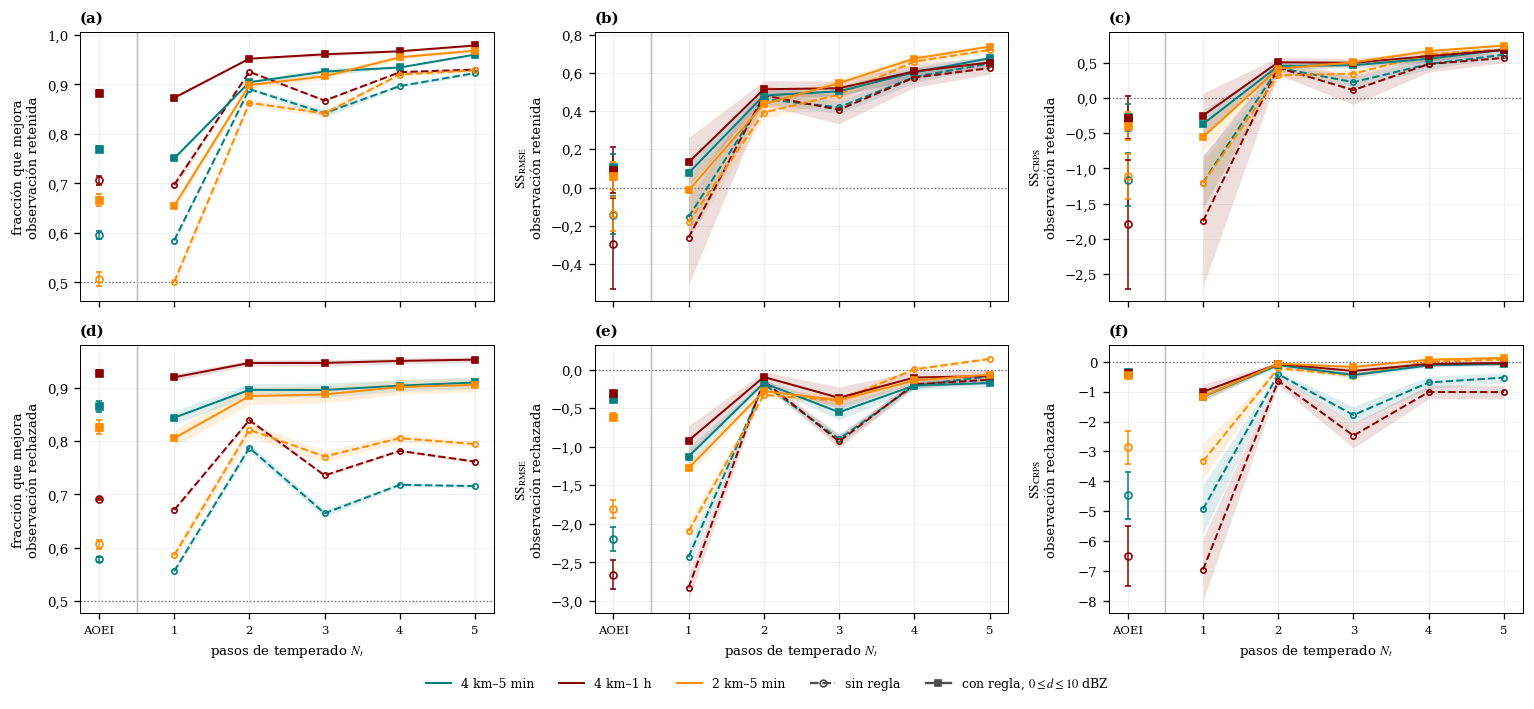

In [18]:
def draw_fig2(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    rows = ("retenidas", "rechazadas")
    fig, axes = plt.subplots(len(rows), 3, sharex=True, figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 0.8),
                             constrained_layout=True)
    for r, dn in enumerate(rows):
        for c, (col, vk, guide) in enumerate(METRIC_PANELS):
            ax = axes[r, c]
            ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
            for rg in REGLAS:
                ladder(ax, H2.xs((dn, rg), level=("domain", "regla")), col, label=None, style=REGLA_STYLE[rg])
            ax.set_ylabel(f"{V[vk]}\n{L[dn]}", fontsize=8)
            if r == len(rows) - 1:
                ax.set_xlabel(V["nt"], fontsize=8)
    fig.align_ylabels(axes)
    for a, l in zip(axes.ravel(), "abcdef"):
        a.set_title(f"({l})", loc="left", fontsize=9, fontweight="bold")
    regla_legend(fig, lang)
    return fig


nb.save(draw_fig2, "N6_fig2_particiones", show=SHOW); plt.show()

## 4 · Observación única y observaciones múltiples, con la regla

La comparación de N4 §3 con la regla, con los mismos 12 miembros verdad. Observación única: los experimentos de N3 (`N3_sums_rule.csv`), todos sin regla y solo los retenidos con ella, que es como N3 cuenta la regla. Observaciones múltiples: las celdas observadas sin regla y las retenidas con ella, que son las mismas observaciones que la observación única retiene. Siguen difiriendo dos factores a la vez: la interacción entre observaciones y la localización (0,1 km contra 2 km).

In [19]:
S3 = N3R[N3R.tm.isin(TMS) & N3R.rule.isin(REGLAS)].rename(columns={"rule": "regla"})
H4s = central_band(S3, ["dataset", "regla", "method", "ntemp"])[0]
assert (H4s.n_truths == len(TMS)).all()
H4m = {NONE: H2.xs(("observadas", NONE), level=("domain", "regla")),
       RULE: H2.xs(("retenidas", RULE), level=("domain", "regla"))}
idx = pd.MultiIndex.from_tuples(ROWS)
for c in ("F", "SS_RMSE", "SS_CRPS"):
    t = pd.DataFrame({f"única {k}": [pm(r_[c], r_[f"{c}_sd"]) for _, r_ in H4s.xs(rg, level="regla").reindex(idx).iterrows()]
                      for k, rg in (("sin", NONE), ("con", RULE))}, index=idx)
    for k, rg in (("sin", NONE), ("con", RULE)):
        t[f"múltiples {k}"] = [pm(r_[c], r_[f"{c}_sd"]) for _, r_ in H4m[rg].reindex(idx).iterrows()]
    t.index = [f"{DSL[d]} {lab(m, n)}" for d, m, n in idx]
    print(f"\n{c}: agrupado ± desviación entre los 12 miembros verdad")
    print(t.to_string())


F: agrupado ± desviación entre los 12 miembros verdad
                         única sin      única con  múltiples sin  múltiples con
4 km–5 min TEnKF-T1  0.744 ± 0.004  0.869 ± 0.003  0.577 ± 0.004  0.751 ± 0.005
4 km–5 min TEnKF-T2  0.845 ± 0.004  0.920 ± 0.002  0.862 ± 0.005  0.905 ± 0.002
4 km–5 min TEnKF-T3  0.818 ± 0.003  0.924 ± 0.002  0.793 ± 0.008  0.926 ± 0.007
4 km–5 min TEnKF-T4  0.797 ± 0.003  0.906 ± 0.002  0.847 ± 0.001  0.934 ± 0.002
4 km–5 min TEnKF-T5  0.845 ± 0.003  0.937 ± 0.002  0.865 ± 0.005  0.960 ± 0.003
4 km–5 min AOEI      0.751 ± 0.003  0.872 ± 0.003  0.591 ± 0.005  0.770 ± 0.006
4 km–1 h TEnKF-T1    0.784 ± 0.005  0.927 ± 0.004  0.687 ± 0.005  0.873 ± 0.003
4 km–1 h TEnKF-T2    0.857 ± 0.003  0.956 ± 0.003  0.895 ± 0.002  0.952 ± 0.002
4 km–1 h TEnKF-T3    0.832 ± 0.004  0.957 ± 0.003  0.820 ± 0.002  0.961 ± 0.004
4 km–1 h TEnKF-T4    0.816 ± 0.005  0.947 ± 0.003  0.873 ± 0.001  0.967 ± 0.001
4 km–1 h TEnKF-T5    0.848 ± 0.004  0.965 ± 0.003  0.869 ± 0.002 

## 5 · Variables de estado

Las tablas de N4 §6 con y sin regla: $\mathrm{SS}_\mathrm{RMSE}$ y $\mathrm{SS}_\mathrm{CRPS}$ de las ocho variables en tormenta alcanzada, aire claro alcanzado y las dos juntas. El MSE, el CRPS y la varianza del prior en las celdas alcanzadas son los de N4 (`N4_state_prior`, `N4_state_crps`, `N4_state_spread`), los mismos para las dos versiones. Los del posterior salen por cancelación con los escalares de cada corrida: $\sum_\mathrm{alc} e_a^2 = \sum_\mathrm{alc} e_f^2 - (\sum_\mathrm{dom} e_f^2 - \sum_\mathrm{dom} e_a^2)$, y lo mismo con el CRPS y la varianza. Con la regla vale igual, porque la corrida solo cambia celdas dentro del alcance de la línea base. La sección 0 verifica el método en $Z$ para las dos versiones. Como en N4, no se quitan las celdas del vecindario de las NaN.

In [20]:
SCAL4 = read4("N4_scalars.csv")
ST_VARS = tuple(nb.VARS)
NE = int(SCAL4.Ne.iloc[0])
assert SCAL4.Ne.nunique() == 1 and (SCAL6.Ne == NE).all()
F7 = (NE + 1) / NE
KEY = ["dataset", "hour", "tm", "method", "ntemp"]


def state_q(SC):
    """Por variable y dominio, la reducción de Σe², ΣCRPS y Σvar (ddof = 1) desde los escalares."""
    parts = []
    for v in ST_VARS:
        for dom in ("global", "storm"):
            sse = lambda s: SC[f"n_rmse_{s}_{dom}_{v}"] * SC[f"rmse_{s}_{dom}_{v}"] ** 2
            scr = lambda s: SC[f"n_crps_{s}_{dom}_{v}"] * SC[f"crps_{s}_{dom}_{v}"]
            svr = lambda s: SC[f"n_spread_{s}_{dom}_{v}"] * SC[f"spread_{s}_{dom}_{v}"] ** 2 / F7
            parts.append(SC[KEY].assign(var=v, dom=dom, Q=sse("f") - sse("a"), Qc=scr("f") - scr("a"),
                                        dvar=svr("f") - svr("a")))
    P = pd.concat(parts).set_index(KEY + ["var", "dom"])[["Q", "Qc", "dvar"]]
    return {"tormenta": P.xs("storm", level="dom"),
            "aire claro": P.xs("global", level="dom") - P.xs("storm", level="dom")}


EK = ["dataset", "hour", "tm", "var", "dominio"]
# las ocho variables (N4_state_crps trae además Z, el control del método) en tormenta y aire claro
_e = [read4(f).pipe(lambda d: d[d["var"].isin(ST_VARS) & (d.dominio != "completo")]).set_index(EK)
      for f in ("N4_state_prior.csv", "N4_state_crps.csv", "N4_state_spread.csv")]
E6 = _e[0].join(_e[1], rsuffix="_crps", how="inner").join(_e[2], rsuffix="_sp", how="inner")
assert len(E6) == len(_e[0]) == len(_e[1]) == len(_e[2])
assert (E6.n == E6.n_crps).all() and (E6.n == E6.n_sp).all(), "el error, el CRPS y la varianza del prior no tienen las mismas celdas"
E6 = E6[["n", "sum_err2", "sum_crps_f", "sum_var_f"]]

rows = []
for rg, SC in ((NONE, SCAL4), (RULE, SCAL6)):
    Q = state_q(SC)
    for dn in ("tormenta", "aire claro"):
        e = E6.xs(dn, level="dominio").reset_index()
        rows.append(Q[dn].reset_index().merge(e, on=["dataset", "hour", "tm", "var"], validate="many_to_one")
                    .assign(domain=dn, regla=rg))
ST = pd.concat(rows, ignore_index=True)
_c = ["Q", "Qc", "dvar", "n", "sum_err2", "sum_crps_f", "sum_var_f"]
ST = pd.concat([ST, ST.groupby(["regla"] + KEY + ["var"], as_index=False)[_c].sum().assign(domain="alcanzadas")],
               ignore_index=True)
ST = ST.assign(se2_f=ST.sum_err2, se2_a=ST.sum_err2 - ST.Q, scrps_f=ST.sum_crps_f, scrps_a=ST.sum_crps_f - ST.Qc,
               ssp2_f=ST.sum_var_f, ssp2_a=ST.sum_var_f - ST.dvar)
assert len(ST) == 3 * len(REGLAS) * len(SCAL4) * len(ST_VARS)
for c in ("se2_a", "scrps_a", "ssp2_a"):
    assert (ST[c] > 0).all(), f"{c} del posterior no positivo"
H6, PT6 = central_band(ST, ["var", "domain", "dataset", "regla", "method", "ntemp"])
assert (H6.n_truths == len(TMS)).all()

idx = pd.MultiIndex.from_tuples(ROWS)
for dn in ("tormenta", "aire claro", "alcanzadas"):
    t = H6.xs(dn, level="domain")
    a, b = t.xs(NONE, level="regla"), t.xs(RULE, level="regla")
    for st in ("SS_RMSE", "SS_CRPS"):
        con = pd.Series([pm(r_[st], r_[f"{st}_sd"]) for _, r_ in b.iterrows()], index=b.index)
        con = con.unstack("var").reindex(idx)[list(ST_VARS)]
        dif = (b[st] - a[st]).unstack("var").reindex(idx)[list(ST_VARS)]
        con.index = dif.index = [f"{DSL[d]} {lab(m, n)}" for d, m, n in idx]
        print(f"\n{st} de las variables de estado, {dn}, con regla: agrupado ± desviación entre los 12 miembros verdad")
        print(con.to_string())
        print(f"\n{st}, {dn}: con regla − sin regla")
        print(dif.to_string(float_format=lambda v: f"{v:+.3f}"))


SS_RMSE de las variables de estado, tormenta, con regla: agrupado ± desviación entre los 12 miembros verdad
var                             qg             qr             qs               T               P               u               v               w
4 km–5 min TEnKF-T1  0.134 ± 0.041  0.131 ± 0.037  0.124 ± 0.918   0.110 ± 0.098  -0.016 ± 0.050  -0.005 ± 0.040  -0.064 ± 0.044  -0.059 ± 0.037
4 km–5 min TEnKF-T2  0.293 ± 0.051  0.307 ± 0.038  0.224 ± 0.696   0.094 ± 0.109  -0.022 ± 0.054  -0.017 ± 0.039  -0.077 ± 0.046  -0.038 ± 0.033
4 km–5 min TEnKF-T3  0.285 ± 0.050  0.297 ± 0.039  0.203 ± 0.815   0.096 ± 0.099  -0.011 ± 0.053  -0.000 ± 0.032  -0.058 ± 0.039  -0.020 ± 0.028
4 km–5 min TEnKF-T4  0.306 ± 0.052  0.328 ± 0.040  0.219 ± 0.755   0.073 ± 0.077  -0.018 ± 0.047  -0.005 ± 0.029  -0.062 ± 0.036  -0.055 ± 0.036
4 km–5 min TEnKF-T5  0.310 ± 0.051  0.343 ± 0.040  0.224 ± 0.731   0.076 ± 0.065  -0.009 ± 0.040   0.005 ± 0.026  -0.048 ± 0.032  -0.037 ± 0.033
4 km–5 min AOEI      

In [21]:
# Hidrometeoros en aire claro alcanzado: el CRPS medio por celda del prior y del posterior,
# agrupado (ΣCRPS / ΣN sobre los 12 miembros verdad y sus cuatro horas), junto a SS_CRPS y
# SS_RMSE, con y sin regla. Como escala, el CRPS medio del prior en tormenta alcanzada. En g/kg.
CRPS_FMT = {c: "{:.2e}".format for c in ("CRPS_f [g/kg]", "CRPS_a sin [g/kg]", "CRPS_a con [g/kg]",
                                          "CRPS_f tormenta [g/kg]")}
CRPS_FMT.update({c: "{:+.3f}".format for c in ("SS_CRPS sin", "SS_CRPS con", "SS_RMSE sin", "SS_RMSE con")})
for v in HYDRO:
    t = H6.xs((v, "aire claro"), level=("var", "domain"))
    s = H6.xs((v, "tormenta", NONE), level=("var", "domain", "regla")).reindex(idx)
    a, b = t.xs(NONE, level="regla").reindex(idx), t.xs(RULE, level="regla").reindex(idx)
    assert np.array_equal(a.CRPS_f, b.CRPS_f), "el prior difiere entre las dos versiones"
    tab = pd.DataFrame({"CRPS_f [g/kg]": 1e3 * a.CRPS_f, "CRPS_a sin [g/kg]": 1e3 * a.CRPS_a,
                        "CRPS_a con [g/kg]": 1e3 * b.CRPS_a, "SS_CRPS sin": a.SS_CRPS, "SS_CRPS con": b.SS_CRPS,
                        "SS_RMSE sin": a.SS_RMSE, "SS_RMSE con": b.SS_RMSE, "CRPS_f tormenta [g/kg]": 1e3 * s.CRPS_f})
    tab.index = [f"{DSL[d]} {lab(m, n)}" for d, m, n in idx]
    print(f"\n{v}, aire claro alcanzado (agrupado)")
    print(tab.to_string(formatters=CRPS_FMT))


qg, aire claro alcanzado (agrupado)
                    CRPS_f [g/kg] CRPS_a sin [g/kg] CRPS_a con [g/kg] SS_CRPS sin SS_CRPS con SS_RMSE sin SS_RMSE con CRPS_f tormenta [g/kg]
4 km–5 min TEnKF-T1      4.55e-04          2.90e-03          1.34e-03      -5.370      -1.939      +0.145      +0.284               8.24e-02
4 km–5 min TEnKF-T2      4.55e-04          3.45e-04          2.88e-04      +0.243      +0.367      +0.839      +0.835               8.24e-02
4 km–5 min TEnKF-T3      4.55e-04          8.57e-04          3.90e-04      -0.884      +0.142      +0.722      +0.737               8.24e-02
4 km–5 min TEnKF-T4      4.55e-04          5.19e-04          3.30e-04      -0.142      +0.274      +0.881      +0.867               8.24e-02
4 km–5 min TEnKF-T5      4.55e-04          4.34e-04          2.47e-04      +0.046      +0.456      +0.881      +0.869               8.24e-02
4 km–5 min AOEI          4.55e-04          2.57e-03          8.88e-04      -4.643      -0.952      +0.265      +0.489

figures/es/N6_fig3_w.png  figures/en/N6_fig3_w.png


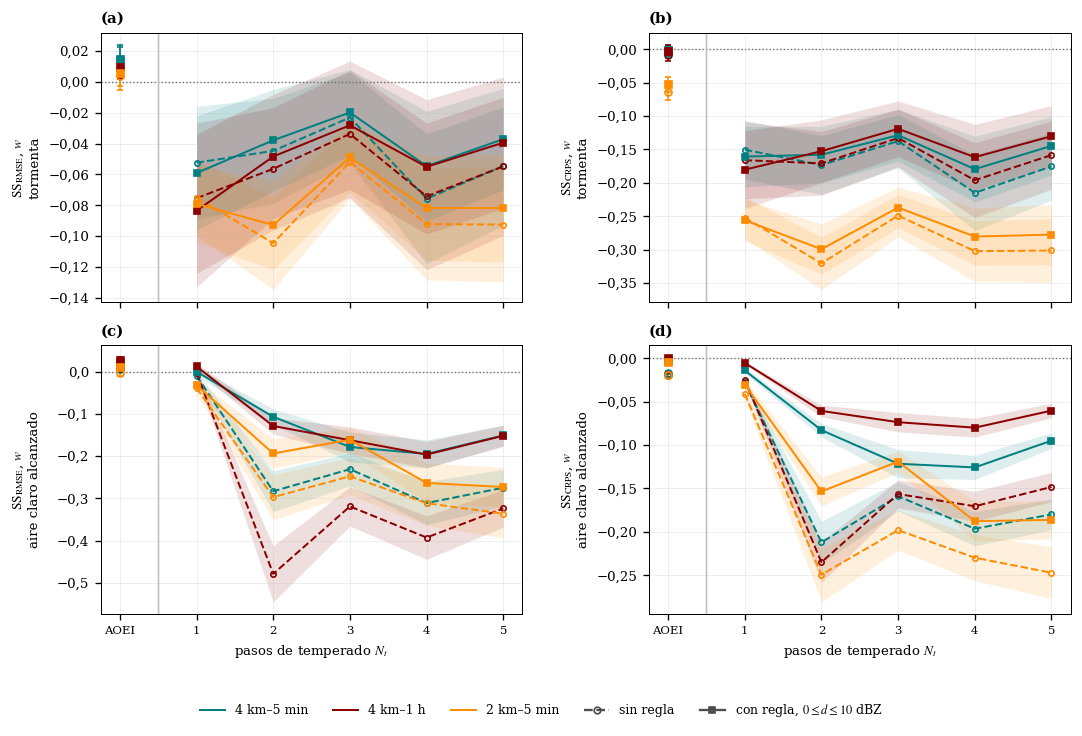

In [22]:
def draw_fig3(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    doms = (("tormenta", V["dom_storm"]), ("aire claro", L["clear_reached"]))
    fig, axes = plt.subplots(2, 2, sharex=True, figsize=(nb.PAGE_W * 1.3, nb.PAGE_W * 0.8),
                             constrained_layout=True)
    for r, (dn, dlab) in enumerate(doms):
        for c, st in enumerate(("SS_RMSE", "SS_CRPS")):
            ax = axes[r, c]
            ax.axhline(0.0, color="0.35", lw=0.8, ls=":", zorder=1)
            for rg in REGLAS:
                ladder(ax, H6.xs(("w", dn, rg), level=("var", "domain", "regla")), st, label=None,
                       style=REGLA_STYLE[rg])
            ax.set_ylabel(f"{V[st.lower()]}, $w$\n{dlab}", fontsize=8)
            if r == len(doms) - 1:
                ax.set_xlabel(V["nt"], fontsize=8)
    fig.align_ylabels(axes)
    for a, l in zip(axes.ravel(), "abcd"):
        a.set_title(f"({l})", loc="left", fontsize=9, fontweight="bold")
    regla_legend(fig, lang, y=-0.1)
    return fig


nb.save(draw_fig3, "N6_fig3_w", show=SHOW); plt.show()

## 6 · Dispersión frente a error

Las tablas de N4 §7 con y sin regla. Dispersión total $= \sqrt{(N_e+1)/N_e \cdot}$ media de la varianza de los miembros (ddof = 1), contra el RMSE de la media. Cada cociente se calcula sobre las sumas de los 12 miembros y las cuatro horas; la banda, entre los 12. $Z$, exacto en las celdas de cada dominio desde las sumas de los campos; el estado, en tormenta y aire claro alcanzados, con el prior de N4 y el posterior por cancelación. El cociente de RMSE posterior / prior es $1 - \mathrm{SS}_\mathrm{RMSE}$.

In [23]:
def ratios(s):
    return pd.DataFrame({"ratio_f": np.sqrt(F7 * s.ssp2_f / s.se2_f), "ratio_a": np.sqrt(F7 * s.ssp2_a / s.se2_a),
                         "contr_spread": np.sqrt(s.ssp2_a / s.ssp2_f), "contr_rmse": np.sqrt(s.se2_a / s.se2_f)},
                        index=s.index)


K7 = ["domain", "dataset", "regla", "method", "ntemp"]
C7 = ratios(ZS.groupby(K7)[["se2_f", "se2_a", "ssp2_f", "ssp2_a"]].sum())
P7 = ratios(ZS.set_index(K7 + ["tm"])[["se2_f", "se2_a", "ssp2_f", "ssp2_a"]])
H7 = C7.join(P7.groupby(level=K7).std(ddof=1).add_suffix("_sd"))
for dn in ("alcanzadas", "tormenta", "retenidas", "rechazadas"):
    t = H7.xs(dn, level="domain")
    a = t.xs(NONE, level="regla").reindex(idx)
    tab = compare(t, ("ratio_a", "contr_spread", "contr_rmse"))
    tab.insert(0, "ratio_f", [pm(r_.ratio_f, r_.ratio_f_sd) for _, r_ in a.iterrows()])
    print(f"\nZ, {dn}: agrupado ± desviación entre los 12 miembros verdad")
    print(tab.to_string())


Z, alcanzadas: agrupado ± desviación entre los 12 miembros verdad
                           ratio_f    ratio_a sin    ratio_a con Δ ratio_a contr_spread sin contr_spread con Δ contr_spread contr_rmse sin contr_rmse con Δ contr_rmse
4 km–5 min TEnKF-T1  1.066 ± 0.108  0.520 ± 0.016  0.684 ± 0.036    +0.164    0.628 ± 0.008    0.634 ± 0.008         +0.005  1.288 ± 0.106  0.988 ± 0.064       -0.301
4 km–5 min TEnKF-T2  1.066 ± 0.108  0.921 ± 0.065  0.968 ± 0.070    +0.047    0.505 ± 0.003    0.515 ± 0.003         +0.010  0.585 ± 0.026  0.568 ± 0.025       -0.017
4 km–5 min TEnKF-T3  1.066 ± 0.108  0.618 ± 0.053  0.773 ± 0.079    +0.155    0.393 ± 0.005    0.420 ± 0.003         +0.027  0.678 ± 0.036  0.579 ± 0.030       -0.099
4 km–5 min TEnKF-T4  1.066 ± 0.108  0.784 ± 0.043  0.890 ± 0.060    +0.106    0.360 ± 0.003    0.392 ± 0.002         +0.032  0.489 ± 0.033  0.470 ± 0.027       -0.019
4 km–5 min TEnKF-T5  1.066 ± 0.108  0.853 ± 0.078  0.975 ± 0.093    +0.122    0.339 ± 0.004    0.3

In [24]:
# El estado: las ocho variables, tormenta y aire claro alcanzado, T1, T2, T5 y AOEI, con y sin regla.
T7 = ratios(ST[ST.domain != "alcanzadas"].groupby(["var", "domain", "dataset", "regla", "method", "ntemp"])
            [["ssp2_f", "ssp2_a", "se2_f", "se2_a"]].sum())
S7_SCH = [("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5), ("AOEI", 1)]
i7 = pd.MultiIndex.from_tuples([(d, m, n) for d in DATASETS for m, n in S7_SCH])
for v in ST_VARS:
    for dn in ("tormenta", "aire claro"):
        t = T7.loc[(v, dn)]
        a, b = t.xs(NONE, level="regla").reindex(i7), t.xs(RULE, level="regla").reindex(i7)
        tab = pd.DataFrame({"ratio_f": a.ratio_f, "ratio_a sin": a.ratio_a, "ratio_a con": b.ratio_a,
                            "contr_spread sin": a.contr_spread, "contr_spread con": b.contr_spread,
                            "contr_rmse sin": a.contr_rmse, "contr_rmse con": b.contr_rmse})
        tab.index = [f"{DSL[d]} {lab(m, n)}" for d, m, n in i7]
        print(f"\n{v}, {dn} alcanzado (agrupado):")
        print(tab.to_string(float_format=lambda x: f"{x:.3f}"))


qg, tormenta alcanzado (agrupado):
                     ratio_f  ratio_a sin  ratio_a con  contr_spread sin  contr_spread con  contr_rmse sin  contr_rmse con
4 km–5 min TEnKF-T1    0.499        0.277        0.285             0.475             0.494           0.856           0.866
4 km–5 min TEnKF-T2    0.499        0.211        0.227             0.298             0.321           0.706           0.707
4 km–5 min TEnKF-T5    0.499        0.156        0.181             0.215             0.251           0.687           0.690
4 km–5 min AOEI        0.499        0.292        0.307             0.548             0.575           0.936           0.936
4 km–1 h TEnKF-T1      0.399        0.196        0.201             0.419             0.435           0.855           0.866
4 km–1 h TEnKF-T2      0.399        0.156        0.162             0.279             0.291           0.716           0.716
4 km–1 h TEnKF-T5      0.399        0.124        0.133             0.219             0.233           0.

## 7 · Tablas y números para el texto

Las tablas completas, con y sin regla, en `data/derived/N6/tablas/`, para armar las del anexo: $Z$ por dominio (`N6_tab_Z.csv`), el estado (`N6_tab_estado.csv`), y la dispersión de $Z$ y del estado (`N6_tab_dispersion_Z.csv`, `N6_tab_dispersion_estado.csv`). Cada fila trae el valor agrupado, la desviación entre verdades y el número de verdades. Debajo, los números del texto.

In [25]:
TAB = OUT / "tablas"
TAB.mkdir(parents=True, exist_ok=True)
for name, df in (("N6_tab_Z", H2), ("N6_tab_estado", H6), ("N6_tab_dispersion_Z", H7),
                 ("N6_tab_dispersion_estado", T7)):
    df.reset_index().to_csv(TAB / f"{name}.csv", index=False)
    print(f"{rel(TAB / name)}.csv: {len(df)} filas")

TXT_SCH = [("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5), ("AOEI", 1)]


def arrow(H, col, nd=2):
    a, b = H.xs(NONE, level="regla"), H.xs(RULE, level="regla")
    return {lab(m, n): f"{a.loc[(m, n), col]:+.{nd}f} → {b.loc[(m, n), col]:+.{nd}f}" for m, n in TXT_SCH}


print("\nretenidas: " + ", ".join(f"{DSL[ds]} {T1.loc[ds, 'retenidas [%]']:.1f} %" for ds in DATASETS))
rows = []
for dn in ("alcanzadas", "tormenta", "observadas", "retenidas", "rechazadas"):
    for ds in DATASETS:
        rows.append({"dominio": dn, "dataset": DSL[ds],
                     **arrow(H2.xs((dn, ds), level=("domain", "dataset")), "SS_RMSE")})
print("\nSS_RMSE de Z, sin regla → con regla:")
print(pd.DataFrame(rows).set_index(["dominio", "dataset"]).to_string())
rows = []
for v in ("w", "qg", "qr", "qs"):
    for dn in ("tormenta", "aire claro"):
        for ds in DATASETS:
            rows.append({"variable": v, "dominio": dn, "dataset": DSL[ds],
                         **arrow(H6.xs((v, dn, ds), level=("var", "domain", "dataset")), "SS_RMSE")})
print("\nSS_RMSE del estado, sin regla → con regla:")
print(pd.DataFrame(rows).set_index(["variable", "dominio", "dataset"]).to_string())

WRF_Single_Cycle_Assimilation/data/derived/N6/tablas/N6_tab_Z.csv: 252 filas
WRF_Single_Cycle_Assimilation/data/derived/N6/tablas/N6_tab_estado.csv: 864 filas
WRF_Single_Cycle_Assimilation/data/derived/N6/tablas/N6_tab_dispersion_Z.csv: 252 filas
WRF_Single_Cycle_Assimilation/data/derived/N6/tablas/N6_tab_dispersion_estado.csv: 576 filas

retenidas: 4 km–5 min 72.0 %, 4 km–1 h 63.8 %, 2 km–5 min 74.7 %

SS_RMSE de Z, sin regla → con regla:
                            TEnKF-T1       TEnKF-T2       TEnKF-T5           AOEI
dominio    dataset                                                               
alcanzadas 4 km–5 min  -0.29 → +0.01  +0.41 → +0.43  +0.58 → +0.59  -0.26 → +0.09
           4 km–1 h    -0.45 → +0.05  +0.39 → +0.42  +0.49 → +0.51  -0.45 → +0.06
           2 km–5 min  -0.26 → -0.06  +0.36 → +0.40  +0.67 → +0.66  -0.21 → +0.04
tormenta   4 km–5 min  +0.33 → +0.34  +0.52 → +0.53  +0.65 → +0.64  +0.32 → +0.35
           4 km–1 h    +0.35 → +0.36  +0.49 → +0.50  +0.56 → +0.

## 8 · La ventaja del temperado sobre la LETKF

TEnKF-T1 es la LETKF sin temperado. La **ventaja** de un esquema es su $\mathrm{SS}$ menos el de TEnKF-T1, con la misma regla y sobre las mismas celdas. El valor central sale de las sumas agrupadas; la banda es la desviación entre los 12 miembros verdad de la misma diferencia calculada por miembro.

Si la ventaja baja con la regla, esa parte de lo que el temperado le gana a la LETKF consiste en no romperse con las observaciones de la banda; lo que queda viene de las demás. La columna «parte de la banda» es $1 -$ ventaja con regla / ventaja sin regla, solo donde la ventaja sin regla pasa de 0,05.

$Z$ en las celdas alcanzadas, en la tormenta y en el aire claro alcanzado. El aire claro alcanzado es alcanzadas − tormenta, por sumas: las columnas sin máximo de la verdad ≥ 20 dBZ, que incluyen los ecos débiles y los bordes. El estado, en tormenta y en aire claro alcanzado (sección 5).

In [26]:
_k = ["dataset", "regla", "method", "ntemp", "tm"]
_a = ZS[ZS.domain == "alcanzadas"].set_index(_k)[SUMS]
_t = ZS[ZS.domain == "tormenta"].set_index(_k)[SUMS]
Z8 = pd.concat([ZS.loc[ZS.domain.isin(["alcanzadas", "tormenta"]), _k + ["domain"] + SUMS],
                (_a - _t).reset_index().assign(domain="aire claro")], ignore_index=True)
assert (Z8[Z8.domain == "aire claro"].n > 0).all()


def advantage(df, keys, col="SS_RMSE"):
    """SS(esquema) − SS(TEnKF-T1), misma regla y mismas celdas: agrupado y desviación entre verdades."""
    lv = keys + ["regla"]
    H, PT = central_band(df, lv + ["method", "ntemp"])
    t1 = H.xs(("TEnKF", 1), level=("method", "ntemp"))[col].rename("t1")
    p1 = PT.xs(("TEnKF", 1), level=("method", "ntemp"))[col].rename("t1")
    h = H[[col]].reset_index().merge(t1.reset_index(), on=lv)
    p = PT[[col]].reset_index().merge(p1.reset_index(), on=lv + ["tm"])
    h["adv"], p["adv"] = h[col] - h.t1, p[col] - p.t1
    sd = p.groupby(lv + ["method", "ntemp"]).adv.std(ddof=1).rename("adv_sd")
    return h.set_index(lv + ["method", "ntemp"])[["adv"]].join(sd)


A8 = {st: advantage(Z8, ["domain", "dataset"], st) for st in ("SS_RMSE", "SS_CRPS")}
A8s = {st: advantage(ST, ["var", "domain", "dataset"], st) for st in ("SS_RMSE", "SS_CRPS")}
ADV_ROWS = [(d, m, n) for d in DATASETS for m, n in SCHEMES if (m, n) != ("TEnKF", 1)]
ADV_IDX = pd.MultiIndex.from_tuples(ADV_ROWS)


def adv_table(A, nd=3):
    a, b = A.xs(NONE, level="regla").reindex(ADV_IDX), A.xs(RULE, level="regla").reindex(ADV_IDX)
    with np.errstate(invalid="ignore", divide="ignore"):
        part = np.where(a.adv > 0.05, 1 - b.adv / a.adv, np.nan)
    return pd.DataFrame({"sin": [pm(x, s, nd) for x, s in zip(a.adv, a.adv_sd)],
                         "con": [pm(x, s, nd) for x, s in zip(b.adv, b.adv_sd)],
                         "parte de la banda": ["—" if not np.isfinite(v) else f"{100 * v:.0f} %" for v in part]},
                        index=[f"{DSL[d]} {lab(m, n)}" for d, m, n in ADV_IDX])


for st in ("SS_RMSE", "SS_CRPS"):
    for dn in ("alcanzadas", "aire claro", "tormenta"):
        print(f"\nZ, {dn}: ventaja de {st} sobre TEnKF-T1, agrupado ± desviación entre los 12 miembros verdad")
        print(adv_table(A8[st].xs(dn, level="domain")).to_string())
for dn in ("tormenta", "aire claro"):
    t = A8s["SS_RMSE"].xs(dn, level="domain")
    a = t.xs(NONE, level="regla").adv.unstack("var").reindex(ADV_IDX)
    b = t.xs(RULE, level="regla").adv.unstack("var").reindex(ADV_IDX)
    tab = pd.DataFrame({v: [f"{x:+.2f} → {y:+.2f}" for x, y in zip(a[v], b[v])] for v in ST_VARS},
                       index=[f"{DSL[d]} {lab(m, n)}" for d, m, n in ADV_IDX])
    print(f"\nestado, {dn} alcanzado: ventaja de SS_RMSE sobre TEnKF-T1, sin regla → con regla")
    print(tab.to_string())
for name, A in (("N6_tab_ventaja_Z", A8), ("N6_tab_ventaja_estado", A8s)):
    pd.concat(A, names=["metrica"]).reset_index().to_csv(TAB / f"{name}.csv", index=False)


Z, alcanzadas: ventaja de SS_RMSE sobre TEnKF-T1, agrupado ± desviación entre los 12 miembros verdad
                                sin            con parte de la banda
4 km–5 min TEnKF-T2   0.703 ± 0.084  0.420 ± 0.042              40 %
4 km–5 min TEnKF-T3   0.611 ± 0.083  0.409 ± 0.052              33 %
4 km–5 min TEnKF-T4   0.799 ± 0.076  0.518 ± 0.041              35 %
4 km–5 min TEnKF-T5   0.865 ± 0.093  0.578 ± 0.053              33 %
4 km–5 min AOEI       0.030 ± 0.010  0.075 ± 0.018                 —
4 km–1 h TEnKF-T2     0.835 ± 0.213  0.364 ± 0.074              56 %
4 km–1 h TEnKF-T3     0.705 ± 0.177  0.344 ± 0.080              51 %
4 km–1 h TEnKF-T4     0.897 ± 0.211  0.428 ± 0.080              52 %
4 km–1 h TEnKF-T5     0.935 ± 0.228  0.460 ± 0.094              51 %
4 km–1 h AOEI        -0.006 ± 0.009  0.011 ± 0.015                 —
2 km–5 min TEnKF-T2   0.619 ± 0.069  0.462 ± 0.050              25 %
2 km–5 min TEnKF-T3   0.698 ± 0.070  0.551 ± 0.054              21 %
2

figures/es/N6_fig4_ventaja.png  figures/en/N6_fig4_advantage.png


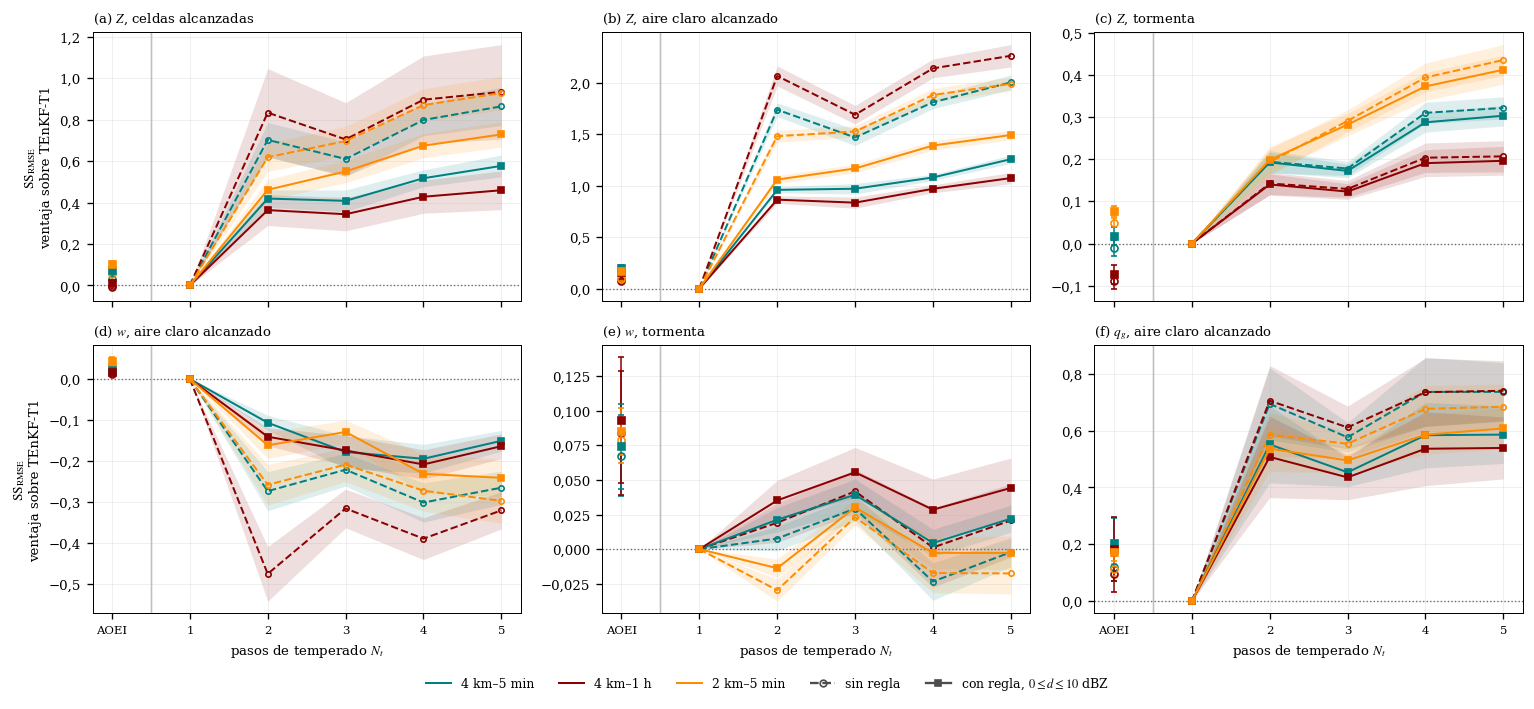

In [27]:
def draw_fig4(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    panels = [(A8["SS_RMSE"], ("alcanzadas",), f"$Z$, {V['dom_reached']}"),
              (A8["SS_RMSE"], ("aire claro",), f"$Z$, {L['clear_reached']}"),
              (A8["SS_RMSE"], ("tormenta",), f"$Z$, {L['storm']}"),
              (A8s["SS_RMSE"], ("w", "aire claro"), f"$w$, {L['clear_reached']}"),
              (A8s["SS_RMSE"], ("w", "tormenta"), f"$w$, {L['storm']}"),
              (A8s["SS_RMSE"], ("qg", "aire claro"), f"$q_g$, {L['clear_reached']}")]
    fig, axes = plt.subplots(2, 3, sharex=True, figsize=(nb.PAGE_W * 1.85, nb.PAGE_W * 0.8), constrained_layout=True)
    for ax, l, (A, key, title) in zip(axes.ravel(), "abcdef", panels):
        lv = ("domain",) if len(key) == 1 else ("var", "domain")
        ax.axhline(0.0, color="0.35", lw=0.8, ls=":", zorder=1)
        for rg in REGLAS:
            ladder(ax, A.xs(key + (rg,), level=lv + ("regla",)), "adv", label=None, style=REGLA_STYLE[rg])
        ax.set_title(f"({l}) {title}", loc="left", fontsize=8)
    for ax in axes[:, 0]:
        ax.set_ylabel(f"{V['ss_rmse']}\n{L['adv']}", fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel(V["nt"], fontsize=8)
    regla_legend(fig, lang)
    return fig


nb.save(draw_fig4, "N6_fig4_ventaja", show=SHOW); plt.show()

## 9 · Dónde gana o pierde el temperado

$Z$ por grupos de celdas (sección 0.2), con las definiciones de siempre dentro de cada grupo. Se agregan dos fracciones celda a celda, contadas entre las celdas donde los dos errores difieren en más que `TOL`:

- `P_T1`: la parte donde el esquema deja menos error que TEnKF-T1 con la misma regla;
- `P_regla`: con la regla, la parte donde la regla deja menos error que el mismo esquema sin regla.

Y de dónde sale la ventaja del temperado: el aporte de cada región, $(\sum e_a^2(\mathrm{T1}) - \sum e_a^2(\mathrm{T}k))/\sum e_f^2$ de todas las alcanzadas. Los aportes suman la reducción total del error cuadrático que el temperado consigue sobre la LETKF; lo mismo para la regla, sin regla menos con regla.

**Cómo leer los cruces de las celdas observadas.**

- **Tramo de la innovación propia × $N_{Z>0}$:** separa el valor de $d$ del soporte del ensamble. Si, con el mismo $N_{Z>0}$, la banda sigue degradando más que los otros tramos, pesa la innovación. Si la diferencia desaparece al fijar $N_{Z>0}$, pesa el soporte.
- **Tramo × parte rechazada del vecindario:** separa la observación propia de las vecinas. En las celdas con observación retenida ($d < 0$, $d > 10$), lo que la regla cambia llega solo a través de los vecinos rechazados.

En las figuras no entran los grupos con menos de `N_MIN_BIN` celdas, sumadas las 12 verdades y las 4 horas.

Las mismas tablas con el CRPS van después de las del RMSE, con sus dos figuras (`N6_fig5b`, `N6_fig6b`).

In [28]:
N_MIN_BIN = 200
KC = ["agrupacion", "clase", "dataset", "regla", "method", "ntemp"]
H9, PT9 = central_band(CL6, KC)
G9 = CL6.groupby(KC)[["n_mejor_T1", "n_peor_T1", "n_mejor_sin", "n_peor_sin"]].sum().astype(float)
with np.errstate(invalid="ignore", divide="ignore"):
    H9["P_T1"] = G9.n_mejor_T1 / (G9.n_mejor_T1 + G9.n_peor_T1)
    H9["P_regla"] = G9.n_mejor_sin / (G9.n_mejor_sin + G9.n_peor_sin)
S9 = CL6.groupby(KC)[["n", "se2_f", "se2_a", "scrps_f", "scrps_a"]].sum()
LV = ("regla", "method", "ntemp")
TAB9_SCH = (("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5), ("AOEI", 1))


def class_table(gname, ds, q="SS_RMSE"):
    t = H9.xs((gname, ds), level=("agrupacion", "dataset"))
    base = S9.xs((gname, ds), level=("agrupacion", "dataset")).xs((NONE, "TEnKF", 1), level=LV)
    prior = ("RMSE_f", np.sqrt(base.se2_f / base.n)) if q == "SS_RMSE" else ("CRPS_f", base.scrps_f / base.n)
    out = pd.DataFrame({"celdas [%]": 100 * base.n / base.n.sum(), prior[0]: prior[1]})
    for m, n in TAB9_SCH:
        for rg, k in ((NONE, "sin"), (RULE, "con")):
            out[f"{lab(m, n)} {k}"] = t.xs((rg, m, n), level=LV)[q]
    return out.reindex(GROUPINGS[gname])


def pair_table(gname, ds):
    t = H9.xs((gname, ds), level=("agrupacion", "dataset"))
    out = pd.DataFrame(index=GROUPINGS[gname])
    for m, n in (("TEnKF", 2), ("TEnKF", 5), ("AOEI", 1)):
        for rg, k in ((NONE, "sin"), (RULE, "con")):
            out[f"P_T1 {lab(m, n)} {k}"] = t.xs((rg, m, n), level=LV).P_T1
    for m, n in (("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5)):
        out[f"P_regla {lab(m, n)}"] = t.xs((RULE, m, n), level=LV).P_regla
    return out


def aporte(ds, s_="se2"):
    s = S9.xs(("región", ds), level=("agrupacion", "dataset"))
    tot = s.xs((NONE, "TEnKF", 1), level=LV)[f"{s_}_f"].sum()
    a = lambda rg, m, n: s.xs((rg, m, n), level=LV)[f"{s_}_a"]
    out = pd.DataFrame(index=GROUPINGS["región"])
    for m, n in (("TEnKF", 2), ("TEnKF", 5)):
        for rg, k in ((NONE, "sin"), (RULE, "con")):
            out[f"{lab(m, n)} − T1 {k}"] = (a(rg, "TEnKF", 1) - a(rg, m, n)) / tot
    for m, n in (("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5)):
        out[f"regla {lab(m, n)}"] = (a(NONE, m, n) - a(RULE, m, n)) / tot
    out.loc["total"] = out.sum()
    return out


f2 = lambda v: f"{v:+.2f}"
for ds in DATASETS:
    print(f"\n══════ {DSL[ds]} ══════")
    for gname in GROUPINGS:
        print(f"\n{gname}: SS_RMSE de Z por grupo")
        print(class_table(gname, ds).to_string(float_format=f2, formatters={"celdas [%]": "{:.2f}".format, "RMSE_f": "{:.2f}".format}))
        print(f"\n{gname}: P_T1 (el esquema mejora a TEnKF-T1) y P_regla (la regla mejora), entre las celdas que difieren")
        print(pair_table(gname, ds).to_string(float_format=lambda v: f"{v:.2f}"))
    print("\nregión: aporte a la reducción de Σe² de las alcanzadas (positivo: el primero tiene menos error)")
    print(aporte(ds).to_string(float_format=lambda v: f"{v:+.3f}"))
H9.reset_index().to_csv(TAB / "N6_tab_clases.csv", index=False)


══════ 4 km–5 min ══════

región: SS_RMSE de Z por grupo
                                  celdas [%] RMSE_f  TEnKF-T1 sin  TEnKF-T1 con  TEnKF-T2 sin  TEnKF-T2 con  TEnKF-T5 sin  TEnKF-T5 con  AOEI sin  AOEI con
clase                                                                                                                                                      
núcleo | prior con eco                  0.22  33.02         +0.83         +0.83         +0.84         +0.85         +0.90         +0.90     +0.67     +0.66
núcleo | prior sin eco                  0.32  43.26         +0.67         +0.68         +0.68         +0.68         +0.70         +0.70     +0.40     +0.39
eco | prior con eco                     1.87  12.83         +0.33         +0.32         +0.36         +0.37         +0.67         +0.60     +0.41     +0.43
eco | prior sin eco                     3.34  19.28         +0.45         +0.44         +0.47         +0.48         +0.64         +0.62     +0.35     +0.33
borde 

In [29]:
# Lo mismo con el CRPS. En el aire claro el CRPS del prior por celda es de centésimas de dBZ
# (casi todos los miembros y la verdad en 0), así que el SS_CRPS se dispara con cualquier dispersión
# que el análisis cree; el aporte a ΣCRPS de las alcanzadas da el peso de cada grupo.
for ds in DATASETS:
    print(f"\n══════ {DSL[ds]} · CRPS ══════")
    for gname in GROUPINGS:
        print(f"\n{gname}: SS_CRPS de Z por grupo (CRPS_f: CRPS medio del prior por celda, dBZ)")
        print(class_table(gname, ds, "SS_CRPS").to_string(
            float_format=f2, formatters={"celdas [%]": "{:.2f}".format, "CRPS_f": "{:.3f}".format}))
    print("\nregión: aporte a la reducción de ΣCRPS de las alcanzadas (positivo: el primero tiene menos CRPS)")
    print(aporte(ds, "scrps").to_string(float_format=lambda v: f"{v:+.3f}"))



══════ 4 km–5 min · CRPS ══════

región: SS_CRPS de Z por grupo (CRPS_f: CRPS medio del prior por celda, dBZ)
                                  celdas [%] CRPS_f  TEnKF-T1 sin  TEnKF-T1 con  TEnKF-T2 sin  TEnKF-T2 con  TEnKF-T5 sin  TEnKF-T5 con  AOEI sin  AOEI con
clase                                                                                                                                                      
núcleo | prior con eco                  0.22 24.779         +0.85         +0.85         +0.88         +0.88         +0.91         +0.91     +0.69     +0.68
núcleo | prior sin eco                  0.32 40.846         +0.75         +0.75         +0.76         +0.77         +0.78         +0.78     +0.45     +0.44
eco | prior con eco                     1.87  8.247         +0.36         +0.34         +0.44         +0.43         +0.70         +0.62     +0.45     +0.44
eco | prior sin eco                     3.34 16.199         +0.52         +0.51         +0.56         +0.56  

figures/es/N6_fig5_regiones.png  figures/en/N6_fig5_regions.png


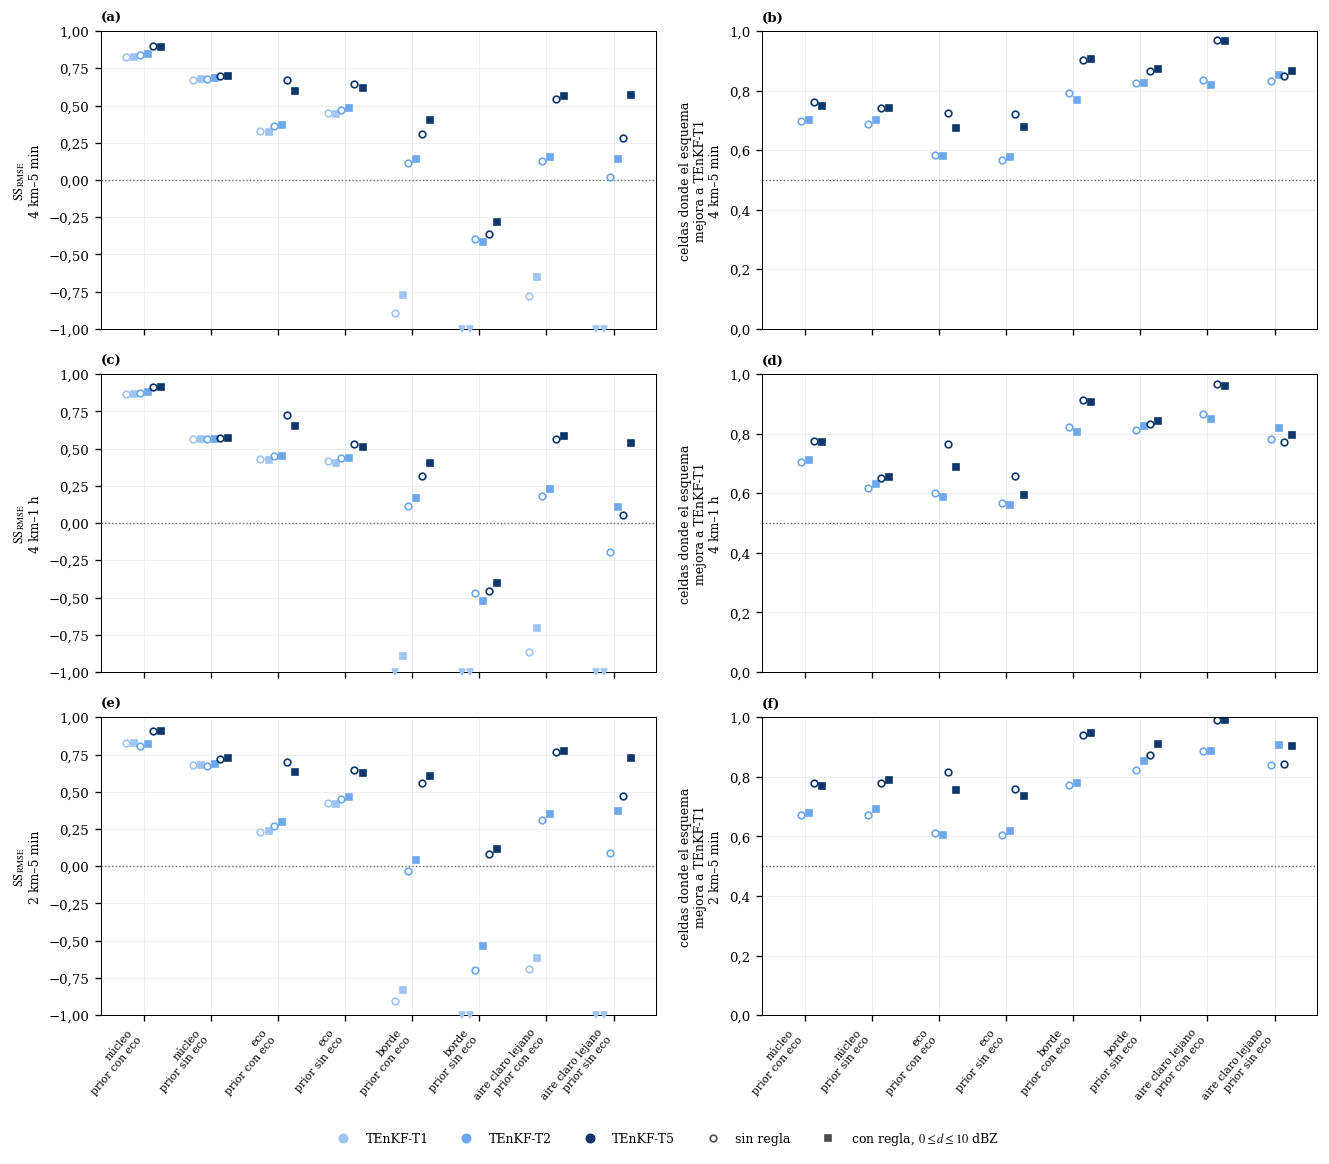

figures/es/N6_fig5b_regiones_crps.png  figures/en/N6_fig5b_regions_crps.png


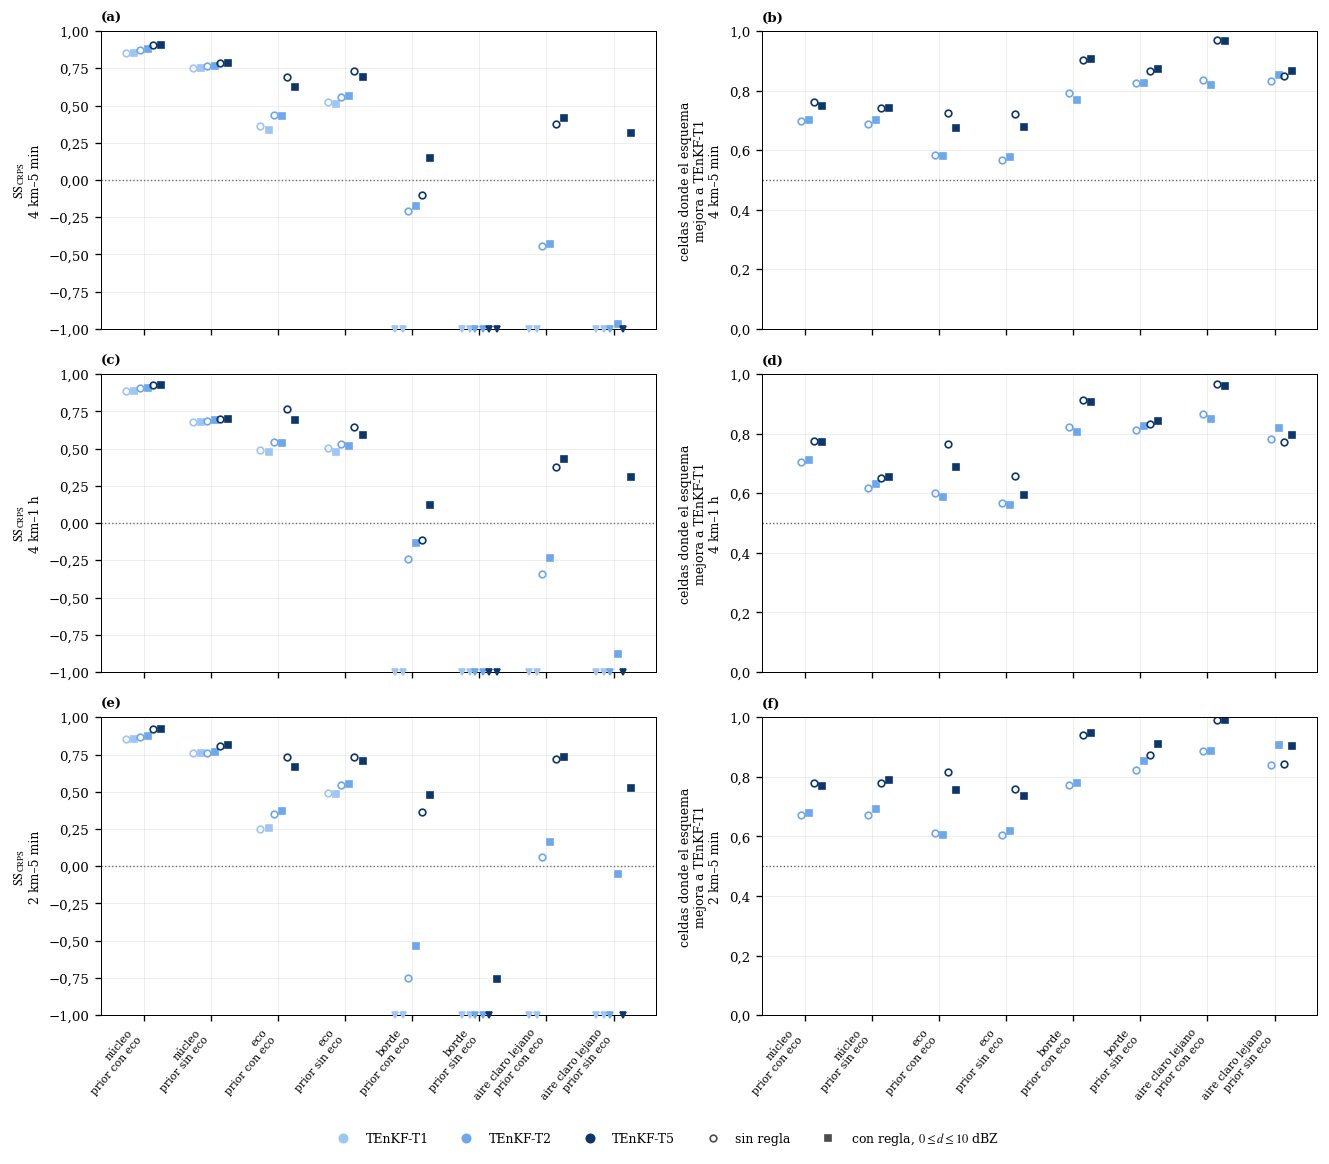

In [30]:
TRAMO_COLORS = {"d < 0": "#2a78d6", "[0, 10]": "#eb6834", "d > 10": "#8B0000"}
TRAMO_TEX = {"d < 0": r"$d < 0$", "[0, 10]": r"$0 \leq d \leq 10$", "d > 10": r"$d > 10$"}
FIG_SCH = (("TEnKF", 1), ("TEnKF", 2), ("TEnKF", 5))
SS_MIN = -1.0
NBR_TICKS = {"es": ("sin\nvecinos", "0", "(0, 0,25]", "(0,25, 0,5]", "(0,5, 0,75]", "(0,75, 1]"),
             "en": ("no\nneighbours", "0", "(0, 0.25]", "(0.25, 0.5]", "(0.5, 0.75]", "(0.75, 1]")}


def floor_plot(ax, x, y, ymin, color, **kw):
    """y con los valores bajo ymin marcados con un triángulo en el borde (N4)."""
    y = np.asarray(y, float)
    low = y < ymin
    ax.plot(x, np.where(low, np.nan, y), color=color, **kw)
    if low.any():
        ax.plot(np.asarray(x)[low], np.full(low.sum(), ymin), "v", color=color, ms=4, clip_on=False, zorder=6)


def scheme_legend(fig, lang, schemes, y=-0.06, extra=()):
    L = LABELS[lang]
    h = [Line2D([], [], color=nb.combo_color(m, n), marker="o", ls="none", ms=5, label=lab(m, n)) for m, n in schemes]
    for k, rg in (("none", NONE), ("rule", RULE)):
        st = REGLA_STYLE[rg]
        h.append(Line2D([], [], color="0.3", ls="none", marker=st["marker"], ms=4, mfc=st["mfc"] or "0.3", label=L[k]))
    fig.legend(handles=h + list(extra), loc="lower center", bbox_to_anchor=(0.5, y), ncol=len(h) + len(extra),
               frameon=False, fontsize=7.5)


def draw_fig5(lang, q="SS_RMSE"):
    V, L = nb.VOCAB[lang], LABELS[lang]
    cl = GROUPINGS["región"]
    x = np.arange(len(cl))
    fig, axes = plt.subplots(len(DATASETS), 2, sharex=True, squeeze=False, constrained_layout=True,
                             figsize=(nb.PAGE_W * 1.6, nb.PAGE_W * 0.42 * len(DATASETS) + 0.6))
    for r, ds in enumerate(DATASETS):
        t = H9.xs(("región", ds), level=("agrupacion", "dataset"))
        for c, (qq, ylab, guide) in enumerate(((q, V[q.lower()], 0.0), ("P_T1", L["p_t1"], 0.5))):
            ax = axes[r, c]
            ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
            for j, (m, n) in enumerate(FIG_SCH):
                if qq == "P_T1" and (m, n) == ("TEnKF", 1):
                    continue
                for rg in REGLAS:
                    st = REGLA_STYLE[rg]
                    col = nb.combo_color(m, n)
                    off = (j - 1) * 0.2 + (0.06 if rg == RULE else -0.06)
                    y = t.xs((rg, m, n), level=LV)[qq].reindex(cl)
                    floor_plot(ax, x + off, y, SS_MIN if qq.startswith("SS_") else -np.inf, col, ls="none",
                               marker=st["marker"], mfc=st["mfc"] or col, mec=col, ms=4)
            ax.set_ylim((SS_MIN, 1.0) if qq.startswith("SS_") else (0.0, 1.0))
            ax.set_ylabel(f"{ylab}\n{DSL[ds]}", fontsize=7.5)
    for ax in axes[-1]:
        ax.set_xticks(x)
        ax.set_xticklabels([f"{L[k.split(' | ')[0]]}\n{L[k.split(' | ')[1]]}" for k in cl], rotation=50, ha="right",
                           fontsize=6.5)
    for a, l in zip(axes.ravel(), "abcdefghi"):
        a.set_title(f"({l})", loc="left", fontsize=8, fontweight="bold")
    scheme_legend(fig, lang, FIG_SCH, y=-0.04)
    return fig


nb.save(draw_fig5, "N6_fig5_regiones", show=SHOW); plt.show()
nb.save(lambda lang: draw_fig5(lang, "SS_CRPS"), "N6_fig5b_regiones_crps", show=SHOW); plt.show()

figures/es/N6_fig6_observadas.png  figures/en/N6_fig6_observed.png


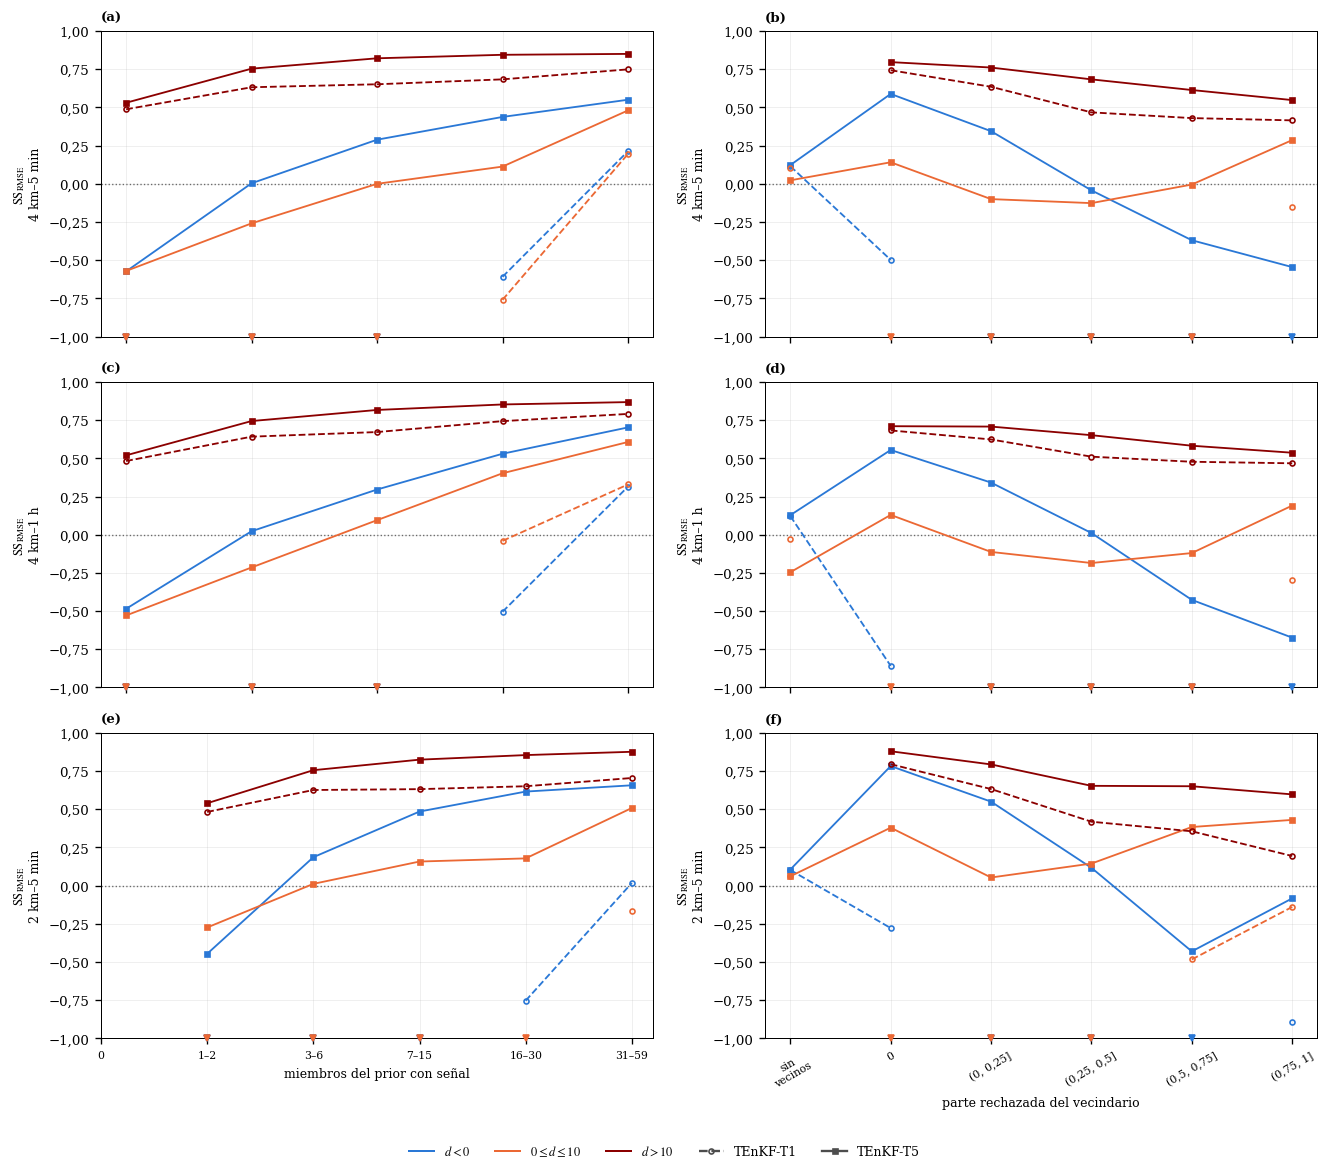

figures/es/N6_fig6b_observadas_crps.png  figures/en/N6_fig6b_observed_crps.png


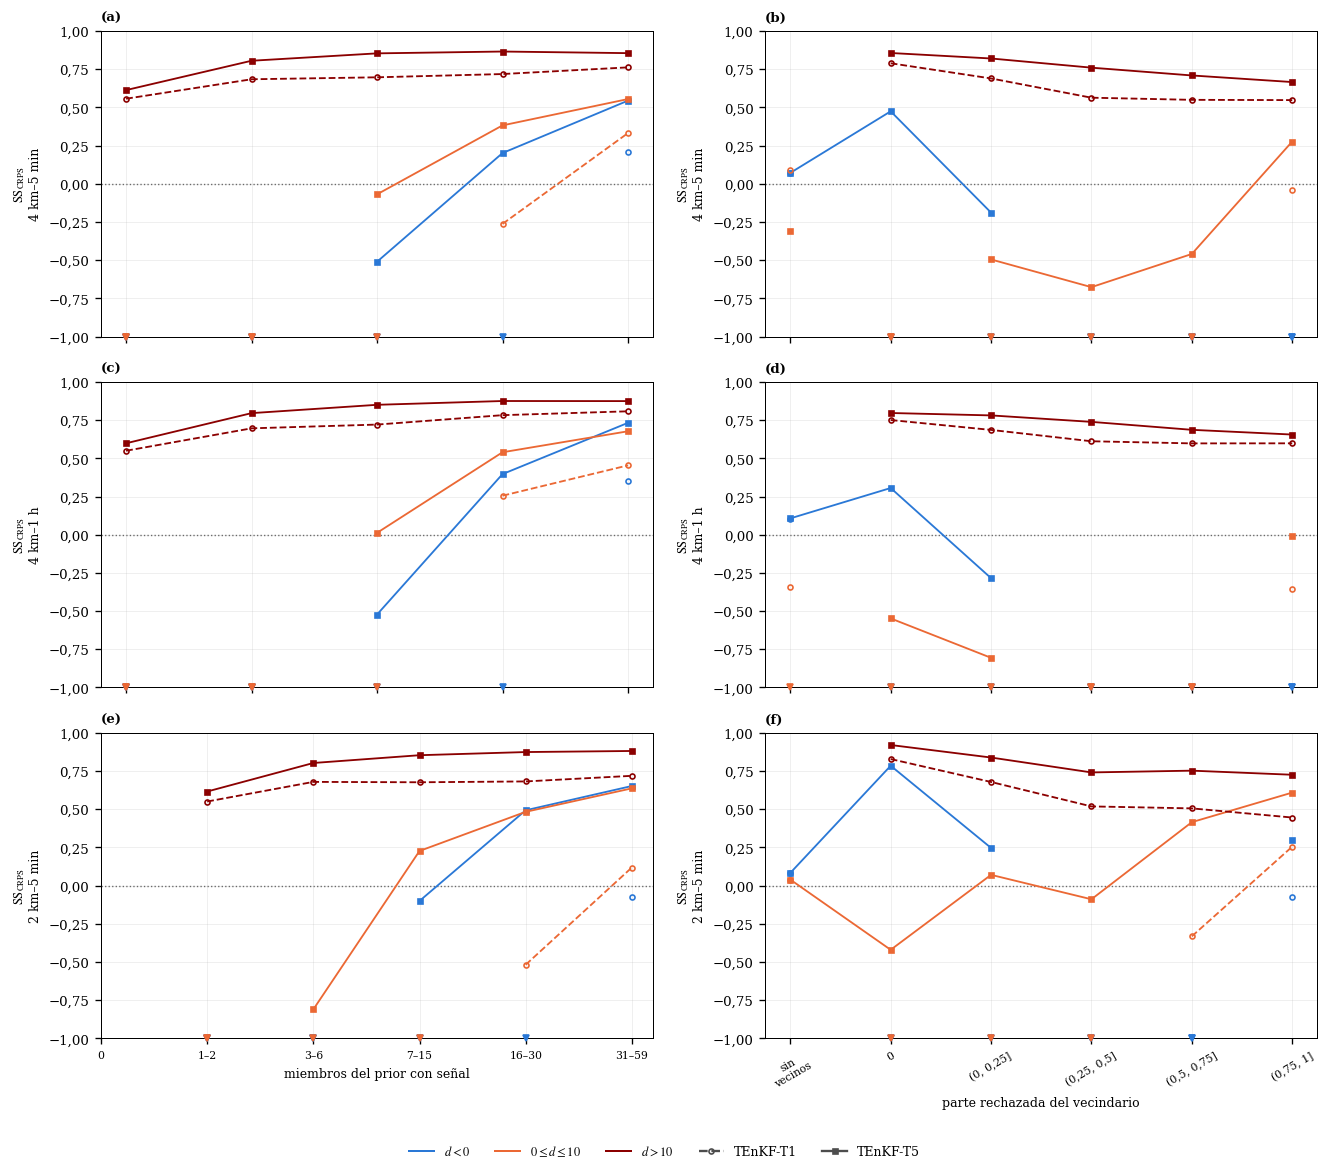

figures/es/N6_fig7_regla_observadas.png  figures/en/N6_fig7_rule_observed.png


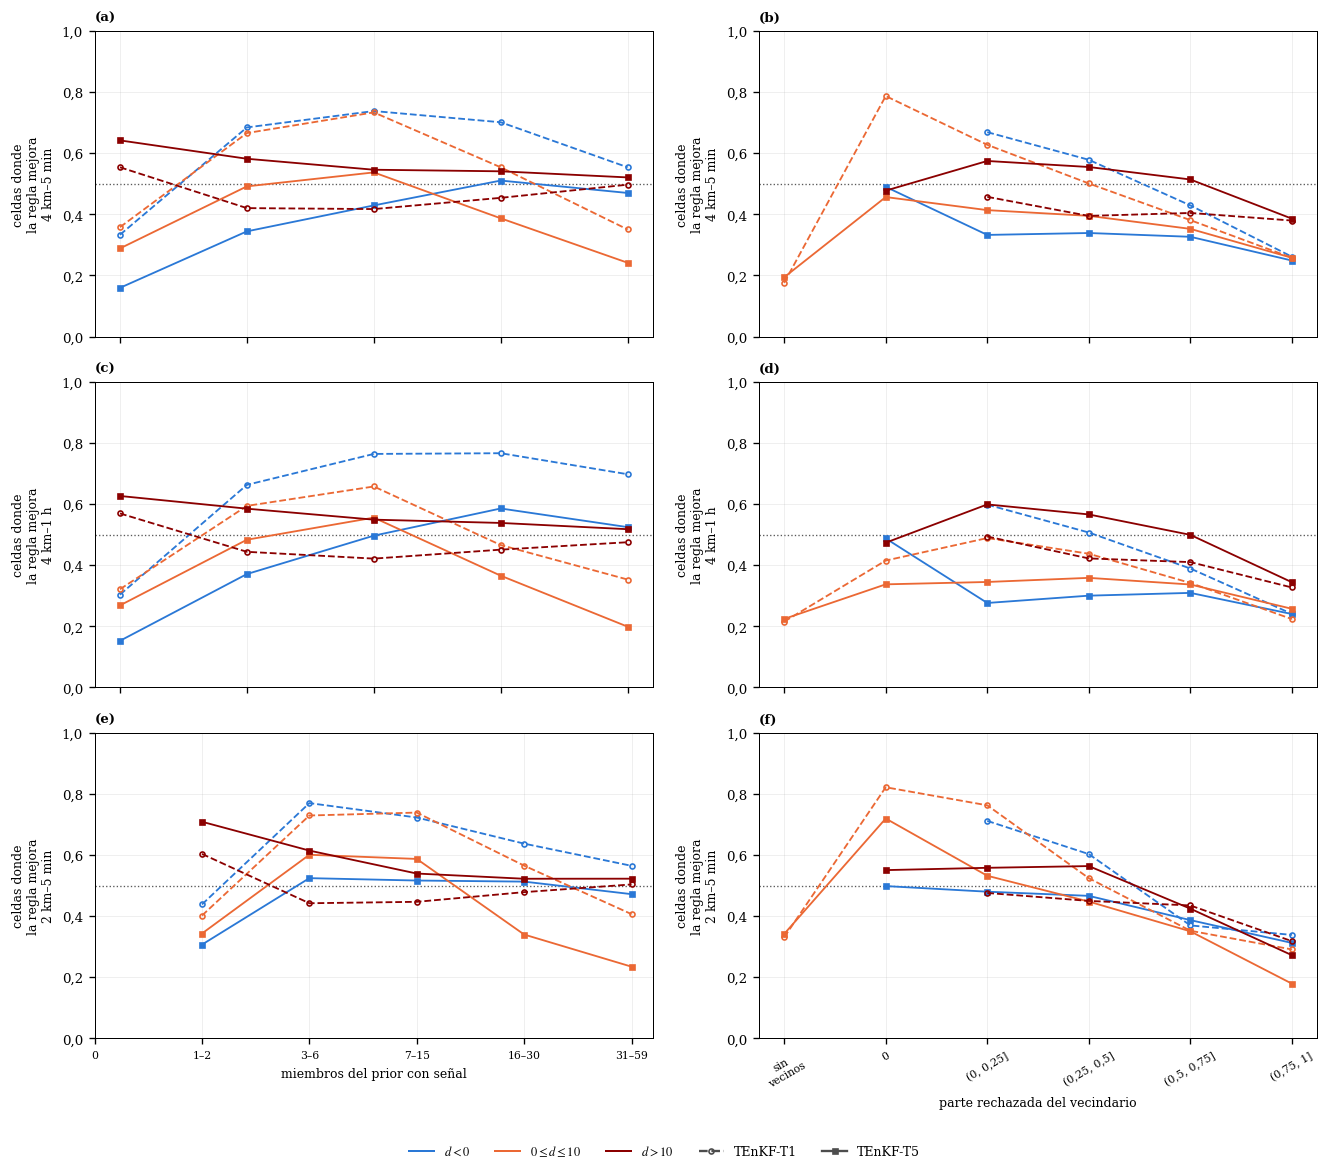

In [31]:
def draw_cross(lang, q, ylim, guide, ylabel, schemes):
    """Filas: datasets; columnas: miembros con eco y parte rechazada del vecindario; una línea por tramo."""
    V, L = nb.VOCAB[lang], LABELS[lang]
    cols = (("propia × miembros", NACT_LABELS, NACT_LABELS, L["nact"]),
            ("propia × vecinos", NBR_LABELS, NBR_TICKS[lang], L["nbr"]))
    fig, axes = plt.subplots(len(DATASETS), 2, sharex="col", squeeze=False, constrained_layout=True,
                             figsize=(nb.PAGE_W * 1.6, nb.PAGE_W * 0.42 * len(DATASETS) + 0.6))
    for r, ds in enumerate(DATASETS):
        for c, (gname, bins, ticks, xlab) in enumerate(cols):
            ax = axes[r, c]
            ax.axhline(guide, color="0.35", lw=0.8, ls=":", zorder=1)
            t = H9.xs((gname, ds), level=("agrupacion", "dataset"))
            x = np.arange(len(bins))
            for tr in TRAMOS:
                for (m, n), ls, mk in zip(schemes, ("--", "-"), ("o", "s")):
                    rg = NONE if q.startswith("SS_") else RULE
                    v = t.xs((rg, m, n), level=LV).reindex([f"{tr} | {b}" for b in bins])
                    y = np.where(v.N >= N_MIN_BIN, v[q], np.nan)
                    floor_plot(ax, x, y, ylim[0], TRAMO_COLORS[tr], ls=ls, marker=mk, ms=3, lw=1.1,
                               mfc="none" if ls == "--" else TRAMO_COLORS[tr])
            ax.set_ylim(*ylim)
            ax.set_ylabel(f"{ylabel}\n{DSL[ds]}", fontsize=7.5)
            if r == len(DATASETS) - 1:
                ax.set_xticks(x)
                ax.set_xticklabels(ticks, fontsize=6.5, rotation=30 if c == 1 else 0)
                ax.set_xlabel(xlab, fontsize=7.5)
    for a, l in zip(axes.ravel(), "abcdefghi"):
        a.set_title(f"({l})", loc="left", fontsize=8, fontweight="bold")
    h = [Line2D([], [], color=TRAMO_COLORS[tr], lw=1.2, label=TRAMO_TEX[tr]) for tr in TRAMOS]
    h += [Line2D([], [], color="0.3", ls=ls, marker=mk, ms=3, mfc="none" if ls == "--" else "0.3", label=lab(m, n))
          for (m, n), ls, mk in zip(schemes, ("--", "-"), ("o", "s"))]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=len(h), frameon=False, fontsize=7.5)
    return fig


nb.save(lambda lang: draw_cross(lang, "SS_RMSE", (SS_MIN, 1.0), 0.0, nb.VOCAB[lang]["ss_rmse"],
                                (("TEnKF", 1), ("TEnKF", 5))), "N6_fig6_observadas", show=SHOW); plt.show()
nb.save(lambda lang: draw_cross(lang, "SS_CRPS", (SS_MIN, 1.0), 0.0, nb.VOCAB[lang]["ss_crps"],
                                (("TEnKF", 1), ("TEnKF", 5))), "N6_fig6b_observadas_crps", show=SHOW); plt.show()
nb.save(lambda lang: draw_cross(lang, "P_regla", (0.0, 1.0), 0.5, LABELS[lang]["p_rule"],
                                (("TEnKF", 1), ("TEnKF", 5))), "N6_fig7_regla_observadas", show=SHOW); plt.show()

## 10 · El prior en las celdas observadas

Lo que el ensamble del prior sabe en cada celda observada (sección 0.3), por tramo de la innovación propia y por $N_{Z>0}$, con los 12 miembros verdad y las cuatro horas juntos. Para cada grupo:

- cuántas observaciones hay;
- la correlación entre $Z$ y $w$ y entre $Z$ y $q_g$ sobre los 59 miembros, en valor absoluto, y la parte con $|r| > 0{,}13$;
- el incremento lineal de $w$ de un paso por observación aislada, con sus factores: $|\Delta w| = |r|\,\sigma_w\,\sigma_Z/(\sigma_Z^2 + R)\,|d|$.

Las medias se toman sobre las observaciones con correlación definida. El incremento no es lo que hace la LETKF con todas las observaciones juntas: mide cuánto empuja cada observación a $w$ a través de la covarianza del prior, y si la banda empuja distinto que el resto. Con temperado, cada paso recalcula esa covarianza con el ensamble ya movido.

In [32]:
P10 = PO6.groupby(["dataset", "tramo", "nact"])[list(PO_SUMS)].sum()


def prior_table(P):
    with np.errstate(invalid="ignore", divide="ignore"):
        return pd.DataFrame({
            "obs [%]": 100 * P.n / P.n.groupby(level="dataset").transform("sum"),
            "|r(Z,w)|": P.s_abs_rw / P.n_r, "|r(Z,w)| > 0,13": P.n_big_rw / P.n_r,
            "|r(Z,qg)|": P.s_abs_rq / P.n_rq, "σ_w [m/s]": P.s_sd_w / P.n_r,
            "σ_Z/(σ_Z²+R)": P.s_gain_z / P.n_r, "|d| [dBZ]": P.s_abs_d / P.n_r,
            "|Δw| lineal [m/s]": P.s_abs_dw / P.n_r}, index=P.index)


T10 = prior_table(P10)
T10t = prior_table(PO6.groupby(["dataset", "tramo"])[list(PO_SUMS)].sum())
f3 = lambda v: f"{v:.3f}"
for ds in DATASETS:
    print(f"\n══════ {DSL[ds]} ══════")
    print("por tramo de la innovación propia:")
    print(T10t.xs(ds, level="dataset").reindex(TRAMOS).to_string(float_format=f3))
    print("\npor tramo y miembros del prior con eco:")
    print(T10.xs(ds, level="dataset").reindex(pd.MultiIndex.from_product([TRAMOS, NACT_LABELS])).to_string(float_format=f3))
T10.reset_index().to_csv(TAB / "N6_tab_prior_observadas.csv", index=False)


══════ 4 km–5 min ══════
por tramo de la innovación propia:
         obs [%]  |r(Z,w)|  |r(Z,w)| > 0,13  |r(Z,qg)|  σ_w [m/s]  σ_Z/(σ_Z²+R)  |d| [dBZ]  |Δw| lineal [m/s]
tramo                                                                                                        
d < 0     66.714     0.325            0.746      0.464      0.316         0.139      1.873              0.032
[0, 10]   28.013     0.295            0.693      0.469      0.240         0.161      1.909              0.025
d > 10     5.274     0.322            0.762      0.443      0.375         0.121     23.628              0.358

por tramo y miembros del prior con eco:
               obs [%]  |r(Z,w)|  |r(Z,w)| > 0,13  |r(Z,qg)|  σ_w [m/s]  σ_Z/(σ_Z²+R)  |d| [dBZ]  |Δw| lineal [m/s]
d < 0   0        0.000       NaN              NaN        NaN        NaN           NaN        NaN                NaN
        1–2     18.525     0.306            0.685      0.481      0.212         0.169      0.377              0.008


figures/es/N6_fig8_prior.png  figures/en/N6_fig8_prior.png


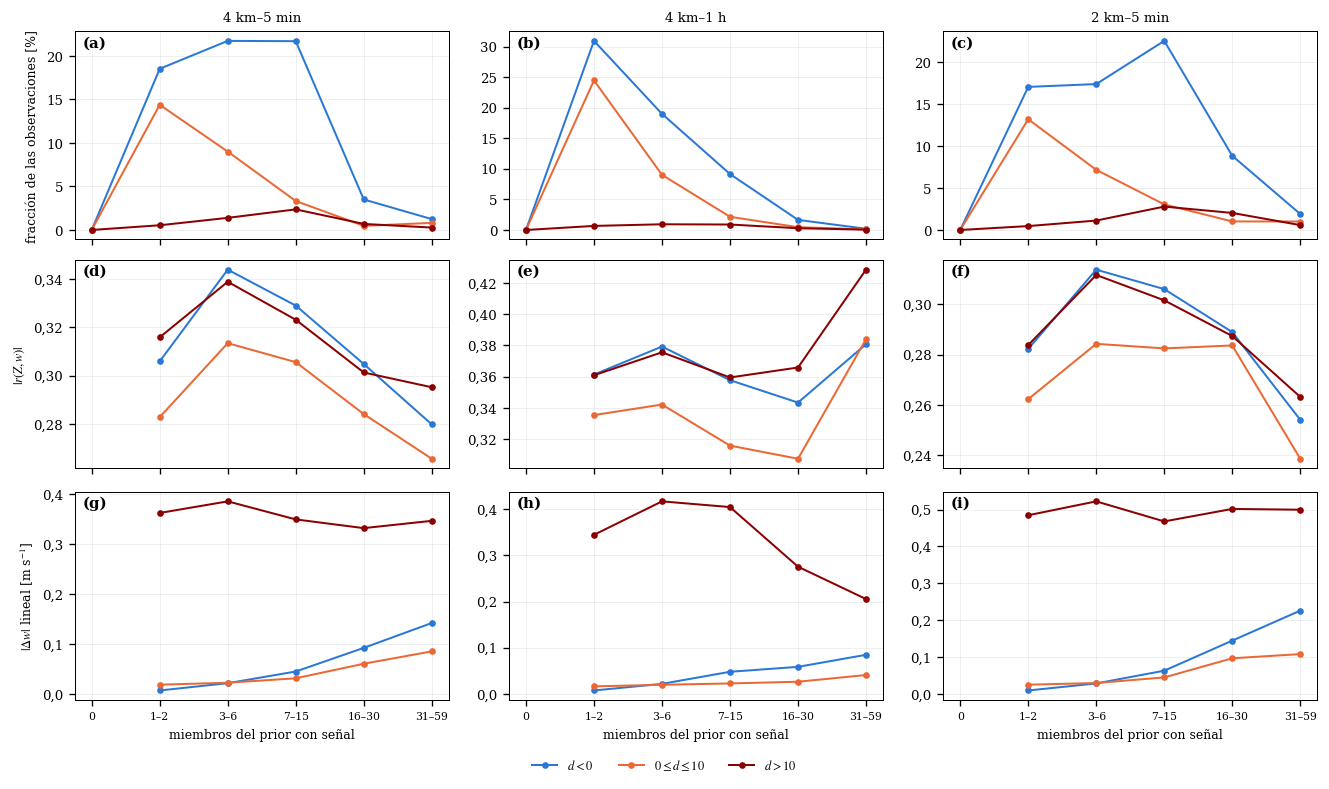

In [33]:
def draw_fig8(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    rows = (("obs [%]", L["share_obs"] + " [%]"), ("|r(Z,w)|", r"$|r(Z, w)|$"), ("|Δw| lineal [m/s]", L["dw_lin"]))
    x = np.arange(len(NACT_LABELS))
    fig, axes = plt.subplots(len(rows), len(DATASETS), sharex=True, squeeze=False, constrained_layout=True,
                             figsize=(nb.PAGE_W * 1.6, nb.PAGE_W * 0.9))
    for c, ds in enumerate(DATASETS):
        t = T10.xs(ds, level="dataset")
        for r, (q, ylab) in enumerate(rows):
            ax = axes[r, c]
            for tr in TRAMOS:
                y = t.reindex([(tr, b) for b in NACT_LABELS])[q].to_numpy()
                ax.plot(x, y, marker="o", ms=3, lw=1.2, color=TRAMO_COLORS[tr], label=TRAMO_TEX[tr])
            if r == 0:
                ax.set_title(DSL[ds], fontsize=8)
            if c == 0:
                ax.set_ylabel(ylab, fontsize=7.5)
            if r == len(rows) - 1:
                ax.set_xticks(x)
                ax.set_xticklabels(NACT_LABELS, fontsize=6.5)
                ax.set_xlabel(L["nact"], fontsize=7.5)
    for a, l in zip(axes.ravel(), "abcdefghi"):
        nb.panel_label(a, l)
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.05),
               ncol=len(TRAMOS), frameon=False, fontsize=7.5)
    return fig


nb.save(draw_fig8, "N6_fig8_prior", show=SHOW); plt.show()

## 11 · Eco falso y masa fuera del eco

Lo que en la sección 9 aparece como la ventaja del temperado en las celdas sin eco, visto en el campo. Con los conteos de la sección 0.4, por dataset, regla y esquema, agrupados sobre los 12 miembros verdad y las cuatro horas (la banda es la desviación entre los 12 del mismo cociente por miembro):

- **eco falso / prior**: celdas con la verdad bajo 5 dBZ y la media de $H(\mathbf{x}^a)$ en o sobre 5 (o 20) dBZ, sobre las mismas en el prior. Mayor que 1: el análisis crea eco donde no hay;
- **masa fuera / prior**: la masa de hidrometeoros ($q_r + q_s + q_g$, media del ensamble) fuera del contorno de 5 dBZ de la verdad, análisis sobre prior;
- **eco perdido / prior**: celdas con eco en la verdad que el análisis deja bajo 5 dBZ, sobre las del prior.

El mapa es un caso (`MAP_CASE`): el máximo en la columna de la media de $H(\mathbf{x})$, con el contorno de 5 dBZ de la verdad, para la verdad, el prior y TEnKF-T1, T2 y T5 con y sin regla. El número de cada panel es el de celdas 3D con eco falso en todo el dominio.

**Por qué aparece el eco falso.** Con la sección 0.6, tres preguntas:

1. ¿Qué $d$ dan las observaciones débiles? El reparto de $y_o$ por grupo de verdad, contra el esperado de $\max(\text{verdad} + \varepsilon, 0)$, y la $d$ de las observaciones con $0 < y_o < 5$.
2. ¿Cuánto más alto es $H(\bar{\mathbf{x}}^f)$, el $H$ de la media del prior, que la media de $H$? Si el análisis lleva a todos los miembros hacia el estado medio, el $Z$ de cada uno se acerca a $H(\bar{\mathbf{x}}^f)$. La tabla, por $N_{Z>0}$, en `MAP_CASE`, junto al máximo de $H$ entre los 59 miembros.
3. ¿Hay eco falso en las celdas con los 59 miembros en 0 dBZ? No tienen observación (el filtro de varianza las excluye), así que solo las cambian las observaciones vecinas. La tabla de las celdas con $N_{Z>0} = 0$, al final de la sección, muestra que el análisis casi no las mueve: el eco falso está en celdas donde al menos un miembro del prior tiene señal.

**El corte y los mapas de `MAP_CASE`.** La línea del corte (`CUT_LINE`, norte–sur) se dibuja en la figura 10 y en la 10c (línea de trazos).

- **Figura 10b**, corte vertical, altura contra latitud. Puntos cada un espaciamiento de grilla a lo largo de la línea, cada uno con la columna más cercana, sin interpolar. Fila 1: la verdad, $y_o$ y $d$, estas dos solo en las celdas observadas (línea punteada gris: su borde; contorno violeta: $d = 10$ dBZ). Fila 2: $N_{Z>0}$ del prior, la media de $H$ del prior y $H(\bar{\mathbf{x}}^f)$. Filas 3 y 4: la media de $H$ del posterior de TEnKF-T1, T2 y T5, sin y con regla. Contorno negro: 5 dBZ de la verdad.
- **Figura 10c**, mapa de diagnóstico: el máximo en la columna de $y_o$, de $N_{Z>0}$ y de $H(\bar{\mathbf{x}}^f)$, y la media de $d$ sobre las observaciones de la columna. Todas las observaciones tienen $N_{Z>0} \ge 1$: el filtro de varianza ya excluye las celdas sin señal.
- Escala de $Z$ en las dos: 0 dBZ exacto sin color; $(0, 1)$ y $[1, 5)$ en dos grises claros; desde 5 dBZ, las clases y los colores de la figura 10. $d$ en rojo cuando la observación está sobre la media del prior.
- **Figura 10d**, en las celdas alcanzadas de la línea base con la verdad bajo 5 dBZ: histograma 2D (celdas por casilla de 1 dBZ, sin normalizar, escala logarítmica) de la media de $H$ del posterior de TEnKF-T1, sin y con regla, contra el máximo de $H$ entre los 59 miembros del prior. Línea de trazos: la diagonal; $\rho_s$: correlación de Spearman. La tabla anterior a la figura da, por tramo de $N_{Z>0}$ (incluido $N_{Z>0} = 0$, que también está en la figura), las medianas del posterior, de $H(\bar{\mathbf{x}}^f)$ y del máximo de $H$, la correlación de Spearman del posterior con cada uno, y en las celdas con eco falso la mediana de máximo de $H$ menos media de $H(\mathbf{x}^a)$.

**Eco falso sin señal en el prior.** En `MAP_CASE`, las celdas alcanzadas de la línea base con $N_{Z>0} = 0$, para TEnKF-T1 sin y con regla: cuántas quedan con la media de $H(\mathbf{x}^a)$ en o sobre 5 dBZ y qué parte son del eco falso del caso; en ellas, el máximo entre los 59 miembros de $H$ sin censurar (piso `HX_RAW_MIN`), la parte donde los 59 miembros tienen $q_g$, $q_r$ y $q_s$ bajo `Q0`, y la distancia a la celda observada más cercana en unidades de $L$. Al lado, como referencia, las mismas cifras de las celdas con $N_{Z>0} = 0$ que quedan entre 0 y 5 dBZ y de las que quedan en 0 dBZ.

**Eco falso por tramo de $N_{Z>0}$, todos los casos.** Con la sección 0.7, por dataset y esquema (TEnKF-T1, T2, T5 y AOEI), agrupado sobre las 12 verdades y las cuatro horas, ± la desviación entre verdades: el eco falso como parte de las celdas alcanzadas con la verdad bajo 5 dBZ, sin y con regla; la reducción por la regla, $1 - $ con / sin; y la brecha entre el miembro máximo del prior y la media de $H(\mathbf{x}^a)$ en las celdas con eco falso (mediana del histograma agrupado y media). Para TEnKF-T1, además, el eco falso según el prior: el del prior, el creado (prior bajo 5 dBZ, posterior en o sobre 5), el heredado (los dos en o sobre 5) y el eliminado (prior en o sobre 5, posterior bajo 5), con el cambio medio de la media de $H$ en las heredadas y la reducción por la regla del creado y del heredado por separado.


In [34]:
import cartopy.crs as ccrs

# La línea del corte vertical de MAP_CASE (figura 10b): norte–sur, longitud fija, de lat[0] a lat[1].
# Se dibuja también en los mapas de las figuras 10 y 10c.
CUT_LINE = {"lon": -61.5, "lat": (-28.5, -38.5)}


def draw_cut_line(ax):
    ax.plot([CUT_LINE["lon"]] * 2, CUT_LINE["lat"], color="k", lw=0.9, ls="--",
            transform=ccrs.PlateCarree(), zorder=4)

In [35]:
def fe_ratio(FE, num, den):
    keys = ["dataset", "regla", "method", "ntemp"]
    g = FE.groupby(keys)[[num, den]].sum()
    t = FE.groupby(keys + ["tm"])[[num, den]].sum()
    return g[num] / g[den], (t[num] / t[den]).groupby(level=keys).std(ddof=1)


FE6 = FE6.assign(ma_out=sum(FE6[f"ma_{q}_out"] for q in MASS_Q), mf_out=sum(FE6[f"mf_{q}_out"] for q in MASS_Q),
                 mt_in=sum(FE6[f"mt_{q}_in"] for q in MASS_Q))
FE_Q = {"false5": ("ana_false5", "prior_false5"), "false20": ("ana_false20", "prior_false20"),
        "mass_out": ("ma_out", "mf_out"), "missed5": ("ana_missed5", "prior_missed5")}
T11 = pd.DataFrame({f"{q}{s}": v for q, (a, b) in FE_Q.items() for s, v in zip(("", "_sd"), fe_ratio(FE6, a, b))})
out = {}
for q in FE_Q:
    a, b = T11[q].xs(NONE, level="regla"), T11[q].xs(RULE, level="regla")
    out[f"{q} sin → con"] = [f"{x:.2f} → {y:.2f}" for x, y in zip(a, b)]
print("Eco falso, masa fuera del eco y eco perdido, análisis / prior (agrupado sobre 12 verdades × 4 horas)")
print(pd.DataFrame(out, index=[f"{DSL[d]} {lab(m, n)}" for d, m, n in a.index]).to_string())
_p = FE6.drop_duplicates(["dataset", "hour", "tm"]).groupby("dataset")[["prior_false5", "n_echo", "mf_out", "mt_in"]].sum()
print("\nEl prior: celdas con eco falso / celdas con eco en la verdad, y masa fuera del eco / masa de la verdad en el eco")
print(pd.DataFrame({"eco falso / eco verdad": _p.prior_false5 / _p.n_echo, "masa fuera / masa verdad en eco": _p.mf_out / _p.mt_in})
      .rename(index=DSL).to_string(float_format=lambda v: f"{v:.2f}"))
T11.reset_index().to_csv(TAB / "N6_tab_eco_falso.csv", index=False)


Eco falso, masa fuera del eco y eco perdido, análisis / prior (agrupado sobre 12 verdades × 4 horas)
                    false5 sin → con false20 sin → con mass_out sin → con missed5 sin → con
4 km–5 min AOEI          4.78 → 2.20     88.29 → 26.35        0.66 → 0.43       0.24 → 0.39
4 km–5 min TEnKF-T1      4.92 → 2.51    115.39 → 62.44        0.75 → 0.54       0.11 → 0.16
4 km–5 min TEnKF-T2      0.80 → 0.73       6.08 → 5.32        0.21 → 0.19       0.41 → 0.40
4 km–5 min TEnKF-T3      1.51 → 0.67     20.41 → 17.14        0.23 → 0.15       0.10 → 0.20
4 km–5 min TEnKF-T4      0.83 → 0.58       3.05 → 3.66        0.16 → 0.12       0.21 → 0.25
4 km–5 min TEnKF-T5      0.51 → 0.33       1.97 → 2.63        0.14 → 0.10       0.12 → 0.22
4 km–1 h AOEI           11.41 → 3.27    471.98 → 77.13        0.78 → 0.40       0.44 → 0.61
4 km–1 h TEnKF-T1       11.91 → 3.98   554.86 → 188.21        0.86 → 0.49       0.20 → 0.28
4 km–1 h TEnKF-T2        1.39 → 1.00     17.58 → 15.51        0.24 → 0.

figures/es/N6_fig9_eco_falso.png  figures/en/N6_fig9_false_echo.png


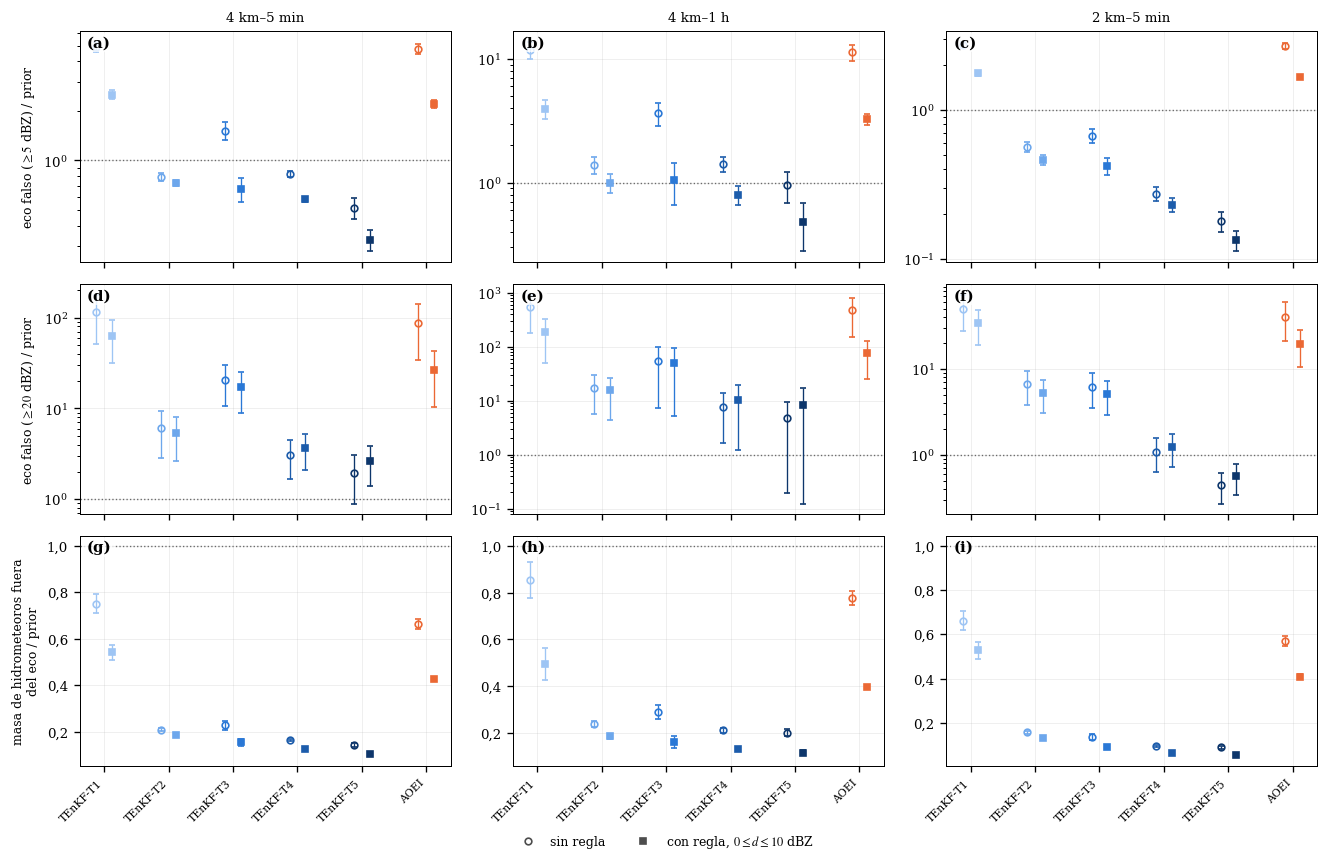

In [36]:
FIG11_SCH = tuple(SCHEMES)


def draw_fig9(lang):
    L = LABELS[lang]
    rows = (("false5", L["fe5"], True), ("false20", L["fe20"], True), ("mass_out", L["mass_out"], False))
    x = np.arange(len(FIG11_SCH))
    fig, axes = plt.subplots(len(rows), len(DATASETS), sharex=True, squeeze=False, constrained_layout=True,
                             figsize=(nb.PAGE_W * 1.6, nb.PAGE_W * 1.0))
    for r, (q, ylab, logy) in enumerate(rows):
        for c, ds in enumerate(DATASETS):
            ax = axes[r, c]
            ax.axhline(1.0, color="0.35", lw=0.8, ls=":", zorder=1)
            for j, (m, n) in enumerate(FIG11_SCH):
                col = nb.combo_color(m, n)
                for rg in REGLAS:
                    st = REGLA_STYLE[rg]
                    v, e = T11.loc[(ds, rg, m, n), q], T11.loc[(ds, rg, m, n), f"{q}_sd"]
                    ax.errorbar(j + (0.12 if rg == RULE else -0.12), v, yerr=e, fmt=st["marker"], mfc=st["mfc"] or col,
                                mec=col, color=col, ms=4, capsize=2, elinewidth=0.8)
            if logy:
                ax.set_yscale("log")
            if r == 0:
                ax.set_title(DSL[ds], fontsize=8)
            if c == 0:
                ax.set_ylabel(ylab, fontsize=7.5)
            ax.set_xticks(x)
            ax.set_xticklabels([lab(m, n) for m, n in FIG11_SCH], rotation=45, ha="right", fontsize=6.5)
    for a, l in zip(axes.ravel(), "abcdefghi"):
        nb.panel_label(a, l)
    scheme_legend(fig, lang, (), y=-0.04)
    return fig


nb.save(draw_fig9, "N6_fig9_eco_falso", show=SHOW); plt.show()


In [37]:
# MAP_CASE (dataset, hora, miembro verdad) y MAP_SCH: sección 0.6
MAP_EXTENT = (-64.0, -56.0, -38.5, -28.0)    # lon, lon, lat, lat
_ds, _hh, _tm = MAP_CASE
with np.load(scheme_file(_ds, _hh, NONE, "TEnKF", 1, _tm)) as z:
    _tr, _hf = np.nan_to_num(z["truth_hx_field"]), np.nan_to_num(z["hxf_mean_field"])
MAP_F = {"truth": _tr.max(axis=2), "prior": _hf.max(axis=2)}
MAP_N = {"prior": int(np.count_nonzero((_tr < ECHO_DBZ) & (_hf >= ECHO_DBZ)))}
for rg in REGLAS:
    for n in MAP_SCH:
        with np.load(scheme_file(_ds, _hh, rg, "TEnKF", n, _tm)) as z:
            _ha = np.nan_to_num(z["hxa_mean_field"])
        MAP_F[(rg, n)] = _ha.max(axis=2)
        MAP_N[(rg, n)] = int(np.count_nonzero((_tr < ECHO_DBZ) & (_ha >= ECHO_DBZ)))
MAP_ECHO = (_tr.max(axis=2) >= ECHO_DBZ).astype(float)
_r = FE6[(FE6.dataset == _ds) & (FE6.hour == _hh) & (FE6.tm == _tm) & (FE6.method == "TEnKF")]
for (rg, n), v in ((k, v) for k, v in MAP_N.items() if k != "prior"):
    assert v == int(_r[(_r.regla == rg) & (_r.ntemp == n)].ana_false5.iloc[0]), "el mapa no es el de la sección 0.4"
MAP_GEO = nb.load_subset(nb.subset_path(_hh, _ds), keys=("lats", "lons"))
del _tr, _hf, _ha
print(f"{DSL[_ds]}, {_hh} UTC, miembro verdad {_tm}: celdas 3D con eco falso (≥ {ECHO_DBZ:g} dBZ)")
print(pd.Series({"prior": MAP_N["prior"], **{f"{lab('TEnKF', n)} {'sin' if rg == NONE else 'con'}": MAP_N[(rg, n)]
                                             for n in MAP_SCH for rg in REGLAS}}).to_string())


4 km–5 min, 20 UTC, miembro verdad 0: celdas 3D con eco falso (≥ 5 dBZ)
prior            65706
TEnKF-T1 sin    304022
TEnKF-T1 con    157698
TEnKF-T2 sin     49651
TEnKF-T2 con     46266
TEnKF-T5 sin     29423
TEnKF-T5 con     19601


/home/jorge.gacitua/datosdemerzel/miniconda3/envs/intermediate_exp/lib/python3.8/site-packages/cartopy/mpl/geoaxes.py:1597: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  X, Y, C, shading = self._pcolorargs('pcolormesh', *args,


/nfsmounts/munin/datos/jorge.gacitua/WRF_Single_Cycle_Assimilation/Notebooks/nbcommon.py:763: UserWarning: constrained_layout not applied.  At least one axes collapsed to zero width or height.
  f.savefig(p, dpi=dpi, bbox_inches="tight")


figures/es/N6_fig10_mapa_eco_falso.png  figures/en/N6_fig10_false_echo_map.png


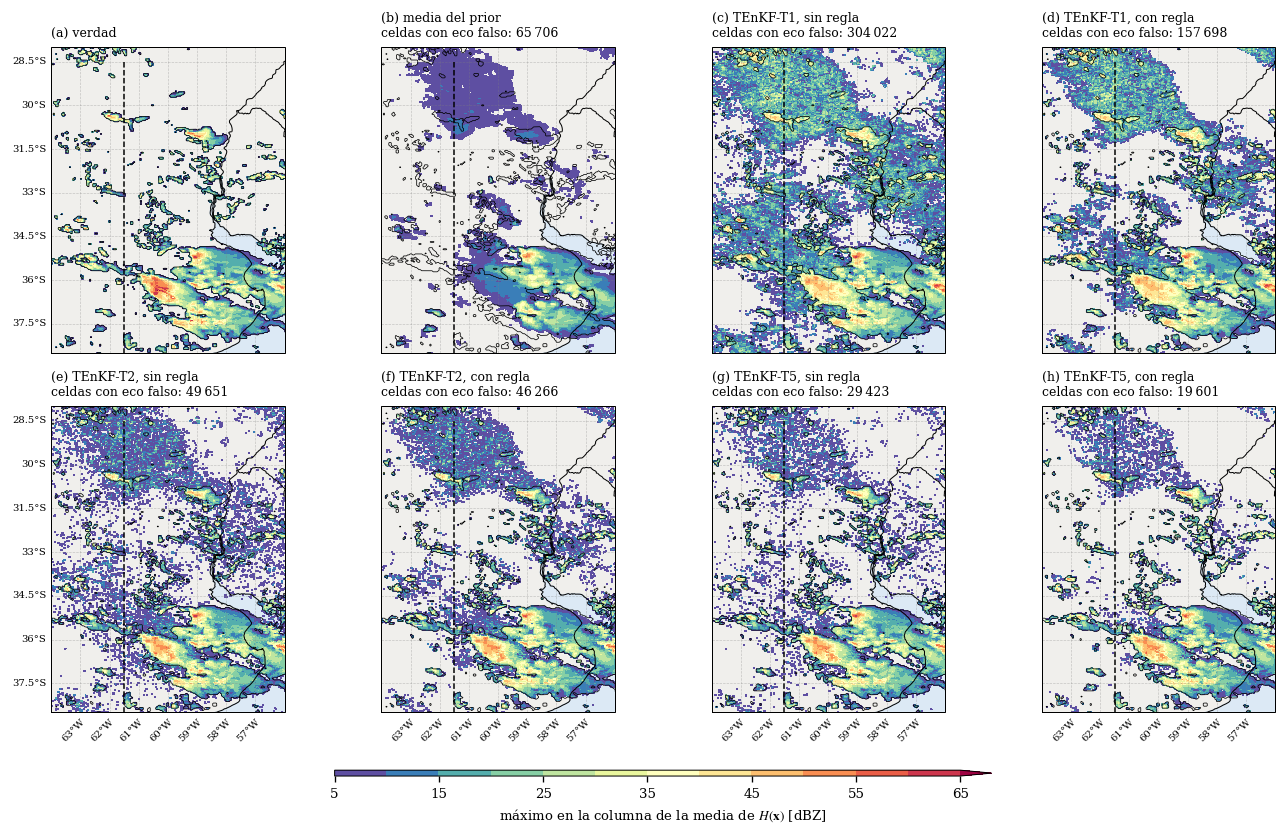

In [38]:
import cartopy.crs as ccrs
from matplotlib.colors import BoundaryNorm

MAP_LEV = np.arange(5, 66, 5)
MAP_NORM = BoundaryNorm(MAP_LEV, plt.get_cmap(nb.DBZ_CMAP).N, extend="max")


def draw_fig10(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    pan = [("truth", V["truth"], None), ("prior", L["prior_mean"], MAP_N["prior"])]
    pan += [((rg, n), f"{lab('TEnKF', n)}, {L['none' if rg == NONE else 'rule_short']}", MAP_N[(rg, n)])
            for n in MAP_SCH for rg in REGLAS]
    fig, axes = plt.subplots(2, 4, figsize=(nb.PAGE_W * 1.6, nb.PAGE_W * 1.0), constrained_layout=True,
                             subplot_kw=dict(projection=ccrs.PlateCarree()))
    lats, lons = MAP_GEO["lats"], MAP_GEO["lons"]
    for a, (ax, (key, title, nfe)) in enumerate(zip(axes.flat, pan)):
        nb.setup_map(ax, extent=MAP_EXTENT, left_labels=(a % 4 == 0), bottom_labels=(a >= 4))
        f = MAP_F[key]
        m = nb.map_field(ax, lats, lons, np.where(f < MAP_LEV[0], np.nan, f), cmap=nb.DBZ_CMAP, norm=MAP_NORM,
                         transform=ccrs.PlateCarree(), zorder=1)
        ax.contour(lons, lats, MAP_ECHO.T if MAP_ECHO.T.shape == lats.shape else MAP_ECHO, levels=[0.5],
                   colors="k", linewidths=0.45, transform=ccrs.PlateCarree(), zorder=3)
        draw_cut_line(ax)
        t = f"({'abcdefgh'[a]}) {title}"
        if nfe is not None:
            t += f"\n{L['false_echo']}: {nb.fmt(nfe, lang, ',d')}"
        ax.set_title(t, fontsize=7.5, loc="left")
    cb = fig.colorbar(m, ax=axes[-1, :], orientation="horizontal", shrink=0.5, aspect=35, extend="max",
                      ticks=MAP_LEV[::2])
    cb.set_label(L["colmax"], fontsize=8)
    return fig


nb.save(draw_fig10, "N6_fig10_mapa_eco_falso", show=SHOW); plt.show()


In [39]:
# ── a) El reparto de y_o por grupo de verdad, observado y esperado con y_o = max(verdad + ε, 0) ──
_lo = LOW6.groupby(["dataset", "grupo"])[["n"] + [f"{p}_{c}" for p in ("n", "e") for c in YO_COLS]].sum()
_t5 = _lo[_lo.index.get_level_values("grupo") != "verdad ≥ 5"].groupby(level="dataset").sum()
_t5.index = pd.MultiIndex.from_product([_t5.index, ["verdad < 5"]], names=_lo.index.names)
_all = _lo.groupby(level="dataset").sum()
_all.index = pd.MultiIndex.from_product([_all.index, ["todas"]], names=_lo.index.names)
_lo = pd.concat([_lo, _t5, _all]).reindex(
    [(ds, g) for ds in DATASETS for g in ("todas", "verdad < 5") + TRUTH_GROUPS])
T11_YO = pd.DataFrame({"obs": _lo.n, "parte de las obs (%)": 100 * _lo.n / _lo.n.groupby(level="dataset").transform("max"),
                       **{f"y_o {k} (%)": 100 * _lo[f"n_{c}"] / _lo.n for k, c in zip(YO_CLASSES, YO_COLS)},
                       **{f"esp. {k} (%)": 100 * _lo[f"e_{c}"] / _lo.n for k, c in zip(YO_CLASSES, YO_COLS)}})
# El ruido positivo: verdad = 0 y y_o > 0, como parte de todas las observaciones (una línea por dataset)
RUIDO = "ruido positivo (verdad = 0, y_o > 0)"
_rp = _lo.xs("verdad = 0", level="grupo")[[f"n_{c}" for c in YO_COLS[1:]]].sum(axis=1)
_rp = pd.DataFrame({"obs": _rp, "parte de las obs (%)": 100 * _rp / _lo.xs("todas", level="grupo").n})
_rp.index = pd.MultiIndex.from_product([_rp.index, [RUIDO]], names=_lo.index.names)
T11_YO = pd.concat([T11_YO, _rp]).reindex(
    [(ds, g) for ds in DATASETS for g in ("todas", RUIDO, "verdad < 5") + TRUTH_GROUPS])
T11_YO.index = [f"{DSL[d]} · {g}" for d, g in T11_YO.index]
print("a) Reparto de y_o por grupo de verdad en la celda observada, 12 verdades × 4 horas.")
print("   'esp.': lo esperado con y_o = max(verdad + ε, 0), ε ~ N(0, R), sumado sobre las observaciones del grupo.")
print(T11_YO.to_string(float_format=lambda v: f"{v:.2f}", formatters={"obs": "{:,.0f}".format}, na_rep="—"))

# ── b) La referencia: max(ε, 0) con ε ~ N(0, R), la que corresponde a verdad = 0 ──
_R = RUNS6.R.unique()
assert len(_R) == 1, "R distinto entre corridas"
T11_EPS = pd.Series(100 * yo_class_prob(np.zeros(1), float(_R[0]))[0], index=[f"P({k})" for k in YO_CLASSES])
print(f"\nb) Reparto de max(ε, 0), ε ~ N(0, R = {float(_R[0]):g} dBZ²), en %:")
print(T11_EPS.to_string(float_format=lambda v: f"{v:.2f}"))

# ── Hipótesis 1: la d de las observaciones con 0 < y_o < 5 ──
_dl = LOW6.groupby("dataset")[[f"n_{c}" for c in D_COLS] + ["s_d_low"]].sum()
_nl = _dl[[f"n_{c}" for c in D_COLS]].sum(axis=1)
T11_DLOW = pd.DataFrame({"obs con 0 < y_o < 5": _nl, **{f"{k} (%)": 100 * _dl[f"n_{c}"] / _nl for k, c in zip(D_LOW, D_COLS)},
                         "d media": _dl.s_d_low / _nl}).rename(index=DSL)
print("\nd de las observaciones con 0 < y_o < 5 dBZ, 12 verdades × 4 horas:")
print(T11_DLOW.to_string(float_format=lambda v: f"{v:.2f}", formatters={"obs con 0 < y_o < 5": "{:,.0f}".format}))

# ── H(x̄_f) contra la media y el máximo de H del prior, por miembros con señal, en MAP_CASE ──
_nb = nbin_fine(CASE["nact"])
_hm, _hb, _hx, _tr = np.nan_to_num(CASE["hxf_mean"]).astype(np.float64), CASE["hx_xbar"].astype(np.float64), \
    CASE["hxf_max"].astype(np.float64), CASE["truth"].astype(np.float64)


def hxbar_table(sel):
    rows = {}
    for b, lbl in enumerate(N_FINE):
        m = sel & (CASE["nact"] >= 1) & (_nb == b)
        if not m.any():
            continue
        g = _hb[m] - _hm[m]
        rows[lbl] = {"celdas": int(m.sum()), "verdad < 5 (%)": 100 * (_tr[m] < ECHO_DBZ).mean(),
                     "media H": _hm[m].mean(), "H(x̄_f)": _hb[m].mean(), "máx H": _hx[m].mean(),
                     "mediana H(x̄_f) − media H": np.median(g), "P(H(x̄_f) > media H)": (g > 0).mean(),
                     "P(media H ≥ 5)": (_hm[m] >= ECHO_DBZ).mean(), "P(H(x̄_f) ≥ 5)": (_hb[m] >= ECHO_DBZ).mean(),
                     "P(máx H ≥ 5)": (_hx[m] >= ECHO_DBZ).mean()}
    return pd.DataFrame(rows).T.rename_axis("N_Z>0")


_ds, _hh, _tm = MAP_CASE
T11_HXBAR = {"todas": hxbar_table(np.ones_like(CASE["valid"])),
             "alcanzadas, verdad < 5": hxbar_table(CASE["valid"] & (_tr < ECHO_DBZ))}
for k, t in T11_HXBAR.items():
    print(f"\nH de la media del prior contra la media y el máximo de H de los 59 miembros, por N_Z>0 · "
          f"{DSL[_ds]}, {_hh} UTC, verdad {_tm} · celdas: {k} (medias en dBZ)")
    print(t.to_string(float_format=lambda v: f"{v:.2f}", formatters={"celdas": "{:,.0f}".format}))
pd.concat(T11_HXBAR, names=["conjunto"]).reset_index().to_csv(TAB / "N6_tab_H_media_prior.csv", index=False)
T11_YO.rename_axis("grupo").reset_index().to_csv(TAB / "N6_tab_obs_bajas.csv", index=False)

a) Reparto de y_o por grupo de verdad en la celda observada, 12 verdades × 4 horas.
   'esp.': lo esperado con y_o = max(verdad + ε, 0), ε ~ N(0, R), sumado sobre las observaciones del grupo.
                                                          obs  parte de las obs (%)  y_o 0 (%)  y_o (0, 1) (%)  y_o [1, 5) (%)  y_o ≥ 5 (%)  esp. 0 (%)  esp. (0, 1) (%)  esp. [1, 5) (%)  esp. ≥ 5 (%)
4 km–5 min · todas                                 42,724,284                100.00      45.22           15.71           29.33         9.73       45.25            15.70            29.31          9.73
4 km–5 min · ruido positivo (verdad = 0, y_o > 0)  19,236,500                 45.02          —               —               —            —           —                —                —             —
4 km–5 min · verdad < 5                            39,050,647                 91.40      49.48           17.18           31.83         1.52       49.50            17.17            31.81          1.52
4 km–5 m

In [40]:
# ── El corte y el mapa de diagnóstico de MAP_CASE (figuras 10b y 10c) ──
R_EARTH_KM = 6371.0


def unit_xyz(lat, lon):
    la, lo = np.radians(lat), np.radians(lon)
    return np.stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)], axis=-1)


def edges(c):
    """Bordes de celdas centradas en c (1D, monótono): puntos medios y medio paso en los extremos."""
    c = np.asarray(c, np.float64)
    m = 0.5 * (c[1:] + c[:-1])
    return np.concatenate([[c[0] - (m[0] - c[0])], m, [c[-1] + (c[-1] - m[-1])]])


_ds, _hh, _tm = MAP_CASE
_pos = nb.load_subset(nb.subset_path(_hh, _ds), keys=("pos_km",))["pos_km"].astype(np.float64)
# El espaciamiento nominal de la corrida; pos_km no es una grilla cartesiana uniforme (varía en ~1 %).
with np.load(ref_file(_ds, _hh, NONE, _tm)) as r:
    CUT_DX = float(r["dx_km"])
_dxs = np.concatenate([np.diff(_pos[:, 0, 0, 0]), np.diff(_pos[0, :, 0, 1])])
assert _dxs.min() <= CUT_DX <= _dxs.max(), "dx_km fuera del espaciamiento de pos_km"
assert np.allclose(_pos[0, 0, :, 2], CASE["z_km"])
# Puntos cada CUT_DX km a lo largo del meridiano; cada uno toma la columna más cercana, sin interpolar.
_dlat = np.degrees(CUT_DX / R_EARTH_KM)
_l0, _l1 = CUT_LINE["lat"]
CUT_LAT = _l0 + np.sign(_l1 - _l0) * _dlat * np.arange(int(np.floor(abs(_l1 - _l0) / _dlat + 1e-9)) + 1)
_glat, _glon = MAP_GEO["lats"], MAP_GEO["lons"]                       # (ny, nx)
_ch, _q = cKDTree(unit_xyz(_glat, _glon).reshape(-1, 3)).query(unit_xyz(CUT_LAT, np.full(CUT_LAT.size, CUT_LINE["lon"])))
_dist_km = 2 * R_EARTH_KM * np.arcsin(_ch / 2)
assert _dist_km.max() <= CUT_DX, "la línea sale del dominio"
CUT_J, CUT_I = np.unravel_index(_q, _glat.shape)                       # los campos son (nx, ny, nz): [CUT_I, CUT_J]
CUT_Z = CASE["z_km"].astype(np.float64)
CUT_ZE, CUT_LE = edges(CUT_Z), edges(CUT_LAT)

_shape = CASE["truth"].shape
_ix, _iy, _iz = CASE["ix"], CASE["iy"], CASE["iz"]
OBS3 = np.zeros(_shape, bool)
OBS3[_ix, _iy, _iz] = True


def on_obs(v):
    a = np.full(_shape, np.nan)
    a[_ix, _iy, _iz] = v
    return a


YO3, D3 = on_obs(CASE["yo"]), on_obs(CASE["d"])
_f = {"truth": CASE["truth"], "yo": YO3, "d": D3, "nact": CASE["nact"], "prior": np.nan_to_num(CASE["hxf_mean"]),
      "xbar": CASE["hx_xbar"], "obs": OBS3,
      **{(rg, n): np.nan_to_num(CASE[f"hxa_{'sin' if rg == NONE else 'con'}_T{n}"]) for rg in REGLAS for n in MAP_SCH}}
CUT = {k: np.asarray(v)[CUT_I, CUT_J, :].astype(np.float64) for k, v in _f.items()}   # (puntos, niveles)

# El mapa de diagnóstico: máximos en la columna y la media de d sobre las observaciones de la columna.
_nobs = OBS3.sum(axis=2)
MAPB = {"yo": np.where(_nobs > 0, np.where(OBS3, YO3, -np.inf).max(axis=2), np.nan),
        "nact": CASE["nact"].max(axis=2).astype(np.float64),
        "xbar": CASE["hx_xbar"].max(axis=2).astype(np.float64),
        "d": np.where(_nobs > 0, np.where(OBS3, D3, 0.0).sum(axis=2) / np.maximum(_nobs, 1), np.nan)}
del _f, _pos

print(f"Corte: {CUT_LAT.size} puntos cada {CUT_DX:.2f} km sobre {abs(CUT_LINE['lon']):g}°W, de {abs(_l0):g}°S a "
      f"{abs(_l1):g}°S; {len(set(zip(CUT_I, CUT_J)))} columnas distintas, la más lejana a {_dist_km.max():.2f} km "
      f"del punto; {int(CUT['obs'].sum()):,} celdas observadas en el corte")
print("Todas las observaciones del caso tienen N_Z>0 ≥ 1 (verify_case): el filtro de varianza ya excluye las celdas sin "
      "señal, así que la media de d del mapa (panel d) es sobre todas las observaciones de la columna.")

Corte: 281 puntos cada 3.96 km sobre 61.5°W, de 28.5°S a 38.5°S; 279 columnas distintas, la más lejana a 2.64 km del punto; 2,614 celdas observadas en el corte
Todas las observaciones del caso tienen N_Z>0 ≥ 1 (verify_case): el filtro de varianza ya excluye las celdas sin señal, así que la media de d del mapa (panel d) es sobre todas las observaciones de la columna.


figures/es/N6_fig10b_corte_vertical_eco_falso.png  figures/en/N6_fig10b_cross_section_false_echo.png


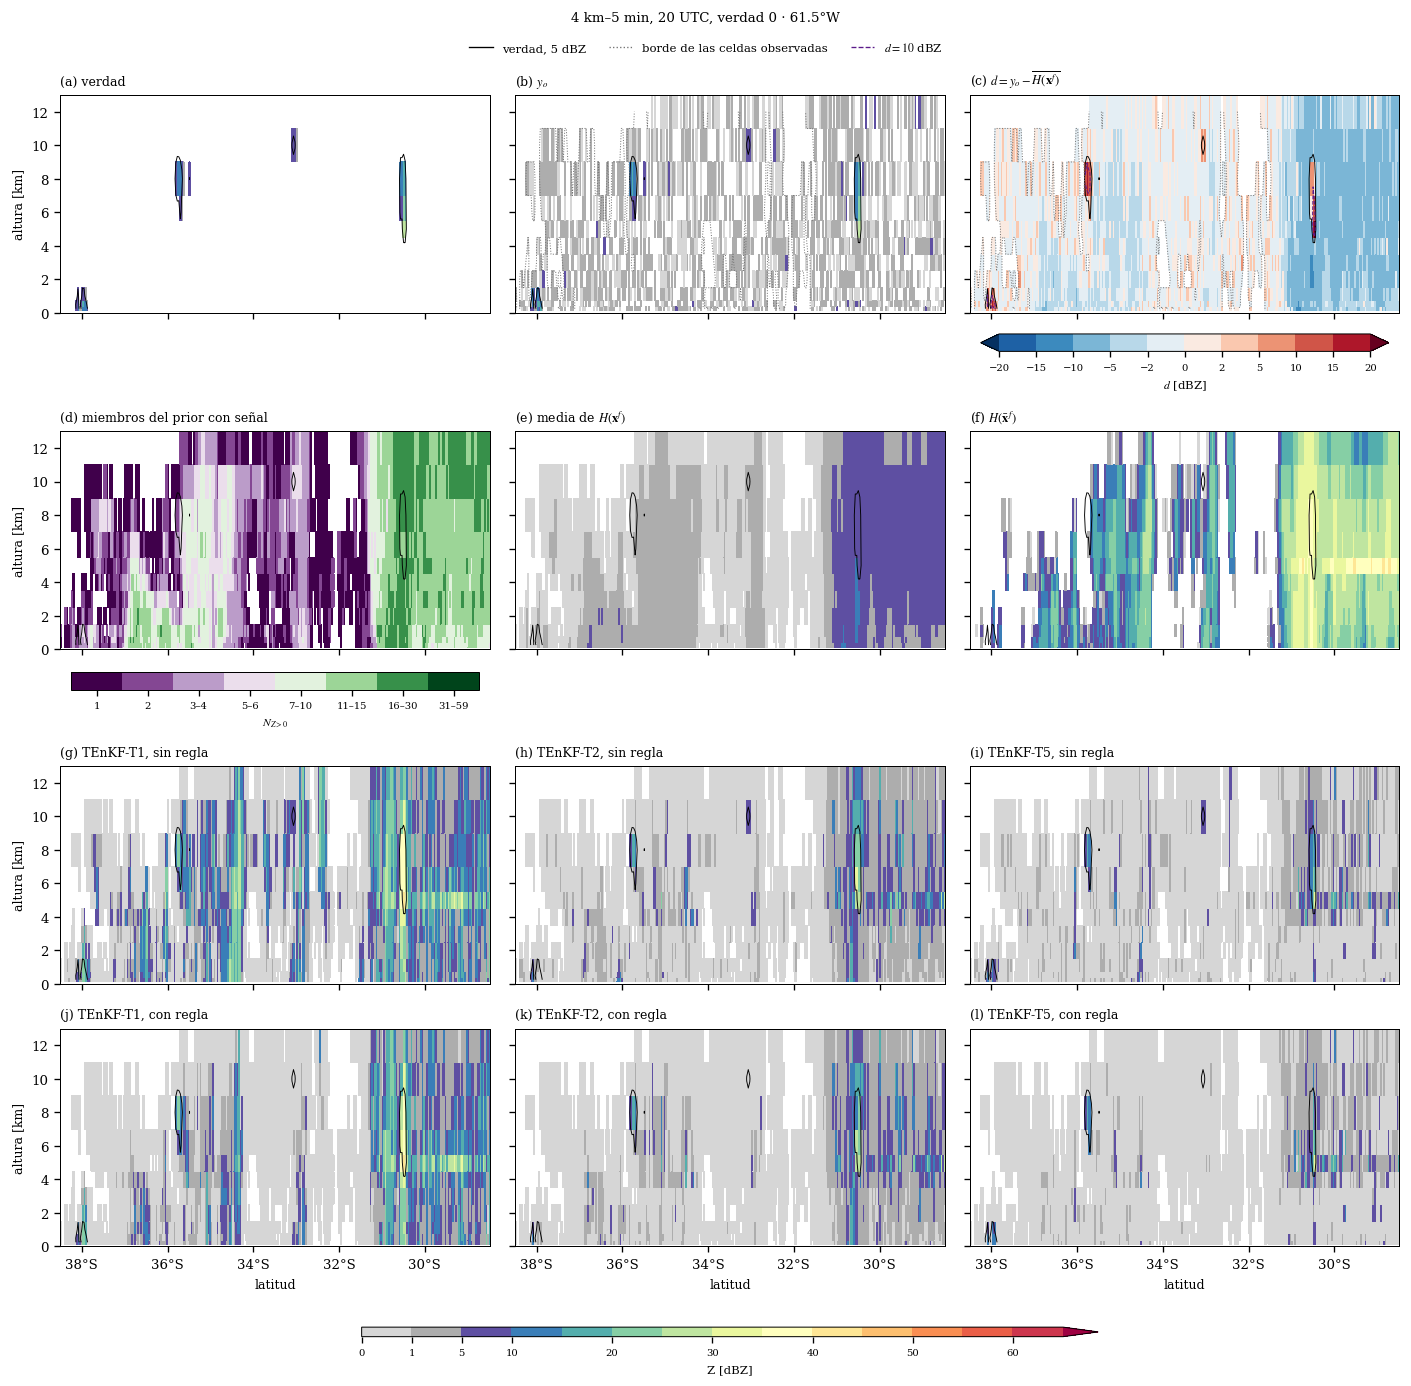

In [41]:
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter

# Escalas de las figuras 10b y 10c. Z: 0 dBZ exacto sin color; (0, 1) y [1, 5) en dos grises claros, más
# oscuros que la tierra de nb.setup_map (#f0efec) para que se distingan de "sin color" en los mapas;
# desde 5 dBZ, las clases y los colores de la figura 10. N_{Z>0}: PRGn en los tramos de la sección 0.5,
# 0 sin color. d: divergente y simétrica.
_c10 = plt.get_cmap(nb.DBZ_CMAP)
ZCMAP = ListedColormap(["0.84", "0.68"] + [_c10(MAP_NORM(0.5 * (a + b))) for a, b in zip(MAP_LEV[:-1], MAP_LEV[1:])])
ZCMAP.set_over(_c10(MAP_NORM(MAP_LEV[-1] + 1.0)))
ZLEV = np.concatenate([[0.0, 1.0], MAP_LEV])
ZNORM = BoundaryNorm(ZLEV, ZCMAP.N)
NCMAP = plt.get_cmap("PRGn")
NNORM = BoundaryNorm(NE_FINE, NCMAP.N)
DLEV = np.array([-20, -15, -10, -5, -2, 0, 2, 5, 10, 15, 20], float)
DCMAP = plt.get_cmap(nb.CMAP_DIV)
DNORM = BoundaryNorm(DLEV, DCMAP.N, extend="both")
SCALE = {"z": (ZCMAP, ZNORM, "max"), "n": (NCMAP, NNORM, "neither"), "d": (DCMAP, DNORM, "both")}
D_CONT = {"color": "#5b1a8a", "levels": (BAND[1],), "styles": ("--",)}
OBS_EDGE = "0.45"


def painted(F, kind):
    """Lo que se pinta: Z y N_{Z>0} solo sobre 0; d donde hay observación."""
    F = np.asarray(F, np.float64)
    return np.where(np.isfinite(F), F, np.nan) if kind == "d" else np.where(F > 0, F, np.nan)


def scale_colorbar(fig, m, ax, kind, label, cax=None, rotate=False, **kw):
    """Barra horizontal: bajo ax (constrained_layout) o en cax (mapas de cartopy)."""
    if cax is None:
        cb = fig.colorbar(m, ax=ax, location="bottom", extend=SCALE[kind][2], **kw)
    else:
        cb = fig.colorbar(m, cax=cax, orientation="horizontal", extend=SCALE[kind][2])
    if kind == "z":
        cb.set_ticks([0, 1, 5, 10, 20, 30, 40, 50, 60])
    elif kind == "n":
        cb.set_ticks(0.5 * (NE_FINE[:-1] + NE_FINE[1:]))
        cb.set_ticklabels(N_FINE)
        if rotate:
            plt.setp(cb.ax.get_xticklabels(), rotation=45, ha="right")
    else:
        cb.set_ticks(DLEV)
    cb.ax.tick_params(labelsize=6)
    cb.set_label(label, fontsize=7)
    return cb


def draw_fig10b(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    rule = lambda rg: L["none" if rg == NONE else "rule_short"]
    pan = [("truth", V["truth"], "z"), ("yo", L["yo"], "z"), ("d", L["d_obs"], "d"),
           ("nact", L["nact"], "n"), ("prior", L["prior_mean_h"], "z"), ("xbar", L["hx_xbar"], "z")]
    pan += [((rg, n), f"{lab('TEnKF', n)}, {rule(rg)}", "z") for rg in REGLAS for n in MAP_SCH]
    fig, axes = plt.subplots(4, 3, sharex=True, sharey=True, constrained_layout=True,
                             figsize=(nb.PAGE_W * 1.7, nb.PAGE_W * 1.6))
    mz = None
    for a, (ax, (key, title, kind)) in enumerate(zip(axes.flat, pan)):
        cmap, norm, _ = SCALE[kind]
        m = ax.pcolormesh(CUT_LE, CUT_ZE, painted(CUT[key], kind).T, cmap=cmap, norm=norm, shading="flat",
                          rasterized=True)
        ax.contour(CUT_LAT, CUT_Z, CUT["truth"].T, levels=[ECHO_DBZ], colors="k", linewidths=0.55)
        if key in ("yo", "d"):
            ax.contour(CUT_LAT, CUT_Z, CUT["obs"].T, levels=[0.5], colors=OBS_EDGE, linewidths=0.6, linestyles=":")
        if key == "d":
            ax.contour(CUT_LAT, CUT_Z, np.ma.masked_invalid(CUT["d"]).T, levels=list(D_CONT["levels"]),
                       colors=D_CONT["color"], linewidths=0.6, linestyles=list(D_CONT["styles"]))
            scale_colorbar(fig, m, ax, "d", L["d_dbz"], shrink=0.95, aspect=22)
        elif key == "nact":
            scale_colorbar(fig, m, ax, "n", V["n_echo_sym"], shrink=0.95, aspect=22)
        else:
            mz = m
        ax.set_title(f"({'abcdefghijkl'[a]}) {title}", loc="left", fontsize=7.5)
        ax.set_facecolor("white")
        ax.grid(False)
    for ax in axes[:, 0]:
        ax.set_ylabel(L["height"], fontsize=7.5)
    for ax in axes[-1, :]:
        ax.set_xlabel(L["lat"], fontsize=7.5)
    axes[0, 0].set_xlim(CUT_LE.min(), CUT_LE.max())
    axes[0, 0].set_ylim(0.0, CUT_ZE[-1])
    axes[0, 0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(v):g}°S"))
    scale_colorbar(fig, mz, axes[-1, :], "z", "Z [dBZ]", shrink=0.55, aspect=40)
    h = [Line2D([], [], color="k", lw=0.8, label=L["truth5"]),
         Line2D([], [], color=OBS_EDGE, lw=0.8, ls=":", label=L["obs_edge"]),
         Line2D([], [], color=D_CONT["color"], lw=0.8, ls="--", label=rf"$d = {BAND[1]:g}$ dBZ")]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False, fontsize=7)
    fig.suptitle(f"{DSL[_ds]}, {_hh} UTC, {V['truth']} {_tm} · {abs(CUT_LINE['lon']):g}°W", fontsize=8, y=1.04)
    return fig


nb.save(draw_fig10b, "N6_fig10b_corte_vertical_eco_falso", show=SHOW); plt.show()

/home/jorge.gacitua/datosdemerzel/miniconda3/envs/intermediate_exp/lib/python3.8/site-packages/cartopy/mpl/geoaxes.py:1597: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  X, Y, C, shading = self._pcolorargs('pcolormesh', *args,


figures/es/N6_fig10c_mapa_diagnostico_eco_falso.png  figures/en/N6_fig10c_diagnostic_map_false_echo.png


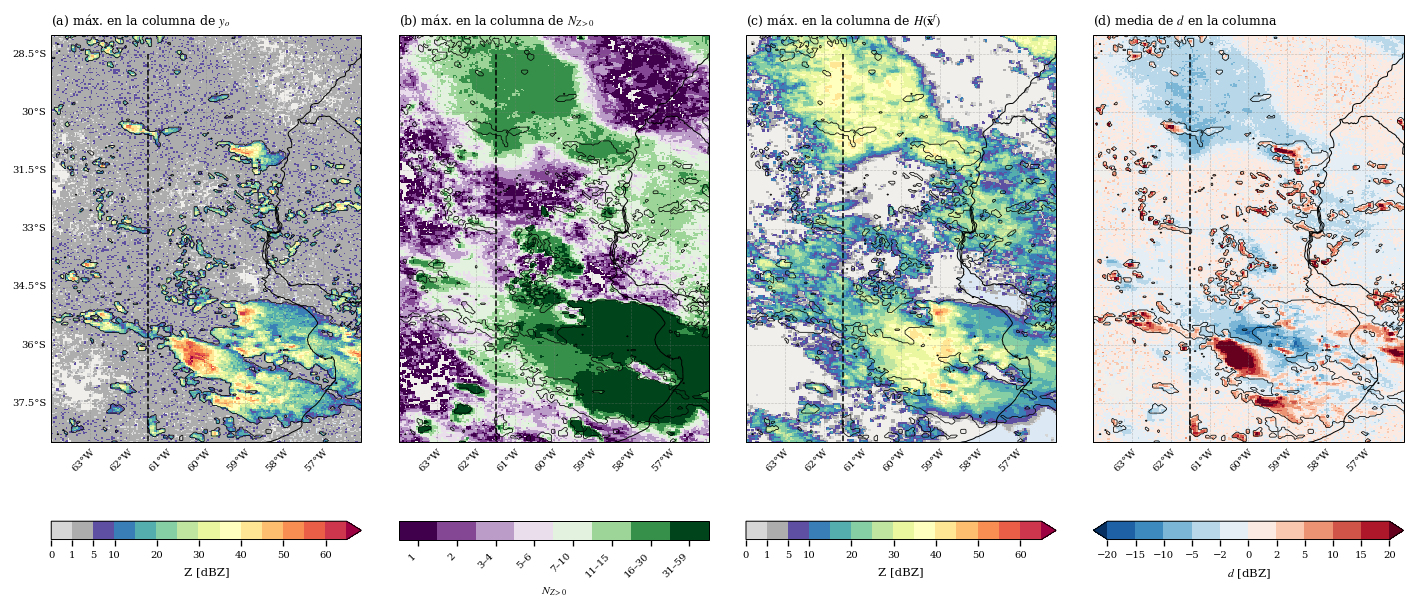

In [42]:
def draw_fig10c(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    pan = (("yo", L["colmax_yo"], "z", "Z [dBZ]"), ("nact", L["colmax_nact"], "n", V["n_echo_sym"]),
           ("xbar", L["colmax_xbar"], "z", "Z [dBZ]"), ("d", L["colmean_d"], "d", L["d_dbz"]))
    # Sin constrained_layout: con cartopy no se aplica y las barras tapan las longitudes. Cada barra va en
    # un eje propio bajo su panel, debajo de las etiquetas.
    fig, axes = plt.subplots(1, 4, figsize=(nb.PAGE_W * 1.75, nb.PAGE_W * 0.78),
                             subplot_kw=dict(projection=ccrs.PlateCarree()))
    fig.subplots_adjust(left=0.05, right=0.99, bottom=0.26, top=0.93, wspace=0.12)
    lats, lons = MAP_GEO["lats"], MAP_GEO["lons"]
    for a, (ax, (key, title, kind, cbl)) in enumerate(zip(axes, pan)):
        nb.setup_map(ax, extent=MAP_EXTENT, left_labels=(a == 0), bottom_labels=True)
        cmap, norm, _ = SCALE[kind]
        m = nb.map_field(ax, lats, lons, painted(MAPB[key], kind), cmap=cmap, norm=norm,
                         transform=ccrs.PlateCarree(), zorder=1)
        ax.contour(lons, lats, MAP_ECHO.T, levels=[0.5], colors="k", linewidths=0.45,
                   transform=ccrs.PlateCarree(), zorder=3)
        draw_cut_line(ax)
        ax.set_title(f"({'abcd'[a]}) {title}", fontsize=7.5, loc="left")
        scale_colorbar(fig, m, None, kind, cbl, cax=ax.inset_axes([0.0, -0.24, 1.0, 0.045]), rotate=True)
    return fig


nb.save(draw_fig10c, "N6_fig10c_mapa_diagnostico_eco_falso", show=SHOW); plt.show()

In [43]:
import warnings
from scipy.stats import spearmanr

# ── Figura 10d y su tabla: la media de H del posterior de TEnKF-T1 contra el máximo de H del prior (figura y tabla)
#    y contra H(x̄_f) (solo la tabla) ──
FC_SEL = CASE["valid"] & (CASE["truth"] < ECHO_DBZ)          # alcanzadas de la línea base, verdad < 5 dBZ
FC_X = {"xbar": CASE["hx_xbar"].astype(np.float64), "max": CASE["hxf_max"].astype(np.float64)}
FC_Y = {rg: np.nan_to_num(CASE[f"hxa_{'sin' if rg == NONE else 'con'}_T1"]).astype(np.float64) for rg in REGLAS}
FC_XNAME = {"xbar": "H(x̄_f)", "max": "máx H"}
FC_EDGES = np.arange(0.0, 5.0 * np.ceil(max(v[FC_SEL].max() for v in (*FC_X.values(), *FC_Y.values())) / 5.0) + 1e-9, 1.0)
FC_H = {rg: np.histogram2d(FC_X["max"][FC_SEL], FC_Y[rg][FC_SEL], bins=[FC_EDGES, FC_EDGES])[0] for rg in REGLAS}
assert all(h.sum() == FC_SEL.sum() for h in FC_H.values()), "celdas fuera de los bordes del histograma"


def rho(x, y):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return spearmanr(x, y).correlation if x.size > 2 else np.nan


FC_RHO = {(rg, xk): rho(FC_X[xk][FC_SEL], FC_Y[rg][FC_SEL]) for rg in REGLAS for xk in FC_X}


def fc_row(m):
    r = {"celdas": int(m.sum())}
    for rg in REGLAS:
        r[f"mediana T1 {'sin' if rg == NONE else 'con'}"] = np.median(FC_Y[rg][m])
    for xk in FC_X:
        r[f"mediana {FC_XNAME[xk]}"] = np.median(FC_X[xk][m])
    for rg in REGLAS:
        r[f"P(T1 {'sin' if rg == NONE else 'con'} ≥ 5)"] = (FC_Y[rg][m] >= ECHO_DBZ).mean()
    for rg in REGLAS:
        for xk in FC_X:
            r[f"ρ T1 {'sin' if rg == NONE else 'con'}, {FC_XNAME[xk]}"] = rho(FC_X[xk][m], FC_Y[rg][m])
    # en las celdas con eco falso (verdad < 5, ya en FC_SEL, y media de H(x_a) ≥ 5): cuánto queda bajo el miembro máximo
    for rg in REGLAS:
        s = "sin" if rg == NONE else "con"
        fe = m & (FC_Y[rg] >= ECHO_DBZ)
        r[f"eco falso T1 {s}"] = int(fe.sum())
        r[f"mediana máx H − T1 {s}, eco falso"] = np.median(FC_X["max"][fe] - FC_Y[rg][fe]) if fe.any() else np.nan
    n_sin, n_con = r["eco falso T1 sin"], r["eco falso T1 con"]
    r["reducción del eco falso por la regla"] = 1 - n_con / n_sin if n_sin else np.nan
    return r


# Por tramo de N_{Z>0}: los de la tabla de H(x̄_f), y además 0 (las celdas sin señal también están en la figura).
_na = CASE["nact"]
_rows = {"0": fc_row(FC_SEL & (_na == 0))}
_nbin = nbin_fine(_na)
for b, lbl in enumerate(N_FINE):
    _rows[lbl] = fc_row(FC_SEL & (_na >= 1) & (_nbin == b))
_rows["todas"] = fc_row(FC_SEL)
T11_POST = pd.DataFrame(_rows).T.rename_axis("N_Z>0")
assert T11_POST.celdas.iloc[:-1].sum() == T11_POST.celdas.iloc[-1]
print(f"Media de H del posterior de TEnKF-T1 contra H(x̄_f) y el máximo de H de los 59 miembros; en las celdas con eco "
      f"falso, máximo de H menos media de H(x_a) · {DSL[_ds]}, {_hh} UTC, "
      f"verdad {_tm} · alcanzadas de la línea base con verdad < {ECHO_DBZ:g} dBZ (medianas en dBZ; ρ de Spearman)")
print(T11_POST.to_string(float_format=lambda v: f"{v:.2f}", na_rep="—",
                         formatters={c: "{:,.0f}".format for c in T11_POST.columns if c.startswith(("celdas", "eco falso"))}))
T11_POST.reset_index().to_csv(TAB / "N6_tab_posterior_T1.csv", index=False)

Media de H del posterior de TEnKF-T1 contra H(x̄_f) y el máximo de H de los 59 miembros; en las celdas con eco falso, máximo de H menos media de H(x_a) · 4 km–5 min, 20 UTC, verdad 0 · alcanzadas de la línea base con verdad < 5 dBZ (medianas en dBZ; ρ de Spearman)
         celdas  mediana T1 sin  mediana T1 con  mediana H(x̄_f)  mediana máx H  P(T1 sin ≥ 5)  P(T1 con ≥ 5)  ρ T1 sin, H(x̄_f)  ρ T1 sin, máx H  ρ T1 con, H(x̄_f)  ρ T1 con, máx H eco falso T1 sin  mediana máx H − T1 sin, eco falso eco falso T1 con  mediana máx H − T1 con, eco falso  reducción del eco falso por la regla
N_Z>0                                                                                                                                                                                                                                                                                                                              
0       455,504            0.00            0.00             0.00           0.00        

figures/es/N6_fig10d_posterior_contra_prior.png  figures/en/N6_fig10d_posterior_vs_prior.png


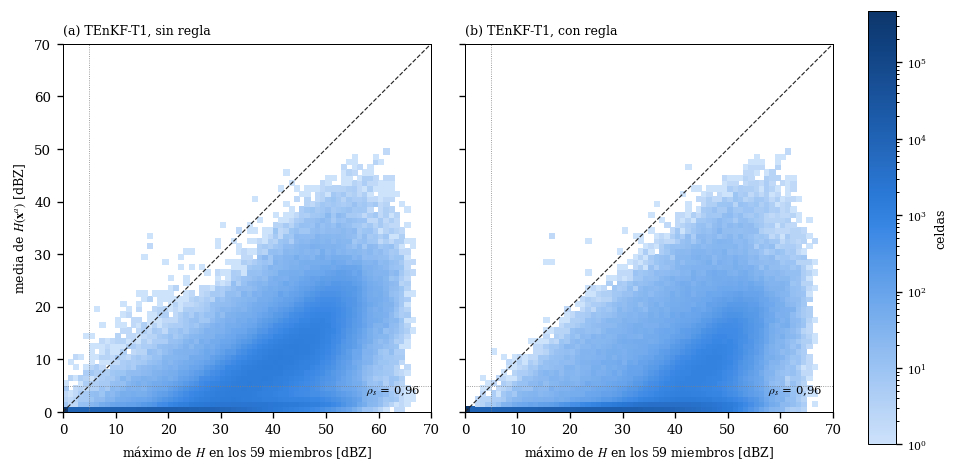

In [44]:
from matplotlib.colors import LogNorm


def draw_fig10d(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    fig, axes = plt.subplots(1, len(REGLAS), sharex=True, sharey=True, constrained_layout=True,
                             figsize=(nb.PAGE_W * 1.15, nb.PAGE_W * 0.62))
    norm = LogNorm(vmin=1, vmax=max(h.max() for h in FC_H.values()))
    lim = (FC_EDGES[0], FC_EDGES[-1])
    for c, rg in enumerate(REGLAS):
        ax = axes[c]
        H = FC_H[rg]
        im = ax.pcolormesh(FC_EDGES, FC_EDGES, np.where(H > 0, H, np.nan).T, cmap=nb.CMAP_SEQ, norm=norm,
                           rasterized=True)
        ax.plot(lim, lim, color="0.15", lw=0.7, ls="--")
        ax.axhline(ECHO_DBZ, color="0.5", lw=0.5, ls=":")
        ax.axvline(ECHO_DBZ, color="0.5", lw=0.5, ls=":")
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.set_aspect("equal")
        ax.grid(False)
        ax.set_title(f"({'ab'[c]}) TEnKF-T1, {L['none' if rg == NONE else 'rule_short']}", loc="left", fontsize=7.5)
        ax.text(0.97, 0.04, rf"$\rho_s$ = {nb.fmt(FC_RHO[(rg, 'max')], lang, '.2f')}", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=7)
        ax.set_xlabel(L["hx_max"] + " [dBZ]", fontsize=7.5)
    axes[0].set_ylabel(L["post_t1"], fontsize=7.5)
    cb = fig.colorbar(im, ax=axes, shrink=0.85, aspect=25)
    cb.set_label(L["cells"], fontsize=7.5)
    cb.ax.tick_params(labelsize=6.5)
    return fig


nb.save(draw_fig10d, "N6_fig10d_posterior_contra_prior", show=SHOW); plt.show()

In [45]:
# ── Las celdas sin señal en el prior (N_Z>0 = 0) que el análisis alcanza: eco falso sin observación propia ──
Q0 = 1e-7                 # kg/kg (1e-4 g/kg): umbral de "sin hidrometeoros" en q_g, q_r y q_s
D_BINS = (1.0, 2.0, 3.0)  # distancia a la observación más cercana, en unidades de L
_ds, _hh, _tm = MAP_CASE
_L = float(nb.run_config(tag_of(_ds, _hh, NONE))["sweep"]["loc_x"])
_pos = nb.load_subset(nb.subset_path(_hh, _ds), keys=("pos_km",))["pos_km"].astype(np.float32).astype(np.float64)
_n0 = CASE["valid"] & (CASE["nact"] == 0)
_clear = CASE["truth"] < ECHO_DBZ
_P = _pos[CASE["ix"], CASE["iy"], CASE["iz"]]
_dist = np.full(_n0.shape, np.nan)
_dist[_n0] = cKDTree(_P / _L).query(_pos[_n0] / _L, k=1)[0]       # distancia normalizada, la de within()
_raw, _qmax = CASE["hxf_max_raw"].astype(np.float64), CASE["q_max"].astype(np.float64)
assert np.isfinite(_dist[_n0]).all() and (_dist[_n0] > 0).all() and (_dist[_n0] ** 2 <= MAXD2 * (1 + 1e-9)).all(), \
    "una celda alcanzada sin señal está observada o fuera del alcance"


def n0_row(m, rg):
    """Las cifras de un conjunto de celdas; NaN si está vacío (el eco falso sin señal puede no existir)."""
    ha, d, r, q = FC_Y[rg][m], _dist[m], _raw[m], _qmax[m]
    pc = lambda a, p: np.percentile(a, p) if a.size else np.nan
    fr = lambda b: b.mean() if b.size else np.nan
    row = {"celdas": int(m.sum()), "media H(x_a) máx": ha.max() if ha.size else np.nan,
           "máx H sin censurar: p10": pc(r, 10), "mediana": pc(r, 50), "p90": pc(r, 90),
           f"P(59 miembros con q < {Q0 * 1e3:g} g/kg)": fr(q < Q0), "P(59 miembros con q = 0)": fr(q <= 0),
           "distancia [L]: p10": pc(d, 10), "mediana ": pc(d, 50), "p90 ": pc(d, 90)}
    row.update({f"P(d ≤ {b:g} L)": fr(d <= b) for b in D_BINS})
    return row


T11_N0, _cnt = {}, {}
for rg in REGLAS:
    s = "sin" if rg == NONE else "con"
    ha = FC_Y[rg]
    fe_total = int(np.count_nonzero(_clear & (np.nan_to_num(CASE[f"hxa_{s}_T1"]) >= ECHO_DBZ)))
    assert fe_total == MAP_N[(rg, 1)], "el eco falso no es el de la sección 0.4"
    on = _n0 & (ha >= ECHO_DBZ)
    _cnt[f"T1 {s}"] = {"N_Z>0 = 0, alcanzadas": int(_n0.sum()), "… con media de H(x_a) > 0": int((_n0 & (ha > 0)).sum()),
                       "… con media de H(x_a) ≥ 1": int((_n0 & (ha >= 1)).sum()),
                       "… con media de H(x_a) ≥ 5": int(on.sum()),
                       "… y verdad < 5 (eco falso)": int((on & _clear).sum()), "eco falso del caso, todo el dominio": fe_total,
                       "parte del eco falso con N_Z>0 = 0 (%)": 100 * (on & _clear).sum() / fe_total}
    T11_N0[(f"T1 {s}", "eco falso, N_Z>0 = 0")] = n0_row(on & _clear, rg)
    T11_N0[(f"T1 {s}", "N_Z>0 = 0, 0 < media < 5")] = n0_row(_n0 & (ha > 0) & (ha < ECHO_DBZ), rg)
    T11_N0[(f"T1 {s}", "N_Z>0 = 0, media = 0")] = n0_row(_n0 & (ha <= 0), rg)
print(f"{DSL[_ds]}, {_hh} UTC, verdad {_tm}: celdas alcanzadas de la línea base sin miembros con señal en el prior")
_cnt = pd.DataFrame(_cnt).T
print(_cnt.to_string(formatters={c: ("{:.4f}".format if "%" in c else "{:,.0f}".format) for c in _cnt.columns}))
T11_N0 = pd.DataFrame(T11_N0).T
print(f"\nEn esas celdas (Z en dBZ; distancia a la celda observada más cercana en unidades de L = {_L:g} km; "
      f"el alcance llega a {np.sqrt(MAXD2):.2f} L)")
print(T11_N0.to_string(float_format=lambda v: f"{v:.2f}", formatters={"celdas": "{:,.0f}".format}, na_rep="—"))
T11_N0.rename_axis(["esquema", "celdas_de"]).reset_index().to_csv(TAB / "N6_tab_eco_falso_sin_senal.csv", index=False)
del _pos, _dist

4 km–5 min, 20 UTC, verdad 0: celdas alcanzadas de la línea base sin miembros con señal en el prior
       N_Z>0 = 0, alcanzadas … con media de H(x_a) > 0 … con media de H(x_a) ≥ 1 … con media de H(x_a) ≥ 5 … y verdad < 5 (eco falso) eco falso del caso, todo el dominio parte del eco falso con N_Z>0 = 0 (%)
T1 sin               457,800                       343                        24                         1                          1                             304,022                                0.0003
T1 con               457,800                       261                         8                         0                          0                             157,698                                0.0000

En esas celdas (Z en dBZ; distancia a la celda observada más cercana en unidades de L = 2 km; el alcance llega a 3.65 L)
                                 celdas  media H(x_a) máx  máx H sin censurar: p10  mediana   p90  P(59 miembros con q < 0.0001 g/kg)  P(59 miembros con q

In [46]:
# ── Eco falso por tramo de N_Z>0: 3 datasets × 4 horas × 12 verdades (sección 0.7) ──
FE_ORDER = [lab(m, n) for m, n in FE_SCH]
TRAMO_ORDER = list(NACT_T) + ["todas"]


def hist_median(h):
    """Mediana de un histograma de bordes GAP_EDGES, interpolada dentro del bin."""
    n = h.sum()
    if n == 0:
        return np.nan
    c = np.cumsum(h)
    i = int(np.searchsorted(c, n / 2.0))
    return GAP_EDGES[i] + (n / 2.0 - (c[i - 1] if i else 0)) / h[i] * (GAP_EDGES[i + 1] - GAP_EDGES[i])


def pool_fe(df, H, keys):
    """Sumas y el histograma agregado por keys; df y H en el mismo orden de filas."""
    g = df.groupby(keys, sort=True)
    S = g[["n_clear", "n_fe", "s_gap"]].sum()
    Hg = np.zeros((g.ngroups, H.shape[1]))
    np.add.at(Hg, g.ngroup().to_numpy(), H)
    S["fe"] = 100 * S.n_fe / S.n_clear
    S["gap_med"] = [hist_median(h) for h in Hg]
    S["gap_mean"] = S.s_gap / S.n_fe
    w = S[["n_clear", "fe", "gap_med", "gap_mean", "n_fe"]].unstack("regla")
    out = pd.DataFrame({"celdas verdad < 5": w[("n_clear", NONE)],
                        "eco falso sin (%)": w[("fe", NONE)], "eco falso con (%)": w[("fe", RULE)],
                        # Σ con / Σ sin; indefinida (NaN, ni 0 ni 1) donde no hay eco falso sin regla
                        "reducción": (1 - w[("n_fe", RULE)] / w[("n_fe", NONE)]).where(w[("n_fe", NONE)] > 0),
                        "brecha mediana sin": w[("gap_med", NONE)], "brecha mediana con": w[("gap_med", RULE)],
                        "brecha media sin": w[("gap_mean", NONE)], "brecha media con": w[("gap_mean", RULE)]})
    assert (w[("n_clear", NONE)] == w[("n_clear", RULE)]).all(), "otras celdas con y sin regla"
    return out


_ft = pd.concat([FT6, FT6.assign(tramo="todas")], ignore_index=True)
_ft["esquema"] = [lab(m, n) for m, n in zip(_ft.method, _ft.ntemp)]
_fh = np.concatenate([FH6, FH6])
_k = ["dataset", "esquema", "tramo"]
T11_FE = pool_fe(_ft, _fh, _k + ["regla"])
_pt = pool_fe(_ft, _fh, _k + ["tm", "regla"])          # por verdad, las cuatro horas juntas
_vals = [c for c in T11_FE.columns if c != "celdas verdad < 5"]
# La desviación entre verdades excluye los NaN: en la reducción, las verdades sin eco falso sin regla en el tramo.
T11_FE = T11_FE.join(_pt[_vals].groupby(level=_k).std(ddof=1).add_suffix(" sd"))
T11_FE["verdades (reducción)"] = _pt["reducción"].groupby(level=_k).count()
T11_FE = T11_FE.reindex(pd.MultiIndex.from_tuples([(d, e, t) for d in DATASETS for e in FE_ORDER for t in TRAMO_ORDER],
                                                  names=_k))
T11_FE.reset_index().to_csv(TAB / "N6_tab_eco_falso_tramos.csv", index=False)
for ds in DATASETS:
    t = T11_FE.xs(ds, level="dataset")
    show = pd.DataFrame({"celdas verdad < 5": t["celdas verdad < 5"].map("{:,.0f}".format)}, index=t.index)
    for c, nd in (("eco falso sin (%)", 2), ("eco falso con (%)", 2), ("reducción", 2),
                  ("brecha mediana sin", 1), ("brecha mediana con", 1)):
        show[c] = [pm(a, b, nd) for a, b in zip(t[c], t[f"{c} sd"])]
        if c == "reducción":
            show["verdades"] = t["verdades (reducción)"].astype(int)
    print(f"\n══════ {DSL[ds]} · eco falso por tramo de N_Z>0, alcanzadas válidas con verdad < 5 dBZ, 12 verdades × 4 horas "
          f"(± desviación entre verdades) ══════")
    print("eco falso: % de las celdas con verdad < 5; reducción: 1 − Σ con / Σ sin, y su desviación sobre las 'verdades' "
          "con eco falso sin regla en el tramo; brecha: máximo de H del prior − media de H(x_a) en el eco falso [dBZ]")
    print(show.to_string())

# ── El eco falso según el prior: creado, heredado y eliminado (sección 0.7) ──
PRIOR_SUMS = ["n_clear", "n_fe_prior", "n_created", "n_inherited", "n_removed", "s_dz_inh"]


def prior_split(df, keys):
    S = df.groupby(keys + ["regla"], sort=True)[PRIOR_SUMS].sum().unstack("regla")
    sin, con = (lambda c: S[(c, NONE)]), (lambda c: S[(c, RULE)])
    assert (sin("n_clear") == con("n_clear")).all() and (sin("n_fe_prior") == con("n_fe_prior")).all()
    pct = lambda c, f: 100 * f(c) / f("n_clear")
    red = lambda c: (1 - con(c) / sin(c)).where(sin(c) > 0)           # indefinida sin eco sin regla: NaN
    return pd.DataFrame({
        "prior (%)": pct("n_fe_prior", sin),
        "creado sin (%)": pct("n_created", sin), "creado con (%)": pct("n_created", con),
        "heredado sin (%)": pct("n_inherited", sin), "heredado con (%)": pct("n_inherited", con),
        "eliminado sin (%)": pct("n_removed", sin), "eliminado con (%)": pct("n_removed", con),
        "ΔZ heredado sin": (sin("s_dz_inh") / sin("n_inherited")).where(sin("n_inherited") > 0),
        "ΔZ heredado con": (con("s_dz_inh") / con("n_inherited")).where(con("n_inherited") > 0),
        "reducción creado": red("n_created"), "reducción heredado": red("n_inherited")})


T11_FEP = prior_split(_ft, _k)
_pp = prior_split(_ft, _k + ["tm"])
T11_FEP = T11_FEP.join(_pp.groupby(level=_k).std(ddof=1).add_suffix(" sd"))
for c in ("reducción creado", "reducción heredado"):
    T11_FEP[f"verdades ({c})"] = _pp[c].groupby(level=_k).count()
T11_FEP = T11_FEP.reindex(T11_FE.index)
T11_FEP.reset_index().to_csv(TAB / "N6_tab_eco_falso_prior.csv", index=False)
for ds in DATASETS:
    t = T11_FEP.xs((ds, "TEnKF-T1"), level=("dataset", "esquema"))
    show = pd.DataFrame(index=t.index)
    for c in ("prior (%)", "creado sin (%)", "creado con (%)", "heredado sin (%)", "heredado con (%)",
              "eliminado sin (%)", "eliminado con (%)", "ΔZ heredado sin", "ΔZ heredado con"):
        show[c] = [pm(a, b, 2) for a, b in zip(t[c], t[f"{c} sd"])]
    for c in ("reducción creado", "reducción heredado"):
        show[c] = [pm(a, b, 2) for a, b in zip(t[c], t[f"{c} sd"])]
        show[f"verd. {c.split()[1]}"] = t[f"verdades ({c})"].astype(int)
    print(f"\n══════ {DSL[ds]} · TEnKF-T1 · eco falso según el prior, % de las alcanzadas válidas con verdad < 5 dBZ, "
          f"12 verdades × 4 horas (± desviación entre verdades) ══════")
    print("creado: prior < 5, posterior ≥ 5; heredado: los dos ≥ 5; eliminado: prior ≥ 5, posterior < 5; ΔZ: cambio "
          "medio de la media de H en las heredadas [dBZ]; reducción: 1 − Σ con / Σ sin")
    print(show.to_string())

# La fila "todas" de los cuatro esquemas, una tabla por dataset
for ds in DATASETS:
    t = T11_FEP.xs((ds, "todas"), level=("dataset", "tramo")).reindex(FE_ORDER)
    show = pd.DataFrame(index=t.index)
    for c in ("prior (%)", "creado sin (%)", "creado con (%)", "heredado sin (%)", "heredado con (%)",
              "eliminado sin (%)", "eliminado con (%)", "ΔZ heredado sin", "ΔZ heredado con"):
        show[c] = [pm(a, b, 2) for a, b in zip(t[c], t[f"{c} sd"])]
    for c in ("reducción creado", "reducción heredado"):
        show[c] = [pm(a, b, 2) for a, b in zip(t[c], t[f"{c} sd"])]
        show[f"verd. {c.split()[1]}"] = t[f"verdades ({c})"].astype(int)
    print(f"\n══════ {DSL[ds]} · todos los tramos · eco falso según el prior, % de las alcanzadas válidas con verdad < 5 dBZ, "
          f"12 verdades × 4 horas (± desviación entre verdades) ══════")
    print(show.rename_axis("esquema").to_string())


══════ 4 km–5 min · eco falso por tramo de N_Z>0, alcanzadas válidas con verdad < 5 dBZ, 12 verdades × 4 horas (± desviación entre verdades) ══════
eco falso: % de las celdas con verdad < 5; reducción: 1 − Σ con / Σ sin, y su desviación sobre las 'verdades' con eco falso sin regla en el tramo; brecha: máximo de H del prior − media de H(x_a) en el eco falso [dBZ]
               celdas verdad < 5 eco falso sin (%) eco falso con (%)     reducción  verdades brecha mediana sin brecha mediana con
esquema  tramo                                                                                                                    
TEnKF-T1 0            22,608,099       0.00 ± 0.00       0.00 ± 0.00   0.84 ± 0.18        12         -6.1 ± 0.5         -7.2 ± 1.2
         1             8,413,363      10.59 ± 0.14       1.16 ± 0.20   0.89 ± 0.02        12         27.1 ± 0.1         19.2 ± 1.5
         2             5,562,475      21.70 ± 0.25       3.70 ± 0.40   0.83 ± 0.02        12         28.0 ± 0.

## 12 · Observación única: un miembro arrastra al ensamble

Con la sección 0.5, por tramo de la innovación propia y de $N_{Z>0}$ (los de la sección 0.2), los tres datasets juntos y cada uno:

- `s1` y `Neff`: cuánto de la actualización decide el miembro más fuerte;
- `ΔZ̄`: cuánto sube la media de $H$ en la celda, $\overline{H(\mathbf{x}^a)} - \overline{H(\mathbf{x}^f)}$, comparado con $|d|$;
- `enc/obs`: el número medio de miembros que se **encienden** por observación (`snon/n`). Un miembro se enciende si tiene 0 dBZ en el prior y `ON_DBZ` (5 dBZ) o más en el posterior. `enc|enc`: cuántos se encienden en las observaciones que encienden alguno;
- $\mathrm{SS}_\mathrm{RMSE}$ y $\mathrm{SS}_\mathrm{CRPS}$ de $Z$ en la celda.

La figura es el mapa de calor de $d$ contra $N_{Z>0}$ en tramos finos: por esquema, `enc/obs`, $\mathrm{SS}_\mathrm{RMSE}$ y $\mathrm{SS}_\mathrm{CRPS}$ (gris: menos de `N_MIN_HEAT` observaciones). La de conteos da cuántas observaciones hay en cada casilla, sin normalizar. Las líneas verticales encierran $0 \le d \le 10$.


In [47]:
N_MIN_HEAT = 200
SO_SUMS = [c for c in SO6.columns if c not in ("dataset", "hour", "tm", "dbin", "nbin", "tramo", "nact")]
T12_SCH = ("T1", "T2", "T5")


def single_stats(s):
    with np.errstate(divide="ignore", invalid="ignore"):
        o = {"obs": s.n, "|d|": s.s_absd / s.n, "s1": s.s_s1 / s.n, "Neff": s.s_neff / s.n}
        for k in T12_SCH:
            o[f"ΔZ̄ {k}"] = s[f"sdz_{k}"] / s.n
        for k in T12_SCH:
            o[f"enc/obs {k}"] = s[f"snon_{k}"] / s.n
        for k in T12_SCH:
            o[f"enc|enc {k}"] = s[f"snon_{k}"] / s[f"nenc_{k}"]
        for k in T12_SCH + ("AOEI",):
            o[f"SS_RMSE {k}"] = 1 - np.sqrt(s[f"se2_a_{k}"] / s.se2_f)
        for k in T12_SCH + ("AOEI",):
            o[f"SS_CRPS {k}"] = 1 - s[f"scrps_a_{k}"] / s.scrps_f
    return pd.DataFrame(o)


T12 = {}
for name, df in [("ABC", SO6)] + [(ds, SO6[SO6.dataset == ds]) for ds in DATASETS]:
    t = single_stats(df.groupby(["tramo", "nact"])[SO_SUMS].sum())
    t["obs"] = 100 * t.obs / t.obs.sum()
    T12[name] = t.reindex([(tr, a) for tr in TRAMOS for a in NACT_LABELS[1:]]).dropna(how="all")
    print(f"\n══════ {'los tres datasets' if name == 'ABC' else DSL[name]} · observación única, 12 verdades × 4 horas "
          f"(obs en %) ══════")
    print(T12[name].to_string(float_format=lambda v: f"{v:.2f}"))
pd.concat(T12, names=["dataset"]).reset_index().to_csv(TAB / "N6_tab_observacion_unica.csv", index=False)

# Mapas de calor: d × N_{Z>0} en tramos finos
HEAT = {}
for name, df in [("ABC", SO6)] + [(ds, SO6[SO6.dataset == ds]) for ds in DATASETS]:
    s = df.groupby(["nbin", "dbin"])[SO_SUMS].sum()
    st = single_stats(s)
    grid = lambda col: st[col].unstack("dbin").reindex(index=list(N_FINE), columns=list(D_FINE))
    cnt = s.n.unstack("dbin").reindex(index=list(N_FINE), columns=list(D_FINE))
    few = cnt.fillna(0) < N_MIN_HEAT
    HEAT[name] = {"count": cnt.to_numpy(),
                  **{f"{q} {k}": grid(f"{q} {k}").mask(few).to_numpy() for q in ("enc/obs", "SS_RMSE", "SS_CRPS")
                     for k in T12_SCH}}



══════ los tres datasets · observación única, 12 verdades × 4 horas (obs en %) ══════
                obs   |d|   s1  Neff  ΔZ̄ T1  ΔZ̄ T2  ΔZ̄ T5  enc/obs T1  enc/obs T2  enc/obs T5  enc|enc T1  enc|enc T2  enc|enc T5  SS_RMSE T1  SS_RMSE T2  SS_RMSE T5  SS_RMSE AOEI  SS_CRPS T1  SS_CRPS T2  SS_CRPS T5  SS_CRPS AOEI
tramo   nact                                                                                                                                                                                                                            
d < 0   1–2   18.50  0.37 0.90  1.24    0.04   -0.07   -0.12        0.67        0.20        0.01       51.06       47.90       32.55       -1.68       -0.19        0.25         -1.68      -11.51       -2.97       -0.51        -11.51
        3–6   18.41  1.22 0.53  2.85    0.37   -0.49   -0.69        4.72        1.68        0.58       47.86       45.11       47.26       -1.55       -0.11        0.17         -1.55      -10.95       -2.72       -

figures/es/N6_fig11_observacion_unica.png  figures/en/N6_fig11_single_obs.png


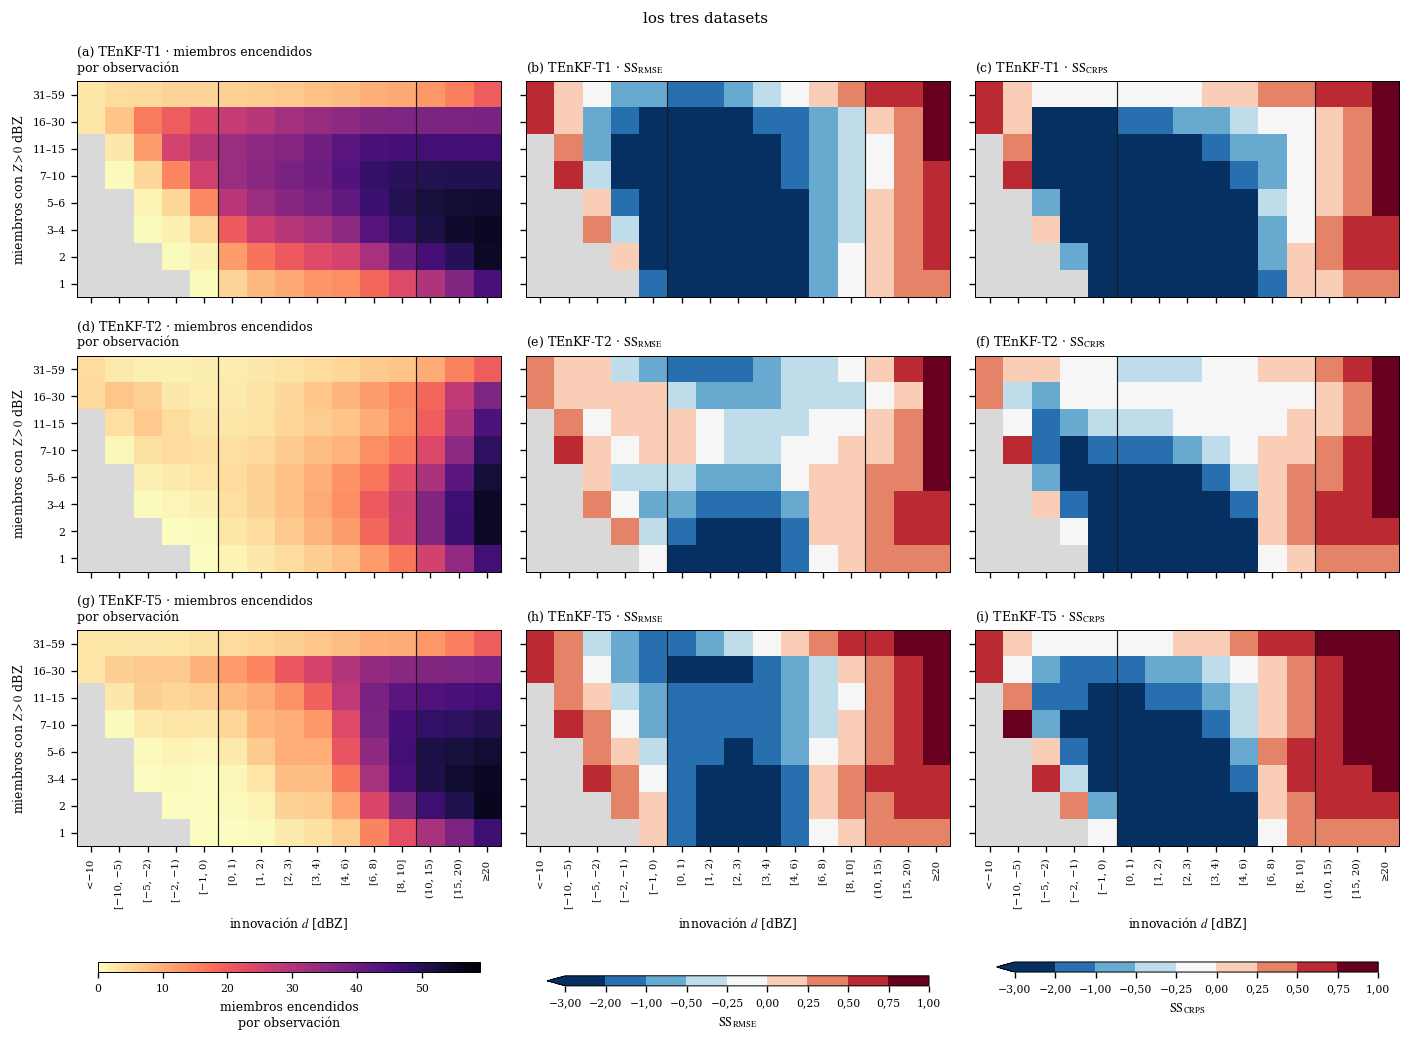

figures/es/N6_fig11_observacion_unica_A.png  figures/en/N6_fig11_single_obs_A.png
figures/es/N6_fig11_observacion_unica_B.png  figures/en/N6_fig11_single_obs_B.png
figures/es/N6_fig11_observacion_unica_C.png  figures/en/N6_fig11_single_obs_C.png
figures/es/N6_fig12_observacion_unica_conteos.png  figures/en/N6_fig12_single_obs_counts.png


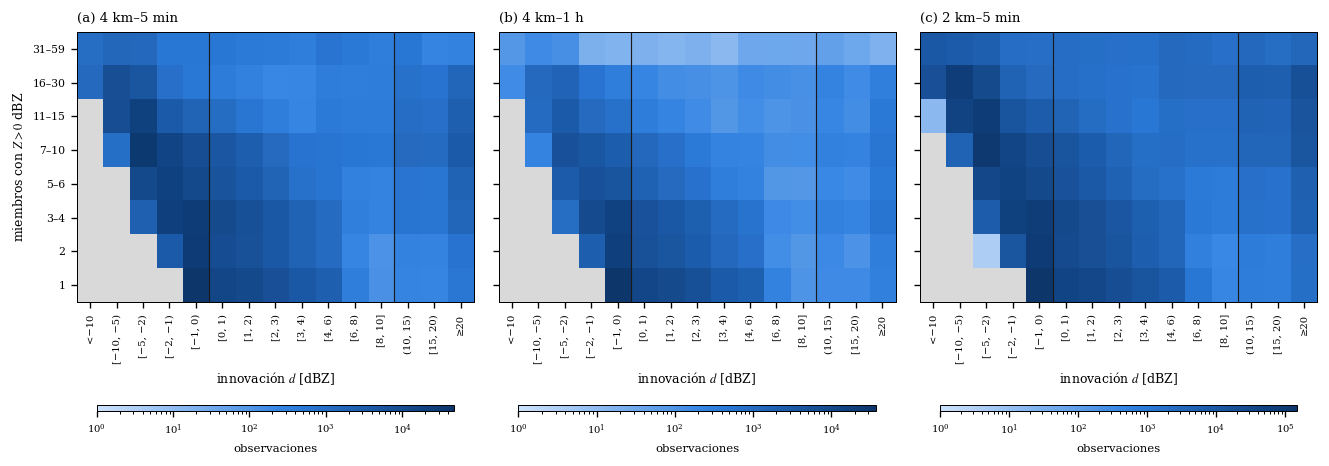

In [48]:
from matplotlib.colors import LogNorm

HEAT_SS_NORM = BoundaryNorm([-3, -2, -1, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1], 256)


def heat(ax, A, cmap, norm):
    ax.set_facecolor("0.85")
    ax.grid(False)
    im = ax.imshow(np.ma.masked_invalid(A), origin="lower", aspect="auto", cmap=cmap, norm=norm, interpolation="nearest")
    for c in (DBIN_BAND[0] - 0.5, DBIN_BAND[1] + 0.5):
        ax.axvline(c, color="0.1", lw=0.7)
    ax.set_xticks(range(len(D_FINE)))
    ax.set_xticklabels(D_FINE, rotation=90, fontsize=6)
    ax.set_yticks(range(len(N_FINE)))
    ax.set_yticklabels(N_FINE, fontsize=6.5)
    return im


def draw_fig11(lang, name="ABC"):
    V, L = nb.VOCAB[lang], LABELS[lang]
    H = HEAT[name]
    cols = (("enc/obs", L["on_per_obs"], "magma_r", plt.Normalize(0, NE_FINE[-1] - 1), "neither"),
            ("SS_RMSE", V["ss_rmse"], nb.CMAP_SKILL, HEAT_SS_NORM, "min"),
            ("SS_CRPS", V["ss_crps"], nb.CMAP_SKILL, HEAT_SS_NORM, "min"))
    fig, axes = plt.subplots(len(T12_SCH), len(cols), sharex=True, sharey=True, constrained_layout=True,
                             figsize=(nb.PAGE_W * 1.7, nb.PAGE_W * 1.25))
    for r, k in enumerate(T12_SCH):
        for c, (q, ttl, cmap, norm, ext) in enumerate(cols):
            ax = axes[r, c]
            im = heat(ax, H[f"{q} {k}"], cmap, norm)
            ax.set_title(f"({'abcdefghi'[r * len(cols) + c]}) TEnKF-{k} · {ttl}", loc="left", fontsize=7.5)
            if r == len(T12_SCH) - 1:
                cb = fig.colorbar(im, ax=axes[:, c], location="bottom", shrink=0.9, aspect=25, extend=ext)
                cb.ax.tick_params(labelsize=6.5)
                cb.set_label(ttl, fontsize=7.5)
                ax.set_xlabel(V["innov"], fontsize=7.5)
        axes[r, 0].set_ylabel(V["n_echo"], fontsize=7.5)
    fig.suptitle(LABELS[lang]["pooled"] if name == "ABC" else DSL[name], fontsize=9)
    return fig


def draw_fig12(lang):
    V, L = nb.VOCAB[lang], LABELS[lang]
    fig, axes = plt.subplots(1, len(DATASETS), sharey=True, squeeze=False, constrained_layout=True,
                             figsize=(nb.PAGE_W * 1.6, nb.PAGE_W * 0.55))
    axes = axes[0]
    for c, ds in enumerate(DATASETS):
        A = HEAT[ds]["count"]
        im = heat(axes[c], np.where(A > 0, A, np.nan), nb.CMAP_SEQ, LogNorm(vmin=1, vmax=np.nanmax(A)))
        axes[c].set_title(f"({'abc'[c]}) {DSL[ds]}", loc="left", fontsize=8)
        axes[c].set_xlabel(V["innov"], fontsize=7.5)
        cb = fig.colorbar(im, ax=axes[c], location="bottom", shrink=0.9, aspect=20)
        cb.set_label(L["single_counts"], fontsize=7)
        cb.ax.tick_params(labelsize=6)
    axes[0].set_ylabel(V["n_echo"], fontsize=7.5)
    return fig


nb.save(draw_fig11, "N6_fig11_observacion_unica", show=SHOW); plt.show()
for ds in DATASETS:
    nb.save(lambda lang: draw_fig11(lang, ds), f"N6_fig11_observacion_unica_{ds}", show=False)
nb.save(draw_fig12, "N6_fig12_observacion_unica_conteos", show=SHOW); plt.show()
